In [1]:
import os
import math
import random
import pickle
import itertools
import numpy as np
import scipy
import cv2
import cv2 as cv
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_curve, auc, accuracy_score, precision_score, recall_score, f1_score
from pywt import swt2
from collections import defaultdict
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

In [2]:
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)

# Orientation

In [3]:
def calculate_angles(im, W, smoth=False):
    j1 = lambda x, y: 2 * x * y
    j2 = lambda x, y: x ** 2 - y ** 2
    j3 = lambda x, y: x ** 2 + y ** 2

    (y, x) = im.shape

    #print(im)

    sobelOperator = [[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]]
    ySobel = np.array(sobelOperator).astype(int)  # Fixed
    xSobel = np.transpose(ySobel).astype(int)  # Fixed


    result = [[] for i in range(1, y, W)]

    Gx_ = cv.filter2D(im/125,-1, ySobel)*125
    Gy_ = cv.filter2D(im/125,-1, xSobel)*125

    # print(Gx_)
    # print(Gy_)

    for j in range(1, y, W):
        for i in range(1, x, W):
            nominator = 0
            denominator = 0
            for l in range(j, min(j + W, y - 1)):
                for k in range(i, min(i + W , x - 1)):
                    Gx = round(Gx_[l, k])  # horizontal gradients at l, k
                    Gy = round(Gy_[l, k])  # vertial gradients at l, k
                    nominator += j1(Gx, Gy)
                    denominator += j2(Gx, Gy)

            # nominator = round(np.sum(Gy_[j:min(j + W, y - 1), i:min(i + W , x - 1)]))
            # denominator = round(np.sum(Gx_[j:min(j + W, y - 1), i:min(i + W , x - 1)]))
            if nominator or denominator:
                angle = (math.pi + math.atan2(nominator, denominator)) / 2
                orientation = np.pi/2 + math.atan2(nominator,denominator)/2
                result[int((j-1) // W)].append(angle)
            else:
                result[int((j-1) // W)].append(0)

            # segment image
            # focus_img = im[j:min(j + W, y - 1), i:min(i + W , x - 1)]
            # segmentator = -1 if segmentator/W*W < np.max(focus_img)*

    result = np.array(result)

    if smoth:
        result = smooth_angles(result)

    return result


def gauss(x, y):
    ssigma = 1.0
    return (1 / (2 * math.pi * ssigma)) * math.exp(-(x * x + y * y) / (2 * ssigma))


def kernel_from_function(size, f):
    kernel = [[] for i in range(0, size)]
    for i in range(0, size):
        for j in range(0, size):
            kernel[i].append(f(i - size / 2, j - size / 2))
    return kernel


def smooth_angles(angles):
    angles = np.array(angles)
    cos_angles = np.cos(angles.copy()*2)
    sin_angles = np.sin(angles.copy()*2)

    kernel = np.array(kernel_from_function(5, gauss))

    cos_angles = cv.filter2D(cos_angles/125,-1, kernel)*125
    sin_angles = cv.filter2D(sin_angles/125,-1, kernel)*125
    smooth_angles = np.arctan2(sin_angles, cos_angles)/2

    return smooth_angles


def get_line_ends(i, j, W, tang):
    if -1 <= tang and tang <= 1:
        begin = (i, int((-W/2) * tang + j + W/2))
        end = (i + W, int((W/2) * tang + j + W/2))
    else:
        begin = (int(i + W/2 + W/(2 * tang)), j + W//2)
        end = (int(i + W/2 - W/(2 * tang)), j - W//2)
    return (begin, end)


def visualize_angles(im, mask, angles, W):
    (y, x) = im.shape
    result = cv.cvtColor(np.zeros(im.shape, np.uint8), cv.COLOR_GRAY2RGB)
    mask_threshold = (W-1)**2
    for i in range(1, x, W):
        for j in range(1, y, W):
            radian = np.sum(mask[j - 1:j + W, i-1:i+W])
            if radian > mask_threshold:
                tang = math.tan(angles[(j - 1) // W][(i - 1) // W])
                (begin, end) = get_line_ends(i, j, W, tang)
                cv.line(result, begin, end, color=150)

    cv.resize(result, im.shape, result)
    return result

# Gabor Filter

In [4]:
def gabor_filter(im, orient, freq, kx=0.65, ky=0.65):
    """
    Gabor filter is a linear filter used for edge detection. Gabor filter can be viewed as a sinusoidal plane of
    particular frequency and orientation, modulated by a Gaussian envelope.
    :param im:
    :param orient:
    :param freq:
    :param kx:
    :param ky:
    :return:
    """
    angleInc = 3
    im = np.double(im)
    rows, cols = im.shape
    return_img = np.zeros((rows,cols))

    # Round the array of frequencies to the nearest 0.01 to reduce the
    # number of distinct frequencies we have to deal with.
    freq_1d = freq.flatten()
    frequency_ind = np.array(np.where(freq_1d>0))
    non_zero_elems_in_freq = freq_1d[frequency_ind]
    non_zero_elems_in_freq = np.double(np.round((non_zero_elems_in_freq*100)))/100
    unfreq = np.unique(non_zero_elems_in_freq)

    # Generate filters corresponding to these distinct frequencies and
    # orientations in 'angleInc' increments.
    sigma_x = 1/unfreq*kx
    sigma_y = 1/unfreq*ky
    block_size = int(np.round(3*np.max([sigma_x, sigma_y])))

    array = np.linspace(-block_size,block_size,(2*block_size + 1))
    x, y = np.meshgrid(array, array)

    # gabor filter equation
    reffilter = np.exp(-(((np.power(x,2))/(sigma_x*sigma_x) + (np.power(y,2))/(sigma_y*sigma_y)))) * np.cos(2*np.pi*unfreq[0]*x)
    filt_rows, filt_cols = reffilter.shape
    gabor_filter = np.array(np.zeros((180//angleInc, filt_rows, filt_cols)))

    # Generate rotated versions of the filter.
    for degree in range(0,180//angleInc):
        rot_filt = scipy.ndimage.rotate(reffilter,-(degree*angleInc + 90),reshape = False)
        gabor_filter[degree] = rot_filt

    # Convert orientation matrix values from radians to an index value that corresponds to round(degrees/angleInc)
    maxorientindex = np.round(180/angleInc)
    orientindex = np.round(orient/np.pi*180/angleInc)
    for i in range(0,rows//16):
        for j in range(0,cols//16):
            if(orientindex[i][j] < 1):
                orientindex[i][j] = orientindex[i][j] + maxorientindex
            if(orientindex[i][j] > maxorientindex):
                orientindex[i][j] = orientindex[i][j] - maxorientindex

    # Find indices of matrix points greater than maxsze from the image boundary
    block_size = int(block_size)
    valid_row, valid_col = np.where(freq>0)
    finalind = \
        np.where((valid_row>block_size) & (valid_row<rows - block_size) & (valid_col>block_size) & (valid_col<cols - block_size))

    for k in range(0, np.shape(finalind)[1]):
        r = valid_row[finalind[0][k]]; c = valid_col[finalind[0][k]]
        img_block = im[r-block_size:r+block_size + 1][:,c-block_size:c+block_size + 1]
        return_img[r][c] = np.sum(img_block * gabor_filter[int(orientindex[r//16][c//16]) - 1])

    gabor_img = 255 - np.array((return_img < 0)*255).astype(np.uint8)

    return gabor_img

# Segmentation

In [5]:
def normalise(img):
    return (img - np.mean(img))/(np.std(img))


def create_segmented_and_variance_images(im, w, threshold=.2):
    """
    Returns mask identifying the ROI. Calculates the standard deviation in each image block and threshold the ROI
    It also normalises the intesity values of
    the image so that the ridge regions have zero mean, unit standard
    deviation.
    :param im: Image
    :param w: size of the block
    :param threshold: std threshold
    :return: segmented_image
    """
    (y, x) = im.shape
    threshold = np.std(im)*threshold

    image_variance = np.zeros(im.shape)
    segmented_image = im.copy()
    mask = np.ones_like(im)

    for i in range(0, x, w):
        for j in range(0, y, w):
            box = [i, j, min(i + w, x), min(j + w, y)]
            block_stddev = np.std(im[box[1]:box[3], box[0]:box[2]])
            image_variance[box[1]:box[3], box[0]:box[2]] = block_stddev

    # apply threshold
    mask[image_variance < threshold] = 0

    # smooth mask with a open/close morphological filter
    kernel = cv.getStructuringElement(cv.MORPH_ELLIPSE,(w*2, w*2))
    mask = cv.morphologyEx(mask, cv.MORPH_OPEN, kernel)
    mask = cv.morphologyEx(mask, cv.MORPH_CLOSE, kernel)

    # normalize segmented image
     # Normalize segmented image
    segmented_image *= mask
    im = normalise(im)

    # Ensure that mask is not empty
    masked_pixels = im[mask == 0]

    if masked_pixels.size == 0:
        mean_val = np.mean(im)
        std_val = np.std(im)
    else:
        mean_val = np.mean(masked_pixels)
        std_val = np.std(masked_pixels)

    # Avoid division by zero
    std_val = std_val if std_val > 1e-6 else 1e-6

    norm_img = (im - mean_val) / std_val


    return segmented_image, norm_img, mask

# Frequency

In [6]:
import scipy.ndimage

def frequest(im, orientim, kernel_size, minWaveLength, maxWaveLength):

    rows, cols = np.shape(im)

    # Find mean orientation within the block. This is done by averaging the
    # sines and cosines of the doubled angles before reconstructing the angle again.
    cosorient = np.cos(2*orientim) # np.mean(np.cos(2*orientim))
    sinorient = np.sin(2*orientim) # np.mean(np.sin(2*orientim))
    block_orient = math.atan2(sinorient,cosorient)/2

    # Rotate the image block so that the ridges are vertical
    rotim = scipy.ndimage.rotate(im,block_orient/np.pi*180 + 90,axes=(1,0),reshape = False,order = 3,mode = 'nearest')

    # Now crop the image so that the rotated image does not contain any invalid regions.
    cropsze = int(np.fix(rows/np.sqrt(2)))
    offset = int(np.fix((rows-cropsze)/2))
    rotim = rotim[offset:offset+cropsze][:,offset:offset+cropsze]

    # Sum down the columns to get a projection of the grey values down the ridges.
    ridge_sum = np.sum(rotim, axis = 0)
    dilation = scipy.ndimage.grey_dilation(ridge_sum, kernel_size, structure=np.ones(kernel_size))
    ridge_noise = np.abs(dilation - ridge_sum); peak_thresh = 2;
    maxpts = (ridge_noise < peak_thresh) & (ridge_sum > np.mean(ridge_sum))
    maxind = np.where(maxpts)
    _, no_of_peaks = np.shape(maxind)

    # Determine the spatial frequency of the ridges by dividing the
    # distance between the 1st and last peaks by the (No of peaks-1). If no
    # peaks are detected, or the wavelength is outside the allowed bounds, the frequency image is set to 0
    if(no_of_peaks<2):
        freq_block = np.zeros(im.shape)
    else:
        waveLength = (maxind[0][-1] - maxind[0][0])/(no_of_peaks - 1)
        if waveLength>=minWaveLength and waveLength<=maxWaveLength:
            freq_block = 1/np.double(waveLength) * np.ones(im.shape)
        else:
            freq_block = np.zeros(im.shape)
    return(freq_block)


def ridge_freq(im, mask, orient, block_size, kernel_size, minWaveLength, maxWaveLength):
    # Function to estimate the fingerprint ridge frequency across a
    # fingerprint image.
    rows,cols = im.shape
    freq = np.zeros((rows,cols))

    for row in range(0, rows - block_size, block_size):
        for col in range(0, cols - block_size, block_size):
            image_block = im[row:row + block_size][:, col:col + block_size]
            angle_block = orient[row // block_size][col // block_size]
            if angle_block:
                freq[row:row + block_size][:, col:col + block_size] = frequest(image_block, angle_block, kernel_size,
                                                                               minWaveLength, maxWaveLength)

    freq = freq*mask
    freq_1d = np.reshape(freq,(1,rows*cols))
    ind = np.where(freq_1d>0)
    ind = np.array(ind)
    ind = ind[1,:]
    non_zero_elems_in_freq = freq_1d[0][ind]
    medianfreq = np.median(non_zero_elems_in_freq) * mask

    return medianfreq

# Skeletonize

In [7]:
from skimage.morphology import skeletonize as skelt
from skimage.morphology import thin
def skeletonize(image_input):
    """
    https://scikit-image.org/docs/dev/auto_examples/edges/plot_skeleton.html
    Skeletonization reduces binary objects to 1 pixel wide representations.
    skeletonize works by making successive passes of the image. On each pass, border pixels are identified
    and removed on the condition that they do not break the connectivity of the corresponding object.
    :param image_input: 2d array uint8
    :return:
    """
    image = np.zeros_like(image_input)
    image[image_input == 0] = 1.0
    output = np.zeros_like(image_input)

    skeleton = skelt(image)

    """uncomment for testing"""
    # thinned = thin(image)
    # thinned_partial = thin(image, max_iter=25)
    #
    # def minu_(skeleton, name):
    #     cv.imshow('thin_'+name, output)
    #     cv.bitwise_not(output, output)
    #     minutias = calculate_minutiaes(output, kernel_size=5); cv.imshow('minu_'+name, minutias)
    # # minu_(output, 'skeleton')
    # # minu_(output, 'thinned')
    # # minu_(output, 'thinned_partial')
    # # cv.waitKeyEx()

    output[skeleton] = 255
    cv.bitwise_not(output, output)

    return output


def thinning_morph(image, kernel):
    """
    Thinning image using morphological operations
    :param image: 2d array uint8
    :param kernel: 3x3 2d array unint8
    :return: thin images
    """
    thining_image = np.zeros_like(image)
    img = image.copy()

    while 1:
        erosion = cv.erode(img, kernel, iterations = 1)
        dilatate = cv.dilate(erosion, kernel, iterations = 1)

        subs_img = np.subtract(img, dilatate)
        cv.bitwise_or(thining_image, subs_img, thining_image)
        img = erosion.copy()

        done = (np.sum(img) == 0)

        if done:
          break

    # shift down and compare one pixel offset
    down = np.zeros_like(thining_image)
    down[1:-1, :] = thining_image[0:-2, ]
    down_mask = np.subtract(down, thining_image)
    down_mask[0:-2, :] = down_mask[1:-1, ]
    cv.imshow('down', down_mask)

    # shift right and compare one pixel offset
    left = np.zeros_like(thining_image)
    left[:, 1:-1] = thining_image[:, 0:-2]
    left_mask = np.subtract(left, thining_image)
    left_mask[:, 0:-2] = left_mask[:, 1:-1]
    cv.imshow('left', left_mask)

    # combine left and down mask
    cv.bitwise_or(down_mask, down_mask, thining_image)
    output = np.zeros_like(thining_image)
    output[thining_image < 250] = 255

    return output

# Minutiae Matching Pipeline

In [8]:
def wrap_angle_deg_180(a):
    """Wrap angle (deg) to [-90, 90). Accepts scalar or array."""
    a = np.asarray(a, dtype=float)
    wrapped = ((a + 90.0) % 180.0) - 90.0
    return wrapped

def angle_diff_deg_mod180(a_deg, b_deg):
    """Minimal absolute difference between two angles (degrees) considering 180 deg symmetry."""
    d = wrap_angle_deg_180(a_deg - b_deg)
    return np.abs(d)

In [9]:
import matplotlib.pyplot as plt
from skimage.morphology import skeletonize

def preprocess_fingerprint(image_path):
    original = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    enhanced = clahe.apply(original)
    binary = cv2.adaptiveThreshold(enhanced, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                                   cv2.THRESH_BINARY, 11, 2)
    blurred = cv2.GaussianBlur(binary, (3, 3), 0)
    sharpened = cv2.addWeighted(binary, 1.5, blurred, -0.5, 0)
    return sharpened

# -------------------------------
# Minutiae detection
# -------------------------------
def minutiae_at(pixels, i, j, kernel_size=3):
    if pixels[i][j] == 1:
        if kernel_size == 3:
            cells = [(-1, -1), (-1, 0), (-1, 1),
                     (0, 1),  (1, 1),  (1, 0),
                     (1, -1), (0, -1), (-1, -1)]
        else:
            cells = [(-2, -2), (-2, -1), (-2, 0), (-2, 1), (-2, 2),
                     (-1, 2), (0, 2),  (1, 2),  (2, 2), (2, 1), (2, 0),
                     (2, -1), (2, -2), (1, -2), (0, -2), (-1, -2), (-2, -2)]
        values = [int(pixels[i + l][j + k]) for k, l in cells]
        crossings = sum(abs(values[k] - values[k+1]) for k in range(len(values)-1)) // 2
        if crossings == 1: return "ending"
        if crossings == 3: return "bifurcation"
    return "none"

def calculate_minutiaes(im, angles_map, kernel_size=3, border_margin=16):
    binary_image = (im > 0).astype(np.uint8)
    h, w = im.shape
    result = cv2.cvtColor(binary_image * 255, cv2.COLOR_GRAY2RGB)
    colors = {"ending": (150, 0, 0), "bifurcation": (0, 150, 0)}
    minutiae_list = []
    block_size = h // angles_map.shape[0]
    ys, xs = np.where(binary_image == 1)
    for i, j in zip(ys, xs):
        if i < border_margin or i >= h - border_margin or j < border_margin or j >= w - border_margin:
            continue
        m_type = minutiae_at(binary_image, i, j, kernel_size)
        if m_type != "none":
            angle_i, angle_j = i // block_size, j // block_size
            angle = math.degrees(angles_map[angle_i][angle_j]) if 0 <= angle_i < angles_map.shape[0] and 0 <= angle_j < angles_map.shape[1] else 0
            minutiae_list.append({'x': j, 'y': i, 'angle': angle, 'type': m_type})
            cv2.circle(result, (j, i), radius=2, color=colors[m_type], thickness=2)
    return result, minutiae_list

# -------------------------------
# Matching
# -------------------------------

import numpy as np
from scipy.spatial import KDTree

def match_minutiae(min1, min2, dist_thresh=20, angle_thresh=25):
    matches = []
    used = set()

    if len(min1) == 0 or len(min2) == 0:
        return matches

    coords1 = np.array([[m['x'], m['y'], m['angle']] for m in min1])
    coords2 = np.array([[m['x'], m['y'], m['angle']] for m in min2])

    # Build KD-Tree on spatial coordinates of min2
    tree = KDTree(coords2[:, :2])

    for i, m1 in enumerate(coords1):
        # Query all neighbors within distance threshold
        candidate_idxs = tree.query_ball_point(m1[:2], r=dist_thresh)

        if not candidate_idxs:
            continue

        best_j = None
        best_dist = np.inf

        for j in candidate_idxs:
            if j in used:
                continue

            # Angle difference (circular)
            ang_diff = abs(coords2[j, 2] - m1[2]) % 360
            ang_diff = min(ang_diff, 360 - ang_diff)

            if ang_diff > angle_thresh:
                continue

            # Euclidean distance
            dist = np.linalg.norm(coords2[j, :2] - m1[:2])

            if dist < best_dist:
                best_dist = dist
                best_j = j

        if best_j is not None:
            matches.append((i, best_j))
            used.add(best_j)

    return matches

def match_score(min1, min2, matches):
    if not matches: return 0.0
    return 100.0 * len(matches)* len(matches) / (len(min1)* len(min2))

In [10]:
# -------------------------------
# Extract features once per image
# -------------------------------
def extract_minutiae_features(image_path, block_size=16):
    img = preprocess_fingerprint(image_path)

    seg, norm, mask = create_segmented_and_variance_images(img, block_size, 0.2)
    angles = calculate_angles(norm, W=block_size, smoth=False)
    freq = ridge_freq(norm, mask, angles, block_size, kernel_size=5, minWaveLength=5, maxWaveLength=15)
    gabor = gabor_filter(norm, angles, freq)

    thin = skeletonize(gabor // 255).astype(np.uint8) * 255
    minutiae_img, minutiae = calculate_minutiaes(thin, angles)

    return {
        "thin": thin,
        "angles": angles,
        "minutiae": minutiae,
    }


# -------------------------------
# Match features between 2 images
# -------------------------------
def match_features(f1, f2):
    matches = match_minutiae(f1["minutiae"], f2["minutiae"])
    score = match_score(f1["minutiae"], f2["minutiae"], matches)
    return score

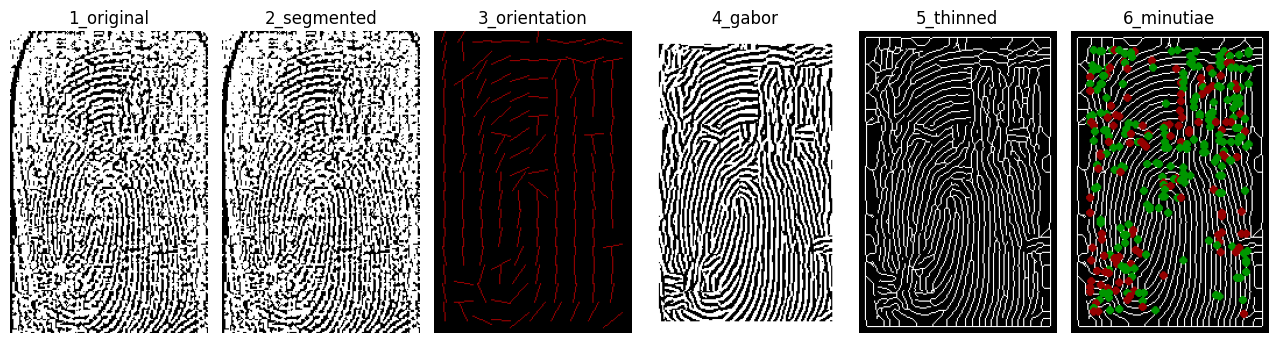

In [11]:
# -------------------------------
# Sanity Check
# -------------------------------

def fingerprint_pipeline_demo(image_path, return_all=False):
    img = preprocess_fingerprint(image_path)
    block_size = 16
    segmented_img, normim, mask = create_segmented_and_variance_images(img, block_size, 0.2)
    angles = calculate_angles(normim, W=block_size, smoth=False)
    orientation_img = visualize_angles(segmented_img, mask, angles, W=block_size)
    freq = ridge_freq(normim, mask, angles, block_size, kernel_size=5, minWaveLength=5, maxWaveLength=15)
    gabor_img = gabor_filter(normim, angles, freq)

    thin_image = skeletonize(gabor_img // 255).astype(np.uint8) * 255
    minutiae_img, minutiae = calculate_minutiaes(thin_image, angles)

    # Store all steps
    output_imgs = {
        "1_original": img,
        "2_segmented": segmented_img,
        "3_orientation": orientation_img,
        "4_gabor": gabor_img,
        "5_thinned": thin_image,
        "6_minutiae": minutiae_img
    }

    # ---- Visualization ----
    n = len(output_imgs)
    plt.figure(figsize=(15, 8))
    for i, (title, im) in enumerate(output_imgs.items(), 1):
        plt.subplot(1, n+1, i)
        plt.imshow(im, cmap="gray")
        plt.title(title)
        plt.axis("off")
    plt.tight_layout()
    plt.show()

# from google.colab import drive
# drive.mount('/content/drive')

image_path = "../BTP_SPLIT_v3/train/c1_2.png"
result_img = fingerprint_pipeline_demo(image_path)
# base_path = "drive/MyDrive/BTP-TA"

# # Loop through 200 classes
# for class_id in range(1, 201):
#     for img_id in range(1, 5):
#         image_path = os.path.join(base_path, f"c{class_id}_{img_id}.jpg")

#         # Check if file exists before processing
#         if os.path.exists(image_path):
#             print(f"Processing: {image_path}")
#             result_img = fingerprint_pipeline_demo(image_path)
#         else:
#             print(f"File not found: {image_path}")

# DL Pipeline

In [12]:
# -------------------------------
# DL Feature Generator
# -------------------------------
def extract_DL_features(image_path, block_size=16, minWaveLength=5, maxWaveLength=15, kernel_size=5):
    """
    Extract fingerprint features for a given image.

    Returns a torch tensor of shape (C, H, W) with:
      - C = 3 channels: skeleton, orientation, minutiae map
      - H = W = 96 (resized)
    """
    # Step 1: Load grayscale
    img = preprocess_fingerprint(image_path)

    # Step 2: Segmentation & Normalization
    segmented_img, normim, mask = create_segmented_and_variance_images(img, block_size, 0.2)

    # Step 3: Orientation field
    angles = calculate_angles(normim, W=block_size, smoth=False)

    # Step 4: Ridge frequency & Gabor filtering
    freq = ridge_freq(normim, mask, angles, block_size, kernel_size, minWaveLength, maxWaveLength)
    gabor_img = gabor_filter(normim, angles, freq)

    # Step 5: Skeletonization
    thin_image = skeletonize(gabor_img // 255).astype(np.uint8) * 255

    # Step 6: Orientation visualization (grayscale)
    orientation_img = cv2.cvtColor(visualize_angles(segmented_img, mask, angles, W=block_size), cv2.COLOR_BGR2GRAY)

    # Step 7: Minutiae map
    _, minutiae_list = calculate_minutiaes(thin_image, angles)
    minutiae_map = np.zeros_like(thin_image, dtype=np.float32)
    for m in minutiae_list:
        minutiae_map[m['y'], m['x']] = 1

    # Step 8: Resize & normalize each channel
    channels = []
    for ch in [thin_image, orientation_img, minutiae_map]:
        ch_resized = cv2.resize(ch, (96, 96)).astype(np.float32)
        ch_resized = (ch_resized - ch_resized.min()) / (ch_resized.max() - ch_resized.min() + 1e-8)
        channels.append(ch_resized)

    # Step 9: Stack channels and convert to torch tensor
    features = np.stack(channels, axis=-1)
    return torch.from_numpy(features).permute(2, 0, 1).float()

In [13]:
# -------------------------------
# TripleNet Model
# -------------------------------
class ChannelAttention(nn.Module):
    def __init__(self, in_channels, reduction_ratio=8):
        super().__init__()
        self.avg_pool = nn.AdaptiveAvgPool2d(1)
        self.max_pool = nn.AdaptiveMaxPool2d(1)

        self.fc = nn.Sequential(
            nn.Linear(in_channels, in_channels // reduction_ratio),
            nn.ReLU(inplace=True),
            nn.Linear(in_channels // reduction_ratio, in_channels)
        )
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        b, c, _, _ = x.size()
        avg_out = self.fc(self.avg_pool(x).view(b, c))
        max_out = self.fc(self.max_pool(x).view(b, c))
        out = avg_out + max_out
        return self.sigmoid(out).view(b, c, 1, 1) * x


class FingerprintTripleNet(nn.Module):
    def __init__(self, feature_dim=256, num_classes=None):
        super().__init__()

        self.initial_conv = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2)
        )

        self.attention1 = ChannelAttention(32)
        self.conv1 = nn.Sequential(
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2)
        )

        self.attention2 = ChannelAttention(64)
        self.conv2 = nn.Sequential(
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2)
        )

        self.attention3 = ChannelAttention(128)
        self.conv3 = nn.Sequential(
            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True),
            nn.AdaptiveAvgPool2d(1)
        )

        # bigger embedding: 256 → 512 → 256 (or keep 256 if you want)
        self.embedding = nn.Sequential(
            nn.Flatten(),
            nn.Linear(256, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(inplace=True),
            nn.Dropout(0.4),
            nn.Linear(512, feature_dim)
        )

        self.feature_dim = feature_dim
        self.num_classes = num_classes
        self.classifier = None
        if num_classes is not None:
            self.classifier = nn.Linear(feature_dim, num_classes)

    def forward_once(self, x):
        x = self.initial_conv(x)
        x = self.attention1(x)
        x = self.conv1(x)
        x = self.attention2(x)
        x = self.conv2(x)
        x = self.attention3(x)
        x = self.conv3(x)
        x = self.embedding(x)
        x = F.normalize(x, p=2, dim=1)  # keep normalized
        return x

    def embed(self, x):
        return self.forward_once(x)

    def forward(self, anchor, positive, negative):
        return (
            self.forward_once(anchor),
            self.forward_once(positive),
            self.forward_once(negative)
        )

    # helper: classification on embeddings
    def classify(self, x):
        if self.classifier is None:
            raise RuntimeError("Classifier head not initialized (num_classes=None).")
        z = self.forward_once(x)
        logits = self.classifier(z)
        return z, logits


In [24]:
# class SemiHardTripletLoss(nn.Module):
#     def __init__(self, margin=1.0):
#         super().__init__()
#         self.margin = margin

#     def forward(self, anchor, positive, negative):
#         d_ap = F.pairwise_distance(anchor, positive, p=2)
#         d_an = F.pairwise_distance(anchor, negative, p=2)

#         # Semi-hard mask
#         semi_hard_mask = (d_an > d_ap) & (d_an < d_ap + self.margin)

#         if semi_hard_mask.any():
#             d_ap = d_ap[semi_hard_mask]
#             d_an = d_an[semi_hard_mask]

#         # Standard triplet loss
#         loss = F.relu(d_ap - d_an + self.margin)
#         return loss.mean()


In [25]:
class SemiHardTripletLoss(nn.Module):
    def __init__(self, margin=0.3, fallback_to_hard=True, log_stats=False):
        super().__init__()
        self.margin = margin
        self.fallback_to_hard = fallback_to_hard
        self.log_stats = log_stats

    def forward(self, anchor, positive, negative):
        # squared L2 distances
        d_ap = (anchor - positive).pow(2).sum(dim=1)
        d_an = (anchor - negative).pow(2).sum(dim=1)

        # semi-hard: d_ap < d_an < d_ap + margin
        semi_hard_mask = (d_an > d_ap) & (d_an < d_ap + self.margin)
        num_semi = int(semi_hard_mask.sum().item())
        num_fallback_hard = 0

        if semi_hard_mask.any():
            d_ap_sh = d_ap[semi_hard_mask]
            d_an_sh = d_an[semi_hard_mask]
        else:
            # fallback: use hard negatives (d_an < d_ap)
            if self.fallback_to_hard:
                hard_mask = d_an < d_ap
                num_fallback_hard = int(hard_mask.sum().item())

                if hard_mask.any():
                    d_ap_sh = d_ap[hard_mask]
                    d_an_sh = d_an[hard_mask]
                else:
                    # no valid triplets at all
                    if self.log_stats:
                        return torch.tensor(0.0, device=anchor.device), num_semi, num_fallback_hard
                    return torch.tensor(0.0, device=anchor.device)
            else:
                if self.log_stats:
                    return torch.tensor(0.0, device=anchor.device), num_semi, num_fallback_hard
                return torch.tensor(0.0, device=anchor.device)

        loss = F.relu(d_ap_sh - d_an_sh + self.margin).mean()

        if self.log_stats:
            return loss, num_semi, num_fallback_hard

        return loss


In [26]:
class HardTripletLoss(nn.Module):
    def __init__(self, margin=1.0, log_stats=False):
        super().__init__()
        self.margin = margin
        self.log_stats = log_stats

    def forward(self, anchor, positive, negative):
        d_ap = (anchor - positive).pow(2).sum(dim=1)
        d_an = (anchor - negative).pow(2).sum(dim=1)

        hard_mask = d_an < d_ap
        num_hard = int(hard_mask.sum().item())

        if hard_mask.any():
            d_ap = d_ap[hard_mask]
            d_an = d_an[hard_mask]

        loss = F.relu(d_ap - d_an + self.margin).mean()

        if self.log_stats:
            return loss, num_hard

        return loss


# Dataset Generation with Caching

In [27]:
class FingerprintHybridDataset(Dataset):
    def __init__(self, root_dir, split, cache_dir="feature_cache",
                 max_negative_pairs=None, shuffle_pairs=True):
        self.root_dir = os.path.join(root_dir, split)
        self.cache_path = os.path.join(cache_dir, f"{split}_cache.pkl")
        os.makedirs(cache_dir, exist_ok=True)

        # Load or build cache
        if os.path.exists(self.cache_path) and os.path.getsize(self.cache_path) > 0:
            print(f"[INFO] Loading cache: {self.cache_path}")
            with open(self.cache_path, "rb") as f:
                self.data = pickle.load(f)
        else:
            print(f"[INFO] Creating cache: {self.cache_path}")
            self.data = self._build_cache()
            with open(self.cache_path, "wb") as f:
                pickle.dump(self.data, f)

        # Generate pairs
        self.pairs = self._make_pairs(max_negative_pairs)
        if shuffle_pairs:
            random.shuffle(self.pairs)

    def _build_cache(self):
        data = {}
        for fname in os.listdir(self.root_dir):
            if not fname.lower().endswith(('.jpg', '.png', '.jpeg', '.bmp')):
                continue
            img_path = os.path.join(self.root_dir, fname)
            class_no = fname.split("_")[0]
            try:
                minutiae_feat = extract_minutiae_features(img_path)
                dl_feat = extract_DL_features(img_path)
                if minutiae_feat is None or dl_feat is None:
                    continue
            except Exception as e:
                continue
            if class_no not in data:
                data[class_no] = []
            data[class_no].append((img_path, minutiae_feat, dl_feat))
        return data

    def _make_pairs(self, max_negative_pairs=None):
        pairs = []
        classes = list(self.data.keys())

        # Genuine pairs
        for cls, items in self.data.items():
            if len(items) < 2:
                continue
            for (img1, min1, dl1), (img2, min2, dl2) in itertools.combinations(items, 2):
                pairs.append((min1, dl1, min2, dl2, 1))

        # Impostor pairs
        if max_negative_pairs is None:
            for cls1, cls2 in itertools.combinations(classes, 2):
                for (img1, min1, dl1), (img2, min2, dl2) in itertools.product(
                    self.data[cls1], self.data[cls2]
                ):
                    pairs.append((min1, dl1, min2, dl2, 0))
        else:
            seen = set()
            impostor_pairs = []
            class_combinations = list(itertools.combinations(classes, 2))
            total_possible = sum(len(self.data[c1]) * len(self.data[c2]) for c1, c2 in class_combinations)
            if max_negative_pairs > total_possible:
                max_negative_pairs = total_possible
            while len(impostor_pairs) < max_negative_pairs:
                cls1, cls2 = random.choice(class_combinations)
                item1 = random.choice(self.data[cls1])
                item2 = random.choice(self.data[cls2])
                pair_key = tuple(sorted([item1[0], item2[0]]))
                if pair_key in seen:
                    continue
                seen.add(pair_key)
                impostor_pairs.append((item1[1], item1[2], item2[1], item2[2], 0))
            pairs.extend(impostor_pairs)
        return pairs

    def __getitem__(self, idx):
        min1, dl1, min2, dl2, label = self.pairs[idx]
        return (min1,
                torch.tensor(dl1, dtype=torch.float32),
                min2,
                torch.tensor(dl2, dtype=torch.float32),
                torch.tensor(label, dtype=torch.float32))

    def __len__(self):
        return len(self.pairs)

In [28]:
class FingerprintHybridTripletDataset(Dataset):
    def __init__(self, root_dir, split, cache_dir="feature_cache",
                 shuffle_triplets=True):
        self.root_dir = os.path.join(root_dir, split)
        self.cache_path = os.path.join(cache_dir, f"{split}_cache.pkl")
        os.makedirs(cache_dir, exist_ok=True)

        # Load or build cache
        if os.path.exists(self.cache_path) and os.path.getsize(self.cache_path) > 0:
            print(f"[INFO] Loading cache: {self.cache_path}")
            with open(self.cache_path, "rb") as f:
                self.data = pickle.load(f)
        else:
            print(f"[INFO] Creating cache: {self.cache_path}")
            self.data = self._build_cache()
            with open(self.cache_path, "wb") as f:
                pickle.dump(self.data, f)

        # Generate triplets
        self.triplets = self._make_triplets()
        if shuffle_triplets:
            random.shuffle(self.triplets)

    def _build_cache(self):
        data = {}
        for fname in os.listdir(self.root_dir):
            if not fname.lower().endswith(('.jpg', '.png', '.jpeg', '.bmp')):
                continue

            img_path = os.path.join(self.root_dir, fname)
            class_no = fname.split("_")[0]

            try:
                minutiae_feat = extract_minutiae_features(img_path)
                dl_feat = extract_DL_features(img_path)
                if minutiae_feat is None or dl_feat is None:
                    continue
            except Exception:
                continue

            if class_no not in data:
                data[class_no] = []
            data[class_no].append((img_path, minutiae_feat, dl_feat))
        return data

    def _make_triplets(self):
        triplets = []
        classes = list(self.data.keys())

        for cls in classes:
            items = self.data[cls]
            if len(items) < 2:
                continue

            # anchor-positive pairs
            for (a_img, a_min, a_dl), (p_img, p_min, p_dl) in itertools.permutations(items, 2):
                # negatives from other classes
                for neg_cls in classes:
                    if neg_cls == cls:
                        continue
                    for (n_img, n_min, n_dl) in self.data[neg_cls]:
                        triplets.append((
                            a_min, a_dl,
                            p_min, p_dl,
                            n_min, n_dl
                        ))
        return triplets

    def __getitem__(self, idx):
        a_min, a_dl, p_min, p_dl, n_min, n_dl = self.triplets[idx]
        return (
            a_min,
            torch.tensor(a_dl, dtype=torch.float32),
            p_min,
            torch.tensor(p_dl, dtype=torch.float32),
            n_min,
            torch.tensor(n_dl, dtype=torch.float32)
        )

    def __len__(self):
        return len(self.triplets)

In [29]:
class DistanceWeightedTripletFingerprintDataset(Dataset):
    """
    Now this is NOT actually doing DW inside the dataset.
    It just loads (DL tensor, class label).
    DW / triplet mining will be done in the training loop
    using the model embeddings.
    """
    def __init__(self, root_dir,
                 cache_dir="feature_cache",
                 verbose=False):
        self.root_dir = root_dir
        self.cache_dir = cache_dir
        self.verbose = verbose

        os.makedirs(self.cache_dir, exist_ok=True)

        # cache like before, but no "flat"
        split_name = os.path.basename(os.path.normpath(root_dir))
        self.cache_path = os.path.join(self.cache_dir, f"dw_{split_name}_cache.pkl")

        if os.path.exists(self.cache_path) and os.path.getsize(self.cache_path) > 0:
            print(f"[INFO] Loading DW cache: {self.cache_path}")
            with open(self.cache_path, "rb") as f:
                cache = pickle.load(f)
            self.samples = cache["samples"]          # list of dicts
            self.indices_by_class = cache["indices_by_class"]
        else:
            print(f"[INFO] Creating DW cache: {self.cache_path}")
            self.samples, self.indices_by_class = self._build_cache()
            with open(self.cache_path, "wb") as f:
                pickle.dump(
                    {
                        "samples": self.samples,
                        "indices_by_class": self.indices_by_class,
                    },
                    f
                )

        # map class_id string -> numeric label
        self.class_to_idx = {
            cls: i for i, cls in enumerate(sorted(self.indices_by_class.keys()))
        }

        if self.verbose:
            print(f"[DW Dataset] Total samples: {len(self.samples)}")
            print(f"[DW Dataset] Num classes: {len(self.class_to_idx)}")

    def _build_cache(self):
        samples = []
        indices_by_class = {}

        for fname in os.listdir(self.root_dir):
            if not fname.lower().endswith(('.jpg', '.png', '.jpeg', '.bmp')):
                continue

            img_path = os.path.join(self.root_dir, fname)
            class_id = fname.split("_")[0]

            try:
                dl_feat = extract_DL_features(img_path)  # (3,96,96)
            except Exception as e:
                if self.verbose:
                    print(f"[DW] Skipping {fname} due to error: {e}")
                continue

            if dl_feat is None:
                continue

            if isinstance(dl_feat, torch.Tensor):
                dl_tensor = dl_feat.float().cpu()
            else:
                dl_tensor = torch.tensor(dl_feat, dtype=torch.float32)

            idx = len(samples)
            samples.append({
                "class": class_id,
                "tensor": dl_tensor,  # (3,96,96)
                "fname": fname,
            })

            if class_id not in indices_by_class:
                indices_by_class[class_id] = []
            indices_by_class[class_id].append(idx)

        return samples, indices_by_class

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        s = self.samples[idx]
        x = s["tensor"].clone().detach().float()   # (C,H,W)
        y = self.class_to_idx[s["class"]]          # numeric label
        return x, torch.tensor(y, dtype=torch.long)


In [30]:
def mine_distance_weighted_triplets_full(
    embeddings,              # [N, D]
    labels,                  # [N]
    max_triplets_per_class=50,
    candidates_per_anchor=200,
    negatives_per_pair=4     # how many negatives per (anchor, positive)
):
    """
    Global Distance-Weighted triplet mining *per class*.

    For each class:
        - Cap at max_triplets_per_class triplets
        - For each anchor in that class:
            - Consider up to `candidates_per_anchor` negatives (closest ones)
            - For each positive (same-class sample != anchor):
                - Sample up to `negatives_per_pair` negatives with DW probability

    Returns:
        a_idx, p_idx, n_idx  (each [M]) indices into `embeddings` / base_dataset
    """
    device = embeddings.device
    labels = labels.view(-1)
    N = embeddings.size(0)

    with torch.no_grad():
        # squared Euclidean distances [N, N]
        dists_sq = torch.cdist(embeddings, embeddings, p=2).pow(2) + 1e-6

    unique_labels = labels.unique()

    a_indices = []
    p_indices = []
    n_indices = []

    for cls in unique_labels:
        cls = cls.item()
        # indices of this class
        class_mask = (labels == cls)
        class_idx = torch.nonzero(class_mask, as_tuple=False).view(-1)

        # skip tiny classes
        if class_idx.numel() < 2:
            continue

        remaining_for_class = max_triplets_per_class

        # loop over anchors in this class
        for i in class_idx:
            if remaining_for_class <= 0:
                break

            # positives: same class, exclude self
            pos_idx = class_idx[class_idx != i]
            if pos_idx.numel() == 0:
                continue

            # negatives: different class
            neg_mask = labels != cls
            neg_idx_all = torch.nonzero(neg_mask, as_tuple=False).view(-1)
            if neg_idx_all.numel() == 0:
                continue

            # distances to all negatives
            d_neg_all = dists_sq[i, neg_idx_all]  # [K_all]

            # take up to `candidates_per_anchor` *closest* negatives
            if neg_idx_all.numel() > candidates_per_anchor:
                sorted_idx = torch.argsort(d_neg_all)  # ascending distance
                cand_idx = sorted_idx[:candidates_per_anchor]
                neg_idx = neg_idx_all[cand_idx]
                d_neg = d_neg_all[cand_idx]
            else:
                neg_idx = neg_idx_all
                d_neg = d_neg_all

            # DW weights ~ 1 / d  (simple version)
            weights = 1.0 / d_neg
            weights = torch.clamp(weights, min=1e-8)
            probs = weights / weights.sum()

            # for each positive of this anchor
            for p_i in pos_idx:
                if remaining_for_class <= 0:
                    break

                # how many triplets for this (anchor, positive) pair?
                num_for_pair = min(negatives_per_pair, remaining_for_class)

                # sample that many negatives with DW probability
                # (replacement=False as long as we have enough candidates)
                replace = neg_idx.size(0) < num_for_pair
                sampled_local = torch.multinomial(probs, num_samples=num_for_pair, replacement=replace)

                for idx_local in sampled_local:
                    n_i = neg_idx[idx_local]

                    a_indices.append(i.item())
                    p_indices.append(p_i.item())
                    n_indices.append(n_i.item())

                    remaining_for_class -= 1
                    if remaining_for_class <= 0:
                        break

        # end for anchors
    # end for classes

    if len(a_indices) == 0:
        return None, None, None

    a_idx = torch.tensor(a_indices, dtype=torch.long, device=device)
    p_idx = torch.tensor(p_indices, dtype=torch.long, device=device)
    n_idx = torch.tensor(n_indices, dtype=torch.long, device=device)

    return a_idx, p_idx, n_idx


In [31]:
class GlobalDWTripletDataset(Dataset):
    def __init__(self, base_dataset, a_idx, p_idx, n_idx):
        """
        base_dataset: DistanceWeightedTripletFingerprintDataset
        a_idx, p_idx, n_idx: 1D tensors of indices into base_dataset
        """
        self.base = base_dataset
        self.a_idx = a_idx.cpu()
        self.p_idx = p_idx.cpu()
        self.n_idx = n_idx.cpu()

    def __len__(self):
        return len(self.a_idx)

    def __getitem__(self, idx):
        ia = int(self.a_idx[idx])
        ip = int(self.p_idx[idx])
        ineg = int(self.n_idx[idx])

        xa, ya = self.base[ia]   # (tensor, label)
        xp, yp = self.base[ip]
        xn, yn = self.base[ineg]

        return xa, ya, xp, yp, xn, yn


In [32]:
def build_global_dw_triplet_loader(
    model,
    base_dataset,              # train_dataset_dw
    device,
    embed_batch_size=64,
    triplet_batch_size=32,
    max_triplets_per_class=50,
    candidates_per_anchor=200,
    negatives_per_pair=4
):
    model.eval()

    # 1) get embeddings for ALL samples
    all_embs = []
    all_labels = []

    loader = DataLoader(
        base_dataset,
        batch_size=embed_batch_size,
        shuffle=False,
        num_workers=0
    )

    with torch.no_grad():
        for x, y in loader:
            x = x.to(device)
            y = y.to(device)

            z = model.embed(x)   # [B, D]
            all_embs.append(z)
            all_labels.append(y)

    embeddings = torch.cat(all_embs, dim=0)     # [N, D]
    labels = torch.cat(all_labels, dim=0)       # [N]

    # 2) global DW mining (PER CLASS)
    a_idx, p_idx, n_idx = mine_distance_weighted_triplets_full(
        embeddings,
        labels,
        max_triplets_per_class=max_triplets_per_class,
        candidates_per_anchor=candidates_per_anchor,
        negatives_per_pair=negatives_per_pair
    )

    if a_idx is None:
        print("[WARN] No DW triplets mined!")
        return None

    print(f"[DW] Mined {len(a_idx)} triplets for this epoch.")

    # 3) build triplet dataset + loader
    triplet_dataset = GlobalDWTripletDataset(base_dataset, a_idx, p_idx, n_idx)

    triplet_loader = DataLoader(
        triplet_dataset,
        batch_size=triplet_batch_size,
        shuffle=True,
        num_workers=0
    )

    return triplet_loader


# Model Training with Minutiae Matching

In [33]:
from torch.utils.data import DataLoader
from torch.optim import AdamW
from torch.amp import autocast, GradScaler
from tqdm import tqdm
from sklearn.metrics import roc_curve
import matplotlib.pyplot as plt

In [34]:
def collate_fn(batch):
    # Remove None entries
    batch = [b for b in batch if b is not None]
    if len(batch) == 0:
        return None
    # Transpose
    min1_list, dl1_list, min2_list, dl2_list, labels = zip(*batch)
    dl1_tensor = torch.stack([torch.tensor(x, dtype=torch.float32) for x in dl1_list])
    dl2_tensor = torch.stack([torch.tensor(x, dtype=torch.float32) for x in dl2_list])
    labels_tensor = torch.tensor(labels, dtype=torch.float32)
    return min1_list, dl1_tensor, min2_list, dl2_tensor, labels_tensor


scaler = GradScaler("cuda")   # ✅ pass device type explicitly

# =========================
# Dataset & DataLoaders
# =========================
dataset_root = "../BTP_SPLIT_PolyU_v3/"
cache_dir = "feature_cache_imp_polyU/"

# -------------------------
# TRAIN: random + DW triplets
# -------------------------
# Warmup dataset: your original random triplet sampling

# Distance-weighted negative mining dataset
train_dataset_dw = DistanceWeightedTripletFingerprintDataset(
    root_dir=os.path.join(dataset_root, "train"),
    cache_dir=cache_dir,
    verbose=False
)


train_loader_dw = DataLoader(
    train_dataset_dw,
    batch_size=16,
    shuffle=True,
    num_workers=0
)

# -------------------------
# VAL / TEST: unchanged
# -------------------------
val_dataset = FingerprintHybridDataset(
    root_dir=dataset_root,
    split='val',
    cache_dir=cache_dir,
    max_negative_pairs=180,
    shuffle_pairs=False
)

test_dataset = FingerprintHybridDataset(
    root_dir=dataset_root,
    split='test',
    cache_dir=cache_dir,
    shuffle_pairs=False
)

val_loader = DataLoader(
    val_dataset,
    batch_size=4,
    shuffle=False,
    num_workers=0,
    collate_fn=collate_fn
)

test_loader = DataLoader(
    test_dataset,
    batch_size=4,
    shuffle=False,
    num_workers=0,
    collate_fn=collate_fn
)


[INFO] Loading DW cache: feature_cache_imp_polyU/dw_train_cache.pkl
[INFO] Loading cache: feature_cache_imp_polyU/val_cache.pkl
[INFO] Loading cache: feature_cache_imp_polyU/test_cache.pkl


In [35]:
def mine_distance_weighted_triplets(embeddings, labels, min_pos=1, candidates_per_anchor=200):
    """
    embeddings: [B, D] (normalized or not)
    labels: [B]
    Returns index tensors a_idx, p_idx, n_idx (all shape [M])
    """
    device = embeddings.device
    B = embeddings.size(0)
    labels = labels.view(-1)

    # pairwise distances (Euclidean)
    # [B, B]
    with torch.no_grad():
        # squared distances
        dists_sq = torch.cdist(embeddings, embeddings, p=2).pow(2)  # [B,B]

    a_indices = []
    p_indices = []
    n_indices = []

    for i in range(B):
        anchor_label = labels[i]

        # positives: same class, exclude self
        pos_mask = (labels == anchor_label)
        pos_mask[i] = False
        pos_idx = torch.nonzero(pos_mask, as_tuple=False).view(-1)

        if pos_idx.numel() < min_pos:
            continue  # cannot form triplet for this anchor

        # choose one positive randomly
        p_i = pos_idx[torch.randint(0, pos_idx.numel(), (1,)).item()]

        # negatives: different class
        neg_mask = labels != anchor_label
        neg_idx_all = torch.nonzero(neg_mask, as_tuple=False).view(-1)

        if neg_idx_all.numel() == 0:
            continue

        # subsample candidates
        if neg_idx_all.numel() > candidates_per_anchor:
            perm = torch.randperm(neg_idx_all.numel(), device=device)
            neg_idx_all = neg_idx_all[perm[:candidates_per_anchor]]

        # distances to candidate negatives
        dists = dists_sq[i, neg_idx_all] + 1e-6  # [K]

        # DW weights ~ 1 / d^2
        weights = 1.0 / dists
        weights = torch.clamp(weights, min=1e-8)
        probs = weights / weights.sum()

        # sample one negative index using probs
        n_local = torch.multinomial(probs, 1).item()
        n_i = neg_idx_all[n_local]

        a_indices.append(i)
        p_indices.append(p_i.item())
        n_indices.append(n_i.item())

    if len(a_indices) == 0:
        # fallback: no triplets
        return None, None, None

    a_idx = torch.tensor(a_indices, dtype=torch.long, device=device)
    p_idx = torch.tensor(p_indices, dtype=torch.long, device=device)
    n_idx = torch.tensor(n_indices, dtype=torch.long, device=device)
    return a_idx, p_idx, n_idx


In [36]:
def compute_hybrid_eer_normalized(model, dataloader, device="cuda"):
    """
    Computes hybrid EER by searching best alpha in range 0.05 ... 1.0.
    Returns: best_eer, best_threshold, best_alpha
    """
    model.eval()

    # Store raw scores separately
    raw_dl_scores = []
    raw_min_scores = []
    all_labels = []

    print("Computing scores (one-time extraction)...")
    with torch.no_grad():
        for batch in tqdm(dataloader, desc="Eval"):
            if batch is None:
                continue

            min1, dl1, min2, dl2, label = batch
            dl1, dl2 = dl1.to(device), dl2.to(device)

            # Deep-learning embeddings
            out1 = model.embed(dl1)
            out2 = model.embed(dl2)

            dl_sim = F.cosine_similarity(out1, out2).cpu().numpy()

            # Minutiae similarity
            min_sim = np.array([match_features(m1, m2) for m1, m2 in zip(min1, min2)])

            raw_dl_scores.extend(dl_sim)
            raw_min_scores.extend(min_sim)
            all_labels.extend(label.numpy().tolist())

    # Convert to arrays
    dl_scores = np.array(raw_dl_scores)
    min_scores = np.array(raw_min_scores)
    labels = np.array(all_labels)

    # -------------------------------
    # NORMALIZATION
    # -------------------------------
    dl_norm = (dl_scores+1)/2
    min_norm = min_scores/100

    print("\n=== RAW SCORE STATS ===")
    print(f"DL Scores   : min={dl_scores.min():.4f}, max={dl_scores.max():.4f}")
    print(f"Min Scores  : min={min_scores.min():.4f}, max={min_scores.max():.4f}")

    print("\nSample Raw DL Scores:", dl_scores[:10])
    print("Sample Raw Min Scores:", min_scores[:10])

    print("\n=== NORMALIZED SCORES ===")
    print("Sample DL_norm:", dl_norm[:10])
    print("Sample Min_norm:", min_norm[:10])

    # -------------------------------
    # SEARCH FOR BEST ALPHA
    # -------------------------------
    alpha_values = np.arange(0.00, 1.01, 0.01)

    best_eer = 1.0
    best_threshold = None
    best_alpha = None

    for alpha in alpha_values:
        combined_scores = alpha * dl_norm + (1 - alpha) * min_norm

        fpr, tpr, thresholds = roc_curve(labels, combined_scores)
        fnr = 1 - tpr
        eer_idx = np.nanargmin(np.abs(fpr - fnr))

        eer = (fpr[eer_idx] + fnr[eer_idx]) / 2
        eer_threshold = thresholds[eer_idx]

        # track best alpha
        print(f"\nAlpha = {alpha:.2f}")
        print(f"EER   = {eer:.4f}")
        print(f"Threshold  = {eer_threshold:.4f}")
        if eer < best_eer:
            best_eer = eer
            best_threshold = eer_threshold
            best_alpha = alpha

    print(f"\nBest Alpha = {best_alpha:.2f}")
    print(f"Best EER   = {best_eer:.4f}")
    print(f"Threshold  = {best_threshold:.4f}")

    # -------------------------------
    # Visualization for best alpha
    # -------------------------------
    combined_scores = best_alpha * dl_norm + (1 - best_alpha) * min_norm
    fpr, tpr, thresholds = roc_curve(labels, combined_scores)
    fnr = 1 - tpr
    eer_idx = np.nanargmin(np.abs(fpr - fnr))

    plt.figure(figsize=(8, 6))
    plt.plot(fpr, tpr, label=f"Hybrid (Best α={best_alpha:.2f})")
    plt.plot([0, 1], [0, 1], 'k--', alpha=0.5)
    plt.scatter(fpr[eer_idx], tpr[eer_idx], c="red",
                label=f"EER={best_eer:.4f}")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title("Hybrid ROC Curve – Best Alpha Selection")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()

    return best_eer, best_threshold, best_alpha, combined_scores

In [37]:
# tune_hyperparams.py
import os
import csv
import json
import copy
import time
import random
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.optim import AdamW
from tqdm import tqdm

# --------- Assumptions ----------
# - Your existing file defines:
#   FingerprintTripleNet, train_dataset_dw, val_loader, test_loader,
#   build_global_dw_triplet_loader, compute_hybrid_eer_normalized, set_seed
# - If names differ, adapt below.
# --------------------------------

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def compute_distance_stats(model, base_dataset, device=DEVICE, embed_batch_size=64, sample_limit=None):
    """
    Compute distance statistics using squared L2 distances (consistent with your losses).

    Returns a dict with:
      - median_d_ap: median (over anchors) of mean anchor->positives squared distances
      - median_d_an: median (over anchors) of mean anchor->negatives squared distances
      - gap: median_d_an - median_d_ap
      - p10_ap: 10th percentile (over anchors) of anchor->positive means
      - p90_an: 90th percentile (over anchors) of anchor->negative means

    Notes:
      - Uses squared L2 distances to match your losses that use (x - y).pow(2).sum(dim=1).
      - Aggregation: per-anchor mean for positives and negatives, then take median/percentiles
        across anchors for robust summary stats.
    """
    model.eval()
    loader = torch.utils.data.DataLoader(base_dataset, batch_size=embed_batch_size, shuffle=False, num_workers=0)
    emb_list = []
    label_list = []
    with torch.no_grad():
        for x, y in loader:
            x = x.to(device)
            z = model.embed(x)          # [B, D], expected already normalized if using F.normalize
            emb_list.append(z.cpu())
            label_list.append(y.cpu())
            if sample_limit is not None and sum([t.size(0) for t in emb_list]) >= sample_limit:
                break

    if len(emb_list) == 0:
        return None

    embeddings = torch.cat(emb_list, dim=0)   # [N, D] (on CPU)
    labels = torch.cat(label_list, dim=0).numpy()  # [N] as numpy for indexing
    N = embeddings.size(0)

    # compute L2 distances then square them so units = squared L2
    with torch.no_grad():
        # torch.cdist returns L2 distances; square to match losses
        dists = torch.cdist(embeddings, embeddings, p=2).pow(2).numpy()  # shape [N, N], numpy

    ap_per_anchor = []   # mean squared positive distance per anchor
    an_per_anchor = []   # mean (or median) squared negative distance per anchor

    for i in range(N):
        li = labels[i]
        pos_idx = np.where(labels == li)[0]
        pos_idx = pos_idx[pos_idx != i]
        if pos_idx.size > 0:
            # mean squared distance to positives for anchor i
            mean_pos = float(dists[i, pos_idx].mean())
            ap_per_anchor.append(mean_pos)
        # negatives
        neg_idx = np.where(labels != li)[0]
        if neg_idx.size > 0:
            # mean (or median) squared distance to negatives for anchor i
            mean_neg = float(np.median(dists[i, neg_idx]))  # median per-anchor negative (robust)
            an_per_anchor.append(mean_neg)

    if len(ap_per_anchor) == 0 or len(an_per_anchor) == 0:
        return None

    ap_arr = np.array(ap_per_anchor)
    an_arr = np.array(an_per_anchor)

    median_d_ap = float(np.median(ap_arr))
    median_d_an = float(np.median(an_arr))
    gap = median_d_an - median_d_ap

    # percentiles for margin design
    p10_ap = float(np.percentile(ap_arr, 10))
    p90_an = float(np.percentile(an_arr, 90))

    stats = {
        "median_d_ap": median_d_ap,
        "median_d_an": median_d_an,
        "gap": gap,
        "p10_ap": p10_ap,
        "p90_an": p90_an,
        # also return the raw arrays if you want to do more analysis (optional)
        # "ap_arr": ap_arr, "an_arr": an_arr
    }
    return stats


In [38]:
def compute_margin_from_dw_triplets(
    model,
    train_dataset_dw,
    device,
    embed_batch_size=64,
    triplet_batch_size=16,
    max_triplets_per_class=50,
    candidates_per_anchor=200,
    negatives_per_pair=8,
    margin_mode="percentile",   # "median" or "percentile"
):
    """
    Compute margin directly from DW-mined triplets.

    Returns:
        margin (float), stats dict
    """

    model.eval()

    # 1) Mine DW triplets using CURRENT model
    triplet_loader = build_global_dw_triplet_loader(
        model,
        train_dataset_dw,
        device=device,
        embed_batch_size=embed_batch_size,
        triplet_batch_size=triplet_batch_size,
        max_triplets_per_class=max_triplets_per_class,
        candidates_per_anchor=candidates_per_anchor,
        negatives_per_pair=negatives_per_pair
    )

    if triplet_loader is None:
        return None, None

    ap_dists = []
    an_dists = []

    with torch.no_grad():
        for batch in triplet_loader:
            xa, ya, xp, yp, xn, yn = batch
            xa = xa.to(device)
            xp = xp.to(device)
            xn = xn.to(device)

            a = model.embed(xa)
            p = model.embed(xp)
            n = model.embed(xn)

            d_ap = (a - p).pow(2).sum(dim=1)
            d_an = (a - n).pow(2).sum(dim=1)

            ap_dists.append(d_ap.cpu())
            an_dists.append(d_an.cpu())

    if len(ap_dists) == 0:
        return None, None

    ap = torch.cat(ap_dists).numpy()
    an = torch.cat(an_dists).numpy()

    # 2) Compute margin
    if margin_mode == "median":
        margin = np.median(an) - np.median(ap)
    else:  # percentile (recommended)
        margin = np.percentile(an, 90) - np.percentile(ap, 10)

    margin = float(max(margin, 1e-6))

    stats = {
        "median_ap": float(np.median(ap)),
        "median_an": float(np.median(an)),
        "p10_ap": float(np.percentile(ap, 10)),
        "p90_an": float(np.percentile(an, 90)),
        "margin": margin,
        "num_triplets": len(ap),
    }

    return margin, stats



===== Training with seed 42 =====
🚀 No saved model found → Training from scratch!
[INFO] distance stats: {'median_d_ap': 1.9073486612342094e-07, 'median_d_an': 3.576278970740532e-07, 'gap': 1.6689303095063224e-07, 'p10_ap': 7.152557657263969e-08, 'p90_an': 4.7683712978141557e-07}
[INFO] initial margins -> hard: 1.668930e-07, semi: 1.668930e-07
{'median_d_ap': 1.9073486612342094e-07, 'median_d_an': 3.576278970740532e-07, 'gap': 1.6689303095063224e-07, 'p10_ap': 7.152557657263969e-08, 'p90_an': 4.7683712978141557e-07}
[EPOCH-1] recomputed gap: 1.668930e-07; margins -> hard: 1.668930e-07, semi: 1.668930e-07
[DW] Mined 11750 triplets for this epoch.


Epoch 1 [GLOBAL-DW / Hard+Semi+CE]: 100%|█████████████████████████| 735/735 [00:31<00:00, 23.24it/s, Batch Loss=0.4217]
C:\Users\divya\AppData\Local\Temp\ipykernel_30080\477085210.py:83: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.tensor(dl1, dtype=torch.float32),
C:\Users\divya\AppData\Local\Temp\ipykernel_30080\477085210.py:85: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.tensor(dl2, dtype=torch.float32),
C:\Users\divya\AppData\Local\Temp\ipykernel_30080\1251142332.py:8: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  dl1_t

Epoch 1 [GLOBAL-DW / Hard+Semi+CE]: Train Loss=0.4969, Val Loss=-0.8243
[LOG] semi-hard used: 0, fallback-hard: 0, hard-negatives: 580
✅ New best model at epoch 1
{'median_d_ap': 0.05771941691637039, 'median_d_an': 1.7042970657348633, 'gap': 1.646577648818493, 'p10_ap': 0.020243294537067413, 'p90_an': 2.191073989868164}
[EPOCH-2] recomputed gap: 1.646578e+00; margins -> hard: 3.000000e-01, semi: 3.000000e-01
[DW] Mined 11750 triplets for this epoch.


Epoch 2 [GLOBAL-DW / Hard+Semi+CE]: 100%|█████████████████████████| 735/735 [00:32<00:00, 22.54it/s, Batch Loss=0.6178]


Epoch 2 [GLOBAL-DW / Hard+Semi+CE]: Train Loss=0.6053, Val Loss=-0.8441
[LOG] semi-hard used: 1989, fallback-hard: 0, hard-negatives: 684
✅ New best model at epoch 2
{'median_d_ap': 0.10219110921025276, 'median_d_an': 1.5299656987190247, 'gap': 1.427774589508772, 'p10_ap': 0.04133391976356506, 'p90_an': 2.0094829559326173}
[EPOCH-3] recomputed gap: 1.427775e+00; margins -> hard: 3.000000e-01, semi: 3.000000e-01
[DW] Mined 11750 triplets for this epoch.


Epoch 3 [GLOBAL-DW / Hard+Semi+CE]: 100%|█████████████████████████| 735/735 [00:33<00:00, 21.97it/s, Batch Loss=0.3892]


... (13 outputs left out)

Epoch 10 [GLOBAL-DW / Hard+Semi+CE]: 100%|████████████████████████| 735/735 [00:34<00:00, 21.40it/s, Batch Loss=0.0715]


Epoch 10 [GLOBAL-DW / Hard+Semi+CE]: Train Loss=0.0605, Val Loss=-0.7496
[LOG] semi-hard used: 20, fallback-hard: 0, hard-negatives: 0
⚠️ No improvement for 5 epoch(s)
⏹ Early stopping triggered at epoch 10
💾 Saved best model to best_model_imp_adaptive.pth
📄 Saved config to model_config_imp_adaptive.json
Computing scores (one-time extraction)...


Eval: 100%|██████████████████████████████████████████████████████████████████████| 20757/20757 [21:59<00:00, 15.73it/s]



=== RAW SCORE STATS ===
DL Scores   : min=-0.8129, max=0.9972
Min Scores  : min=0.0182, max=78.6275

Sample Raw DL Scores: [0.98595226 0.92152524 0.94479764 0.98369515 0.9320028  0.9368712
 0.9474436  0.95841753 0.9469553  0.94201195]
Sample Raw Min Scores: [72.39154975 70.62096708 66.12520305 64.53279425 22.49431286 76.98967699
 56.14280863 68.78366731 22.9268958  57.86531349]

=== NORMALIZED SCORES ===
Sample DL_norm: [0.9929761  0.9607626  0.9723988  0.9918476  0.9660014  0.9684356
 0.9737218  0.97920877 0.97347766 0.971006  ]
Sample Min_norm: [0.7239155  0.70620967 0.66125203 0.64532794 0.22494313 0.76989677
 0.56142809 0.68783667 0.22926896 0.57865313]

Alpha = 0.00
EER   = 0.1333
Threshold  = 0.2096

Alpha = 0.05
EER   = 0.1191
Threshold  = 0.2359

Alpha = 0.10
EER   = 0.1093
Threshold  = 0.2606

Alpha = 0.15
EER   = 0.0980
Threshold  = 0.2890

Alpha = 0.20
EER   = 0.0920
Threshold  = 0.3138

Alpha = 0.25
EER   = 0.0811
Threshold  = 0.3441

Alpha = 0.30
EER   = 0.0725
Threshold 

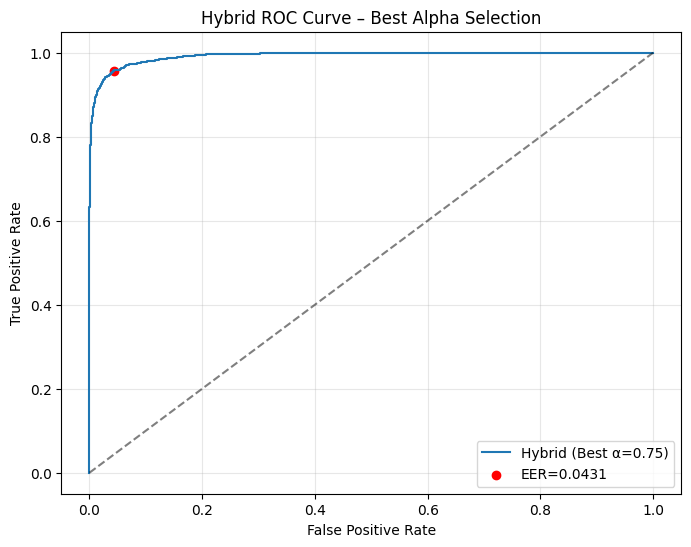

Seed 42 → Hybrid EER: 4.31% (Threshold: 0.6664, α=0.75)

Final Hybrid Result: 4.31% ± 0.00% (across 1 runs)


In [32]:
import copy
import os
import json

MODEL_PATH = "best_model_imp_adaptive.pth"    # where to save your best model
CONFIG_PATH = "model_config_imp_adaptive.json"

def run_training(seed):
    print(f"\n===== Training with seed {seed} =====")
    set_seed(seed)

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    # --------------------------------------------------
    # If model already exists → load it and skip training
    # --------------------------------------------------
    if os.path.exists(MODEL_PATH):
        print("📌 Found saved model → Loading model instead of training...")
        num_classes = len(train_dataset_dw.indices_by_class)
        model = FingerprintTripleNet(feature_dim=256, num_classes=num_classes).to(device)
        model.load_state_dict(torch.load(MODEL_PATH, map_location=device))
        model.eval()

        eer, threshold, alpha = compute_hybrid_eer_normalized(model, test_loader, device=device)
        print(f"[Loaded Model] Hybrid EER: {eer*100:.2f}% (thr={threshold:.4f}, α={alpha:.2f})")
        return eer * 100

    print("🚀 No saved model found → Training from scratch!")

    num_classes = len(train_dataset_dw.indices_by_class)
    model = FingerprintTripleNet(feature_dim=256, num_classes=num_classes).to(device)

    # --- compute pre-training distance stats (gap) using a fresh model ---
    try:
        stats = compute_distance_stats(model, train_dataset_dw, device=device, embed_batch_size=64, sample_limit=None)
    except Exception as e:
        print(f"[WARN] compute_distance_stats failed: {e}")
        stats = None

    if stats is None or "gap" not in stats or stats["gap"] <= 0.0:
        gap = 1e-4
        print("[WARN] Using fallback gap =", gap)
    else:
        gap = float(stats["gap"])
        print(f"[INFO] distance stats: {stats}")

    # Multipliers — sensible defaults (we keep these mutable for adaptation)
    hard_multiplier = 1
    semi_multiplier = 1

    # safety caps for multipliers to avoid runaway margins
    max_multiplier = 16.0
    adapt_factor = 1.5

    margin_hard = hard_multiplier * gap
    margin_semi = semi_multiplier * gap

    print(f"[INFO] initial margins -> hard: {margin_hard:.6e}, semi: {margin_semi:.6e}")

    optimizer = AdamW(model.parameters(), lr=1e-3, weight_decay=1e-5)

    # 🔥 Losses (enable logging in the loss objects if available)
    hard_criterion = HardTripletLoss(margin=margin_hard, log_stats=True)
    semi_criterion = SemiHardTripletLoss(margin=margin_semi, fallback_to_hard=False, log_stats=True)
    ce_criterion = nn.CrossEntropyLoss()

    # weights
    lambda_hard=0.2
    lambda_cls = 0.1    # classification weight (reduced to avoid CE domination)
    lambda_semi = 1 # semi-hard weight

    scaler = GradScaler("cuda")

    best_val_loss = float("inf")
    best_model_wts = copy.deepcopy(model.state_dict())
    patience = 5
    no_improve_count = 0

    # adaptive counter for consecutive epochs with no triplet signal
    no_triplet_signal_epochs = 0

    # -------------------------
    # Training loop (GLOBAL DW)
    # -------------------------
    for epoch in range(num_epochs):
        # --- recompute gap using current model before mining (costly but principled) ---
        model.eval()
        try:
            stats_epoch = compute_distance_stats(model, train_dataset_dw, device=device, embed_batch_size=64, sample_limit=None)
            print(stats_epoch)
        except Exception as e:
            print(f"[WARN] compute_distance_stats (epoch) failed: {e}")
            stats_epoch = None

        if stats_epoch is None or "gap" not in stats_epoch or stats_epoch["gap"] <= 0.0:
            # keep previous gap/margins if epoch stats invalid
            print(f"[EPOCH-{epoch+1}] could not recompute gap; keeping previous margins")
        else:
            gap = float(stats_epoch["gap"])
            # ensure minimal sensible multipliers to give semi-hard a chance
            hard_multiplier = max(hard_multiplier,1)
            semi_multiplier = max(semi_multiplier, 1)

            margin_hard = hard_multiplier * gap
            margin_semi = semi_multiplier * gap
            margin_hard = max(margin_hard, 1e-12)
            margin_semi = max(margin_semi, 1e-12)

            hard_criterion.margin = min(margin_hard,0.3)
            semi_criterion.margin = min(margin_semi,0.3)
            print(f"[EPOCH-{epoch+1}] recomputed gap: {gap:.6e}; margins -> hard: {hard_criterion.margin:.6e}, semi: {semi_criterion.margin:.6e}")

        # 1) Build global DW triplets for THIS epoch using current model (now using updated margins)
        triplet_loader = build_global_dw_triplet_loader(
            model,
            train_dataset_dw,
            device=device,
            embed_batch_size=64,
            triplet_batch_size=16,
            max_triplets_per_class=50,     # per class cap
            candidates_per_anchor=200,
            negatives_per_pair=4            # increase diversity
        )

        if triplet_loader is None:
            print("No triplets mined, skipping epoch.")
            continue

        # build_global_dw_triplet_loader already prints mined triplet count — no duplicate print here

        model.train()
        total_loss = 0.0
        valid_batches = 0

        # Accumulators for logging counts
        epoch_num_hard = 0
        epoch_num_semi = 0
        epoch_num_fallback = 0

        progress_bar = tqdm(
            triplet_loader,
            desc=f'Epoch {epoch+1} [GLOBAL-DW / Hard+Semi+CE]',
            leave=True
        )

        for batch in progress_bar:
            xa, ya, xp, yp, xn, yn = batch
            xa, xp, xn = xa.to(device), xp.to(device), xn.to(device)
            ya, yp, yn = ya.to(device), yp.to(device), yn.to(device)

            optimizer.zero_grad()
            with autocast("cuda"):
                # embeddings
                a_out = model.embed(xa)
                p_out = model.embed(xp)
                n_out = model.embed(xn)

                # triplet losses — robust to return types
                h_res = hard_criterion(a_out, p_out, n_out)
                if isinstance(h_res, tuple):
                    triplet_loss, num_hard = h_res
                else:
                    triplet_loss, num_hard = h_res, 0

                s_res = semi_criterion(a_out, p_out, n_out)
                if isinstance(s_res, tuple):
                    if len(s_res) == 3:
                        semi_loss, num_semi, num_fallback = s_res
                    else:
                        semi_loss, num_semi = s_res[0], s_res[1]
                        num_fallback = 0
                else:
                    semi_loss, num_semi, num_fallback = s_res, 0, 0

                # classification losses for all three
                logits_a = model.classifier(a_out)
                logits_p = model.classifier(p_out)
                logits_n = model.classifier(n_out)

                ce_loss = (
                    ce_criterion(logits_a, ya) +
                    ce_criterion(logits_p, yp) +
                    ce_criterion(logits_n, yn)
                ) / 3.0

                loss = lambda_hard*triplet_loss + lambda_semi * semi_loss + lambda_cls * ce_loss

            # backward / step with amp
            scaler.scale(loss).backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optimizer)
            scaler.update()

            # accumulate
            total_loss += loss.item()
            epoch_num_hard += int(num_hard)
            epoch_num_semi += int(num_semi)
            epoch_num_fallback += int(num_fallback)
            valid_batches += 1
            progress_bar.set_postfix({'Batch Loss': f'{loss.item():.4f}'})

        avg_train_loss = total_loss / max(valid_batches, 1)

        # -------------------------
        # Validation (unchanged)
        # -------------------------
        model.eval()
        val_loss = 0.0
        val_batches = 0

        all_pos = []
        all_neg = []

        with torch.no_grad():
            for batch in val_loader:
                if batch is None:
                    continue

                min1, dl1, min2, dl2, labels = batch
                dl1, dl2, labels = dl1.to(device), dl2.to(device), labels.to(device)

                emb1 = model.embed(dl1)
                emb2 = model.embed(dl2)

                dist = F.pairwise_distance(emb1, emb2)
                # batch_loss = (labels * dist + (1 - labels) * F.relu(1.0 - dist)).mean()
                all_pos.append(dist[labels == 1])
                all_neg.append(dist[labels == 0])

        # concatenate
        all_pos = torch.cat(all_pos)
        all_neg = torch.cat(all_neg)
        
        avg_val_loss = all_pos.mean() - all_neg.mean()


        # Epoch-level logging
        print(
            f"Epoch {epoch+1} [GLOBAL-DW / Hard+Semi+CE]: "
            f"Train Loss={avg_train_loss:.4f}, Val Loss={avg_val_loss:.4f}"
        )
        print(f"[LOG] semi-hard used: {epoch_num_semi}, fallback-hard: {epoch_num_fallback}, hard-negatives: {epoch_num_hard}")

        # -------------------------
        # ADAPTIVE multiplier if triplet signal vanished for a short run
        # -------------------------
        total_triplet_signal = epoch_num_semi + epoch_num_fallback + epoch_num_hard
        if total_triplet_signal == 0:
            no_triplet_signal_epochs += 1
        else:
            no_triplet_signal_epochs = 0

        # If no triplet signal for a couple of epochs, widen multipliers (but cap)
        if no_triplet_signal_epochs >= 1:
            old_hm, old_sm = hard_multiplier, semi_multiplier
            hard_multiplier = min(hard_multiplier * adapt_factor, max_multiplier)
            semi_multiplier = min(semi_multiplier * adapt_factor, max_multiplier)
            margin_hard = hard_multiplier * gap
            margin_semi = semi_multiplier * gap
            hard_criterion.margin = margin_hard
            semi_criterion.margin = margin_semi
            print(f"[ADAPT] triplet-signal empty for {no_triplet_signal_epochs} epoch(s) -> multipliers {old_hm:.2f}->{hard_multiplier:.2f}, {old_sm:.2f}->{semi_multiplier:.2f}")
            print(f"[ADAPT] new margins -> hard: {margin_hard:.6e}, semi: {margin_semi:.6e}")

        # -------------------------
        # Early Stopping Logic
        # -------------------------
        if avg_val_loss < best_val_loss - 1e-4:
            best_val_loss = avg_val_loss
            best_model_wts = copy.deepcopy(model.state_dict())
            no_improve_count = 0
            print(f"✅ New best model at epoch {epoch+1}")
        else:
            no_improve_count += 1
            print(f"⚠️ No improvement for {no_improve_count} epoch(s)")

        if no_improve_count >= patience:
            print(f"⏹ Early stopping triggered at epoch {epoch+1}")
            break

    # restore best
    model.load_state_dict(best_model_wts)

    # ============================
    #     SAVE THE MODEL
    # ============================
    torch.save(best_model_wts, MODEL_PATH)
    print(f"💾 Saved best model to {MODEL_PATH}")

    config = {
        "seed": seed,
        "epochs": num_epochs,
        "lambda_cls": lambda_cls,
        "lambda_semi": lambda_semi,
        "feature_dim": model.feature_dim
    }
    with open(CONFIG_PATH, "w") as f:
        json.dump(config, f, indent=4)
    print(f"📄 Saved config to {CONFIG_PATH}")

    # -------------------------
    # Final Evaluation
    # -------------------------
    eer, threshold, alpha = compute_hybrid_eer_normalized(model, test_loader, device=device)
    print(f"Seed {seed} → Hybrid EER: {eer*100:.2f}% (Threshold: {threshold:.4f}, α={alpha:.2f})")

    return eer * 100



# =========================
# Run across multiple seeds
# =========================
seeds = [42]
num_epochs = 50

all_eers = []
for s in seeds:
    eer = run_training(s)
    all_eers.append(eer)

mean_eer = np.mean(all_eers)
std_eer = np.std(all_eers)
print(f"\nFinal Hybrid Result: {mean_eer:.2f}% ± {std_eer:.2f}% (across {len(seeds)} runs)")



===== Training with seed 42 =====
📌 Found saved model → Loading model instead of training...
Computing scores (one-time extraction)...


Eval:   0%|                                                                                  | 0/20757 [00:00<?, ?it/s]C:\Users\divya\AppData\Local\Temp\ipykernel_28212\477085210.py:83: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.tensor(dl1, dtype=torch.float32),
C:\Users\divya\AppData\Local\Temp\ipykernel_28212\477085210.py:85: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.tensor(dl2, dtype=torch.float32),
C:\Users\divya\AppData\Local\Temp\ipykernel_28212\1251142332.py:8: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  dl1_te


=== RAW SCORE STATS ===
DL Scores   : min=-0.8713, max=0.9985
Min Scores  : min=0.0182, max=74.3008

Sample Raw DL Scores: [0.9774087  0.9515594  0.96790516 0.970374   0.9787116  0.9435597
 0.9703151  0.9822086  0.9751627  0.9812963 ]
Sample Raw Min Scores: [67.6110708  60.78575513 61.99341913 61.64579039 21.94901646 69.26823177
 54.68776533 64.00021547 21.82214948 56.37847252]

=== NORMALIZED SCORES ===
Sample DL_norm: [0.9887043  0.9757797  0.9839526  0.985187   0.9893558  0.9717798
 0.98515755 0.9911043  0.9875814  0.99064815]
Sample Min_norm: [0.67611071 0.60785755 0.61993419 0.6164579  0.21949016 0.69268232
 0.54687765 0.64000215 0.21822149 0.56378473]

Alpha = 0.00
EER   = 0.1284
Threshold  = 0.1867

Alpha = 0.01
EER   = 0.1254
Threshold  = 0.1919

Alpha = 0.02
EER   = 0.1234
Threshold  = 0.1971

Alpha = 0.03
EER   = 0.1234
Threshold  = 0.2005

Alpha = 0.04
EER   = 0.1230
Threshold  = 0.2044

Alpha = 0.05
EER   = 0.1206
Threshold  = 0.2096

Alpha = 0.06
EER   = 0.1200
Threshold 

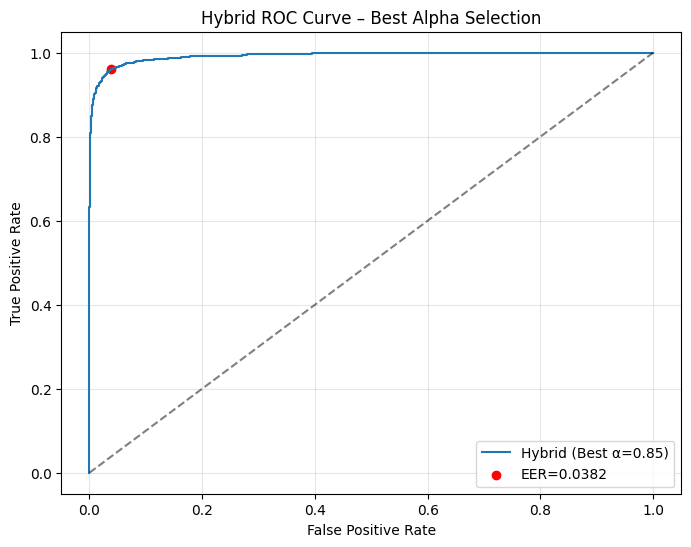

[Loaded Model] Hybrid EER: 3.82% (thr=0.7041, α=0.85)

Final Hybrid Result: 3.82% ± 0.00% (across 1 runs)


In [35]:
import copy
import os
import json

MODEL_PATH = "best_model_imp_adaptive0.5.pth"    # where to save your best model
CONFIG_PATH = "model_config_imp_adaptive0.5.json"

def run_training(seed):
    print(f"\n===== Training with seed {seed} =====")
    set_seed(seed)

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    # --------------------------------------------------
    # If model already exists → load it and skip training
    # --------------------------------------------------
    if os.path.exists(MODEL_PATH):
        print("📌 Found saved model → Loading model instead of training...")
        num_classes = len(train_dataset_dw.indices_by_class)
        model = FingerprintTripleNet(feature_dim=256, num_classes=num_classes).to(device)
        model.load_state_dict(torch.load(MODEL_PATH, map_location=device))
        model.eval()

        eer, threshold, alpha = compute_hybrid_eer_normalized(model, test_loader, device=device)
        print(f"[Loaded Model] Hybrid EER: {eer*100:.2f}% (thr={threshold:.4f}, α={alpha:.2f})")
        return eer * 100

    print("🚀 No saved model found → Training from scratch!")

    num_classes = len(train_dataset_dw.indices_by_class)
    model = FingerprintTripleNet(feature_dim=256, num_classes=num_classes).to(device)

    # --- compute pre-training distance stats (gap) using a fresh model ---
    try:
        stats = compute_distance_stats(model, train_dataset_dw, device=device, embed_batch_size=64, sample_limit=None)
    except Exception as e:
        print(f"[WARN] compute_distance_stats failed: {e}")
        stats = None

    if stats is None or "gap" not in stats or stats["gap"] <= 0.0:
        gap = 1e-4
        print("[WARN] Using fallback gap =", gap)
    else:
        gap = float(stats["gap"])
        print(f"[INFO] distance stats: {stats}")

    # Multipliers — sensible defaults (we keep these mutable for adaptation)
    hard_multiplier = 1
    semi_multiplier = 1

    # safety caps for multipliers to avoid runaway margins
    max_multiplier = 16.0
    adapt_factor = 1.5

    margin_hard = hard_multiplier * gap
    margin_semi = semi_multiplier * gap

    print(f"[INFO] initial margins -> hard: {margin_hard:.6e}, semi: {margin_semi:.6e}")

    optimizer = AdamW(model.parameters(), lr=1e-3, weight_decay=1e-5)

    # 🔥 Losses (enable logging in the loss objects if available)
    hard_criterion = HardTripletLoss(margin=margin_hard, log_stats=True)
    semi_criterion = SemiHardTripletLoss(margin=margin_semi, fallback_to_hard=False, log_stats=True)
    ce_criterion = nn.CrossEntropyLoss()

    # weights
    lambda_hard=0.2
    lambda_cls = 0.1    # classification weight (reduced to avoid CE domination)
    lambda_semi = 1 # semi-hard weight

    scaler = GradScaler("cuda")

    best_val_loss = float("inf")
    best_model_wts = copy.deepcopy(model.state_dict())
    patience = 5
    no_improve_count = 0

    # adaptive counter for consecutive epochs with no triplet signal
    no_triplet_signal_epochs = 0

    # -------------------------
    # Training loop (GLOBAL DW)
    # -------------------------
    for epoch in range(num_epochs):
        # --- recompute gap using current model before mining (costly but principled) ---
        model.eval()
        try:
            stats_epoch = compute_distance_stats(model, train_dataset_dw, device=device, embed_batch_size=64, sample_limit=None)
            print(stats_epoch)
        except Exception as e:
            print(f"[WARN] compute_distance_stats (epoch) failed: {e}")
            stats_epoch = None

        if stats_epoch is None or "gap" not in stats_epoch or stats_epoch["gap"] <= 0.0:
            # keep previous gap/margins if epoch stats invalid
            print(f"[EPOCH-{epoch+1}] could not recompute gap; keeping previous margins")
        else:
            gap = float(stats_epoch["gap"])
            # ensure minimal sensible multipliers to give semi-hard a chance
            hard_multiplier = max(hard_multiplier,1)
            semi_multiplier = max(semi_multiplier, 1)

            margin_hard = hard_multiplier * gap
            margin_semi = semi_multiplier * gap
            margin_hard = max(margin_hard, 1e-12)
            margin_semi = max(margin_semi, 1e-12)

            hard_criterion.margin = min(margin_hard,0.5)
            semi_criterion.margin = min(margin_semi,0.5)
            print(f"[EPOCH-{epoch+1}] recomputed gap: {gap:.6e}; margins -> hard: {hard_criterion.margin:.6e}, semi: {semi_criterion.margin:.6e}")

        # 1) Build global DW triplets for THIS epoch using current model (now using updated margins)
        triplet_loader = build_global_dw_triplet_loader(
            model,
            train_dataset_dw,
            device=device,
            embed_batch_size=64,
            triplet_batch_size=16,
            max_triplets_per_class=50,     # per class cap
            candidates_per_anchor=200,
            negatives_per_pair=4            # increase diversity
        )

        if triplet_loader is None:
            print("No triplets mined, skipping epoch.")
            continue

        # build_global_dw_triplet_loader already prints mined triplet count — no duplicate print here

        model.train()
        total_loss = 0.0
        valid_batches = 0

        # Accumulators for logging counts
        epoch_num_hard = 0
        epoch_num_semi = 0
        epoch_num_fallback = 0

        progress_bar = tqdm(
            triplet_loader,
            desc=f'Epoch {epoch+1} [GLOBAL-DW / Hard+Semi+CE]',
            leave=True
        )

        for batch in progress_bar:
            xa, ya, xp, yp, xn, yn = batch
            xa, xp, xn = xa.to(device), xp.to(device), xn.to(device)
            ya, yp, yn = ya.to(device), yp.to(device), yn.to(device)

            optimizer.zero_grad()
            with autocast("cuda"):
                # embeddings
                a_out = model.embed(xa)
                p_out = model.embed(xp)
                n_out = model.embed(xn)

                # triplet losses — robust to return types
                h_res = hard_criterion(a_out, p_out, n_out)
                if isinstance(h_res, tuple):
                    triplet_loss, num_hard = h_res
                else:
                    triplet_loss, num_hard = h_res, 0

                s_res = semi_criterion(a_out, p_out, n_out)
                if isinstance(s_res, tuple):
                    if len(s_res) == 3:
                        semi_loss, num_semi, num_fallback = s_res
                    else:
                        semi_loss, num_semi = s_res[0], s_res[1]
                        num_fallback = 0
                else:
                    semi_loss, num_semi, num_fallback = s_res, 0, 0

                # classification losses for all three
                logits_a = model.classifier(a_out)
                logits_p = model.classifier(p_out)
                logits_n = model.classifier(n_out)

                ce_loss = (
                    ce_criterion(logits_a, ya) +
                    ce_criterion(logits_p, yp) +
                    ce_criterion(logits_n, yn)
                ) / 3.0

                loss = lambda_hard*triplet_loss + lambda_semi * semi_loss + lambda_cls * ce_loss

            # backward / step with amp
            scaler.scale(loss).backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optimizer)
            scaler.update()

            # accumulate
            total_loss += loss.item()
            epoch_num_hard += int(num_hard)
            epoch_num_semi += int(num_semi)
            epoch_num_fallback += int(num_fallback)
            valid_batches += 1
            progress_bar.set_postfix({'Batch Loss': f'{loss.item():.4f}'})

        avg_train_loss = total_loss / max(valid_batches, 1)

        # -------------------------
        # Validation (unchanged)
        # -------------------------
        model.eval()
        val_loss = 0.0
        val_batches = 0

        all_pos = []
        all_neg = []

        with torch.no_grad():
            for batch in val_loader:
                if batch is None:
                    continue

                min1, dl1, min2, dl2, labels = batch
                dl1, dl2, labels = dl1.to(device), dl2.to(device), labels.to(device)

                emb1 = model.embed(dl1)
                emb2 = model.embed(dl2)

                dist = F.pairwise_distance(emb1, emb2)
                # batch_loss = (labels * dist + (1 - labels) * F.relu(1.0 - dist)).mean()
                all_pos.append(dist[labels == 1])
                all_neg.append(dist[labels == 0])

        # concatenate
        all_pos = torch.cat(all_pos)
        all_neg = torch.cat(all_neg)
        
        avg_val_loss = all_pos.mean() - all_neg.mean()


        # Epoch-level logging
        print(
            f"Epoch {epoch+1} [GLOBAL-DW / Hard+Semi+CE]: "
            f"Train Loss={avg_train_loss:.4f}, Val Loss={avg_val_loss:.4f}"
        )
        print(f"[LOG] semi-hard used: {epoch_num_semi}, fallback-hard: {epoch_num_fallback}, hard-negatives: {epoch_num_hard}")

        # -------------------------
        # ADAPTIVE multiplier if triplet signal vanished for a short run
        # -------------------------
        total_triplet_signal = epoch_num_semi + epoch_num_fallback + epoch_num_hard
        if total_triplet_signal == 0:
            no_triplet_signal_epochs += 1
        else:
            no_triplet_signal_epochs = 0

        # If no triplet signal for a couple of epochs, widen multipliers (but cap)
        if no_triplet_signal_epochs >= 1:
            old_hm, old_sm = hard_multiplier, semi_multiplier
            hard_multiplier = min(hard_multiplier * adapt_factor, max_multiplier)
            semi_multiplier = min(semi_multiplier * adapt_factor, max_multiplier)
            margin_hard = hard_multiplier * gap
            margin_semi = semi_multiplier * gap
            hard_criterion.margin = min(margin_hard,0.5)
            semi_criterion.margin = min(margin_semi,0.5)
            print(f"[ADAPT] triplet-signal empty for {no_triplet_signal_epochs} epoch(s) -> multipliers {old_hm:.2f}->{hard_multiplier:.2f}, {old_sm:.2f}->{semi_multiplier:.2f}")
            print(f"[ADAPT] new margins -> hard: {margin_hard:.6e}, semi: {margin_semi:.6e}")

        # -------------------------
        # Early Stopping Logic
        # -------------------------
        if avg_val_loss < best_val_loss - 1e-4:
            best_val_loss = avg_val_loss
            best_model_wts = copy.deepcopy(model.state_dict())
            no_improve_count = 0
            print(f"✅ New best model at epoch {epoch+1}")
        else:
            no_improve_count += 1
            print(f"⚠️ No improvement for {no_improve_count} epoch(s)")

        if no_improve_count >= patience:
            print(f"⏹ Early stopping triggered at epoch {epoch+1}")
            break

    # restore best
    model.load_state_dict(best_model_wts)

    # ============================
    #     SAVE THE MODEL
    # ============================
    torch.save(best_model_wts, MODEL_PATH)
    print(f"💾 Saved best model to {MODEL_PATH}")

    config = {
        "seed": seed,
        "epochs": num_epochs,
        "lambda_cls": lambda_cls,
        "lambda_semi": lambda_semi,
        "feature_dim": model.feature_dim
    }
    with open(CONFIG_PATH, "w") as f:
        json.dump(config, f, indent=4)
    print(f"📄 Saved config to {CONFIG_PATH}")

    # -------------------------
    # Final Evaluation
    # -------------------------
    eer, threshold, alpha = compute_hybrid_eer_normalized(model, test_loader, device=device)
    print(f"Seed {seed} → Hybrid EER: {eer*100:.2f}% (Threshold: {threshold:.4f}, α={alpha:.2f})")

    return eer * 100



# =========================
# Run across multiple seeds
# =========================
seeds = [42]
num_epochs = 50

all_eers = []
for s in seeds:
    eer = run_training(s)
    all_eers.append(eer)

mean_eer = np.mean(all_eers)
std_eer = np.std(all_eers)
print(f"\nFinal Hybrid Result: {mean_eer:.2f}% ± {std_eer:.2f}% (across {len(seeds)} runs)")



===== Training with seed 42 =====
🚀 No saved model found → Training from scratch!
[INFO] distance stats: {'median_d_ap': 1.9073486612342094e-07, 'median_d_an': 3.576278970740532e-07, 'gap': 1.6689303095063224e-07, 'p10_ap': 7.152557657263969e-08, 'p90_an': 4.7683712978141557e-07}
[INFO] initial margins -> hard: 1.668930e-07, semi: 1.668930e-07
{'median_d_ap': 1.9073486612342094e-07, 'median_d_an': 3.576278970740532e-07, 'gap': 1.6689303095063224e-07, 'p10_ap': 7.152557657263969e-08, 'p90_an': 4.7683712978141557e-07}
[EPOCH-1] recomputed gap: 1.668930e-07; margins -> hard: 1.668930e-07, semi: 1.668930e-07
[DW] Mined 11750 triplets for this epoch.


Epoch 1 [GLOBAL-DW / Hard+Semi+CE]: 100%|█████████████████████████| 735/735 [00:44<00:00, 16.61it/s, Batch Loss=0.4217]
C:\Users\divya\AppData\Local\Temp\ipykernel_30080\477085210.py:83: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.tensor(dl1, dtype=torch.float32),
C:\Users\divya\AppData\Local\Temp\ipykernel_30080\477085210.py:85: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.tensor(dl2, dtype=torch.float32),
C:\Users\divya\AppData\Local\Temp\ipykernel_30080\1251142332.py:8: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  dl1_t

Epoch 1 [GLOBAL-DW / Hard+Semi+CE]: Train Loss=0.4969, Val Loss=-0.8243
[LOG] semi-hard used: 0, fallback-hard: 0, hard-negatives: 580
✅ New best model at epoch 1
{'median_d_ap': 0.05771941691637039, 'median_d_an': 1.7042970657348633, 'gap': 1.646577648818493, 'p10_ap': 0.020243294537067413, 'p90_an': 2.191073989868164}
[EPOCH-2] recomputed gap: 1.646578e+00; margins -> hard: 6.000000e-01, semi: 6.000000e-01
[DW] Mined 11750 triplets for this epoch.


Epoch 2 [GLOBAL-DW / Hard+Semi+CE]: 100%|█████████████████████████| 735/735 [00:47<00:00, 15.45it/s, Batch Loss=0.6573]


Epoch 2 [GLOBAL-DW / Hard+Semi+CE]: Train Loss=0.8173, Val Loss=-0.6632
[LOG] semi-hard used: 3439, fallback-hard: 0, hard-negatives: 687
⚠️ No improvement for 1 epoch(s)
{'median_d_ap': 0.10600900650024414, 'median_d_an': 1.136124849319458, 'gap': 1.0301158428192139, 'p10_ap': 0.031136825494468213, 'p90_an': 1.7546658158302308}
[EPOCH-3] recomputed gap: 1.030116e+00; margins -> hard: 6.000000e-01, semi: 6.000000e-01
[DW] Mined 11750 triplets for this epoch.


Epoch 3 [GLOBAL-DW / Hard+Semi+CE]: 100%|█████████████████████████| 735/735 [00:46<00:00, 15.69it/s, Batch Loss=0.6352]


... (15 outputs left out)

Epoch 11 [GLOBAL-DW / Hard+Semi+CE]: 100%|████████████████████████| 735/735 [00:38<00:00, 19.11it/s, Batch Loss=0.3518]


Epoch 11 [GLOBAL-DW / Hard+Semi+CE]: Train Loss=0.3742, Val Loss=-0.8630
[LOG] semi-hard used: 1860, fallback-hard: 0, hard-negatives: 11
⚠️ No improvement for 5 epoch(s)
⏹ Early stopping triggered at epoch 11
💾 Saved best model to best_model_imp_adaptive0.6.pth
📄 Saved config to model_config_imp_adaptive0.6.json
Computing scores (one-time extraction)...


Eval: 100%|██████████████████████████████████████████████████████████████████████| 20757/20757 [23:31<00:00, 14.71it/s]



=== RAW SCORE STATS ===
DL Scores   : min=-0.8765, max=0.9960
Min Scores  : min=0.0182, max=78.6275

Sample Raw DL Scores: [0.96419036 0.95750713 0.9680414  0.94763565 0.9589776  0.95247334
 0.9709189  0.9763192  0.9436362  0.9492032 ]
Sample Raw Min Scores: [72.39154975 70.62096708 66.12520305 64.53279425 22.49431286 76.98967699
 56.14280863 68.78366731 22.9268958  57.86531349]

=== NORMALIZED SCORES ===
Sample DL_norm: [0.9820952  0.97875357 0.9840207  0.9738178  0.9794888  0.9762367
 0.98545945 0.9881596  0.9718181  0.9746016 ]
Sample Min_norm: [0.7239155  0.70620967 0.66125203 0.64532794 0.22494313 0.76989677
 0.56142809 0.68783667 0.22926896 0.57865313]

Alpha = 0.00
EER   = 0.1333
Threshold  = 0.2096

Alpha = 0.05
EER   = 0.1222
Threshold  = 0.2337

Alpha = 0.10
EER   = 0.1097
Threshold  = 0.2603

Alpha = 0.15
EER   = 0.1020
Threshold  = 0.2849

Alpha = 0.20
EER   = 0.0920
Threshold  = 0.3126

Alpha = 0.25
EER   = 0.0823
Threshold  = 0.3412

Alpha = 0.30
EER   = 0.0747
Threshold

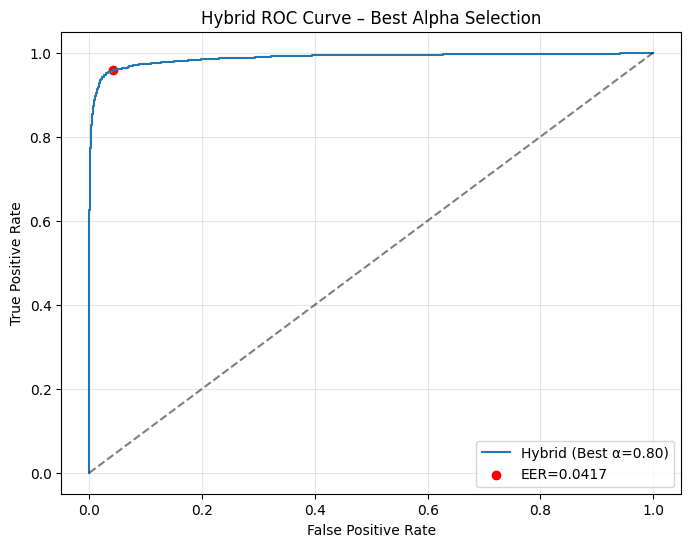

Seed 42 → Hybrid EER: 4.17% (Threshold: 0.6805, α=0.80)

Final Hybrid Result: 4.17% ± 0.00% (across 1 runs)


In [35]:
import copy
import os
import json

MODEL_PATH = "best_model_imp_adaptive0.6.pth"    # where to save your best model
CONFIG_PATH = "model_config_imp_adaptive0.6.json"

def run_training(seed):
    print(f"\n===== Training with seed {seed} =====")
    set_seed(seed)

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    # --------------------------------------------------
    # If model already exists → load it and skip training
    # --------------------------------------------------
    if os.path.exists(MODEL_PATH):
        print("📌 Found saved model → Loading model instead of training...")
        num_classes = len(train_dataset_dw.indices_by_class)
        model = FingerprintTripleNet(feature_dim=256, num_classes=num_classes).to(device)
        model.load_state_dict(torch.load(MODEL_PATH, map_location=device))
        model.eval()

        eer, threshold, alpha = compute_hybrid_eer_normalized(model, test_loader, device=device)
        print(f"[Loaded Model] Hybrid EER: {eer*100:.2f}% (thr={threshold:.4f}, α={alpha:.2f})")
        return eer * 100

    print("🚀 No saved model found → Training from scratch!")

    num_classes = len(train_dataset_dw.indices_by_class)
    model = FingerprintTripleNet(feature_dim=256, num_classes=num_classes).to(device)

    # --- compute pre-training distance stats (gap) using a fresh model ---
    try:
        stats = compute_distance_stats(model, train_dataset_dw, device=device, embed_batch_size=64, sample_limit=None)
    except Exception as e:
        print(f"[WARN] compute_distance_stats failed: {e}")
        stats = None

    if stats is None or "gap" not in stats or stats["gap"] <= 0.0:
        gap = 1e-4
        print("[WARN] Using fallback gap =", gap)
    else:
        gap = float(stats["gap"])
        print(f"[INFO] distance stats: {stats}")

    # Multipliers — sensible defaults (we keep these mutable for adaptation)
    hard_multiplier = 1
    semi_multiplier = 1

    # safety caps for multipliers to avoid runaway margins
    max_multiplier = 16.0
    adapt_factor = 1.5

    margin_hard = hard_multiplier * gap
    margin_semi = semi_multiplier * gap

    print(f"[INFO] initial margins -> hard: {margin_hard:.6e}, semi: {margin_semi:.6e}")

    optimizer = AdamW(model.parameters(), lr=1e-3, weight_decay=1e-5)

    # 🔥 Losses (enable logging in the loss objects if available)
    hard_criterion = HardTripletLoss(margin=margin_hard, log_stats=True)
    semi_criterion = SemiHardTripletLoss(margin=margin_semi, fallback_to_hard=False, log_stats=True)
    ce_criterion = nn.CrossEntropyLoss()

    # weights
    lambda_hard=0.2
    lambda_cls = 0.1    # classification weight (reduced to avoid CE domination)
    lambda_semi = 1 # semi-hard weight

    scaler = GradScaler("cuda")

    best_val_loss = float("inf")
    best_model_wts = copy.deepcopy(model.state_dict())
    patience = 5
    no_improve_count = 0

    # adaptive counter for consecutive epochs with no triplet signal
    no_triplet_signal_epochs = 0

    # -------------------------
    # Training loop (GLOBAL DW)
    # -------------------------
    for epoch in range(num_epochs):
        # --- recompute gap using current model before mining (costly but principled) ---
        model.eval()
        try:
            stats_epoch = compute_distance_stats(model, train_dataset_dw, device=device, embed_batch_size=64, sample_limit=None)
            print(stats_epoch)
        except Exception as e:
            print(f"[WARN] compute_distance_stats (epoch) failed: {e}")
            stats_epoch = None

        if stats_epoch is None or "gap" not in stats_epoch or stats_epoch["gap"] <= 0.0:
            # keep previous gap/margins if epoch stats invalid
            print(f"[EPOCH-{epoch+1}] could not recompute gap; keeping previous margins")
        else:
            gap = float(stats_epoch["gap"])
            # ensure minimal sensible multipliers to give semi-hard a chance
            hard_multiplier = max(hard_multiplier,1)
            semi_multiplier = max(semi_multiplier, 1)

            margin_hard = hard_multiplier * gap
            margin_semi = semi_multiplier * gap
            margin_hard = max(margin_hard, 1e-12)
            margin_semi = max(margin_semi, 1e-12)

            hard_criterion.margin = min(margin_hard,0.6)
            semi_criterion.margin = min(margin_semi,0.6)
            print(f"[EPOCH-{epoch+1}] recomputed gap: {gap:.6e}; margins -> hard: {hard_criterion.margin:.6e}, semi: {semi_criterion.margin:.6e}")

        # 1) Build global DW triplets for THIS epoch using current model (now using updated margins)
        triplet_loader = build_global_dw_triplet_loader(
            model,
            train_dataset_dw,
            device=device,
            embed_batch_size=64,
            triplet_batch_size=16,
            max_triplets_per_class=50,     # per class cap
            candidates_per_anchor=200,
            negatives_per_pair=4            # increase diversity
        )

        if triplet_loader is None:
            print("No triplets mined, skipping epoch.")
            continue

        # build_global_dw_triplet_loader already prints mined triplet count — no duplicate print here

        model.train()
        total_loss = 0.0
        valid_batches = 0

        # Accumulators for logging counts
        epoch_num_hard = 0
        epoch_num_semi = 0
        epoch_num_fallback = 0

        progress_bar = tqdm(
            triplet_loader,
            desc=f'Epoch {epoch+1} [GLOBAL-DW / Hard+Semi+CE]',
            leave=True
        )

        for batch in progress_bar:
            xa, ya, xp, yp, xn, yn = batch
            xa, xp, xn = xa.to(device), xp.to(device), xn.to(device)
            ya, yp, yn = ya.to(device), yp.to(device), yn.to(device)

            optimizer.zero_grad()
            with autocast("cuda"):
                # embeddings
                a_out = model.embed(xa)
                p_out = model.embed(xp)
                n_out = model.embed(xn)

                # triplet losses — robust to return types
                h_res = hard_criterion(a_out, p_out, n_out)
                if isinstance(h_res, tuple):
                    triplet_loss, num_hard = h_res
                else:
                    triplet_loss, num_hard = h_res, 0

                s_res = semi_criterion(a_out, p_out, n_out)
                if isinstance(s_res, tuple):
                    if len(s_res) == 3:
                        semi_loss, num_semi, num_fallback = s_res
                    else:
                        semi_loss, num_semi = s_res[0], s_res[1]
                        num_fallback = 0
                else:
                    semi_loss, num_semi, num_fallback = s_res, 0, 0

                # classification losses for all three
                logits_a = model.classifier(a_out)
                logits_p = model.classifier(p_out)
                logits_n = model.classifier(n_out)

                ce_loss = (
                    ce_criterion(logits_a, ya) +
                    ce_criterion(logits_p, yp) +
                    ce_criterion(logits_n, yn)
                ) / 3.0

                loss = lambda_hard*triplet_loss + lambda_semi * semi_loss + lambda_cls * ce_loss

            # backward / step with amp
            scaler.scale(loss).backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optimizer)
            scaler.update()

            # accumulate
            total_loss += loss.item()
            epoch_num_hard += int(num_hard)
            epoch_num_semi += int(num_semi)
            epoch_num_fallback += int(num_fallback)
            valid_batches += 1
            progress_bar.set_postfix({'Batch Loss': f'{loss.item():.4f}'})

        avg_train_loss = total_loss / max(valid_batches, 1)

        # -------------------------
        # Validation (unchanged)
        # -------------------------
        model.eval()
        val_loss = 0.0
        val_batches = 0

        all_pos = []
        all_neg = []

        with torch.no_grad():
            for batch in val_loader:
                if batch is None:
                    continue

                min1, dl1, min2, dl2, labels = batch
                dl1, dl2, labels = dl1.to(device), dl2.to(device), labels.to(device)

                emb1 = model.embed(dl1)
                emb2 = model.embed(dl2)

                dist = F.pairwise_distance(emb1, emb2)
                # batch_loss = (labels * dist + (1 - labels) * F.relu(1.0 - dist)).mean()
                all_pos.append(dist[labels == 1])
                all_neg.append(dist[labels == 0])

        # concatenate
        all_pos = torch.cat(all_pos)
        all_neg = torch.cat(all_neg)
        
        avg_val_loss = all_pos.mean() - all_neg.mean()


        # Epoch-level logging
        print(
            f"Epoch {epoch+1} [GLOBAL-DW / Hard+Semi+CE]: "
            f"Train Loss={avg_train_loss:.4f}, Val Loss={avg_val_loss:.4f}"
        )
        print(f"[LOG] semi-hard used: {epoch_num_semi}, fallback-hard: {epoch_num_fallback}, hard-negatives: {epoch_num_hard}")

        # -------------------------
        # ADAPTIVE multiplier if triplet signal vanished for a short run
        # -------------------------
        total_triplet_signal = epoch_num_semi + epoch_num_fallback + epoch_num_hard
        if total_triplet_signal == 0:
            no_triplet_signal_epochs += 1
        else:
            no_triplet_signal_epochs = 0

        # If no triplet signal for a couple of epochs, widen multipliers (but cap)
        if no_triplet_signal_epochs >= 1:
            old_hm, old_sm = hard_multiplier, semi_multiplier
            hard_multiplier = min(hard_multiplier * adapt_factor, max_multiplier)
            semi_multiplier = min(semi_multiplier * adapt_factor, max_multiplier)
            margin_hard = hard_multiplier * gap
            margin_semi = semi_multiplier * gap
            hard_criterion.margin = margin_hard
            semi_criterion.margin = margin_semi
            print(f"[ADAPT] triplet-signal empty for {no_triplet_signal_epochs} epoch(s) -> multipliers {old_hm:.2f}->{hard_multiplier:.2f}, {old_sm:.2f}->{semi_multiplier:.2f}")
            print(f"[ADAPT] new margins -> hard: {margin_hard:.6e}, semi: {margin_semi:.6e}")

        # -------------------------
        # Early Stopping Logic
        # -------------------------
        if avg_val_loss < best_val_loss - 1e-4:
            best_val_loss = avg_val_loss
            best_model_wts = copy.deepcopy(model.state_dict())
            no_improve_count = 0
            print(f"✅ New best model at epoch {epoch+1}")
        else:
            no_improve_count += 1
            print(f"⚠️ No improvement for {no_improve_count} epoch(s)")

        if no_improve_count >= patience:
            print(f"⏹ Early stopping triggered at epoch {epoch+1}")
            break

    # restore best
    model.load_state_dict(best_model_wts)

    # ============================
    #     SAVE THE MODEL
    # ============================
    torch.save(best_model_wts, MODEL_PATH)
    print(f"💾 Saved best model to {MODEL_PATH}")

    config = {
        "seed": seed,
        "epochs": num_epochs,
        "lambda_cls": lambda_cls,
        "lambda_semi": lambda_semi,
        "feature_dim": model.feature_dim
    }
    with open(CONFIG_PATH, "w") as f:
        json.dump(config, f, indent=4)
    print(f"📄 Saved config to {CONFIG_PATH}")

    # -------------------------
    # Final Evaluation
    # -------------------------
    eer, threshold, alpha = compute_hybrid_eer_normalized(model, test_loader, device=device)
    print(f"Seed {seed} → Hybrid EER: {eer*100:.2f}% (Threshold: {threshold:.4f}, α={alpha:.2f})")

    return eer * 100



# =========================
# Run across multiple seeds
# =========================
seeds = [42]
num_epochs = 50

all_eers = []
for s in seeds:
    eer = run_training(s)
    all_eers.append(eer)

mean_eer = np.mean(all_eers)
std_eer = np.std(all_eers)
print(f"\nFinal Hybrid Result: {mean_eer:.2f}% ± {std_eer:.2f}% (across {len(seeds)} runs)")


In [ ]:
import copy
import os
import json

MODEL_PATH = "best_model_imp_adaptive0.5.pth"    # where to save your best model
CONFIG_PATH = "model_config_imp_adaptive0.5.json"

def run_training(seed):
    print(f"\n===== Training with seed {seed} =====")
    set_seed(seed)

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    # --------------------------------------------------
    # If model already exists → load it and skip training
    # --------------------------------------------------
    if os.path.exists(MODEL_PATH):
        print("📌 Found saved model → Loading model instead of training...")
        num_classes = len(train_dataset_dw.indices_by_class)
        model = FingerprintTripleNet(feature_dim=256, num_classes=num_classes).to(device)
        model.load_state_dict(torch.load(MODEL_PATH, map_location=device))
        model.eval()

        eer, threshold, alpha = compute_hybrid_eer_normalized(model, test_loader, device=device)
        print(f"[Loaded Model] Hybrid EER: {eer*100:.2f}% (thr={threshold:.4f}, α={alpha:.2f})")
        return eer * 100

    print("🚀 No saved model found → Training from scratch!")

    num_classes = len(train_dataset_dw.indices_by_class)
    model = FingerprintTripleNet(feature_dim=256, num_classes=num_classes).to(device)

    # --- compute pre-training distance stats (gap) using a fresh model ---
    try:
        stats = compute_distance_stats(model, train_dataset_dw, device=device, embed_batch_size=64, sample_limit=None)
    except Exception as e:
        print(f"[WARN] compute_distance_stats failed: {e}")
        stats = None

    if stats is None or "gap" not in stats or stats["gap"] <= 0.0:
        gap = 1e-4
        print("[WARN] Using fallback gap =", gap)
    else:
        gap = float(stats["gap"])
        print(f"[INFO] distance stats: {stats}")

    # Multipliers — sensible defaults (we keep these mutable for adaptation)
    hard_multiplier = 1
    semi_multiplier = 1

    # safety caps for multipliers to avoid runaway margins
    max_multiplier = 16.0
    adapt_factor = 1.5

    margin_hard = hard_multiplier * gap
    margin_semi = semi_multiplier * gap

    print(f"[INFO] initial margins -> hard: {margin_hard:.6e}, semi: {margin_semi:.6e}")

    optimizer = AdamW(model.parameters(), lr=1e-3, weight_decay=1e-5)

    # 🔥 Losses (enable logging in the loss objects if available)
    hard_criterion = HardTripletLoss(margin=margin_hard, log_stats=True)
    semi_criterion = SemiHardTripletLoss(margin=margin_semi, fallback_to_hard=False, log_stats=True)
    ce_criterion = nn.CrossEntropyLoss()

    # weights
    lambda_hard=0.2
    lambda_cls = 0.1    # classification weight (reduced to avoid CE domination)
    lambda_semi = 1 # semi-hard weight
    margin_limit = 0.5

    scaler = GradScaler("cuda")

    best_val_loss = float("inf")
    best_model_wts = copy.deepcopy(model.state_dict())
    patience = 5
    no_improve_count = 0

    # adaptive counter for consecutive epochs with no triplet signal
    no_triplet_signal_epochs = 0

    # -------------------------
    # Training loop (GLOBAL DW)
    # -------------------------
    for epoch in range(num_epochs):
        # --- recompute gap using current model before mining (costly but principled) ---
        model.eval()
        try:
            stats_epoch = compute_distance_stats(model, train_dataset_dw, device=device, embed_batch_size=64, sample_limit=None)
            print(stats_epoch)
        except Exception as e:
            print(f"[WARN] compute_distance_stats (epoch) failed: {e}")
            stats_epoch = None

        if stats_epoch is None or "gap" not in stats_epoch or stats_epoch["gap"] <= 0.0:
            # keep previous gap/margins if epoch stats invalid
            print(f"[EPOCH-{epoch+1}] could not recompute gap; keeping previous margins")
        else:
            gap = float(stats_epoch["gap"])
            # ensure minimal sensible multipliers to give semi-hard a chance
            hard_multiplier = max(hard_multiplier,1)
            semi_multiplier = max(semi_multiplier, 1)

            margin_hard = hard_multiplier * gap
            margin_semi = semi_multiplier * gap
            margin_hard = max(margin_hard, 1e-12)
            margin_semi = max(margin_semi, 1e-12)

            hard_criterion.margin = min(margin_hard,margin_limit)
            semi_criterion.margin = min(margin_semi,margin_limit)
            print(f"[EPOCH-{epoch+1}] recomputed gap: {gap:.6e}; margins -> hard: {hard_criterion.margin:.6e}, semi: {semi_criterion.margin:.6e}")

        # 1) Build global DW triplets for THIS epoch using current model (now using updated margins)
        triplet_loader = build_global_dw_triplet_loader(
            model,
            train_dataset_dw,
            device=device,
            embed_batch_size=64,
            triplet_batch_size=16,
            max_triplets_per_class=50,     # per class cap
            candidates_per_anchor=200,
            negatives_per_pair=4            # increase diversity
        )

        if triplet_loader is None:
            print("No triplets mined, skipping epoch.")
            continue

        # build_global_dw_triplet_loader already prints mined triplet count — no duplicate print here

        model.train()
        total_loss = 0.0
        valid_batches = 0

        # Accumulators for logging counts
        epoch_num_hard = 0
        epoch_num_semi = 0
        epoch_num_fallback = 0

        progress_bar = tqdm(
            triplet_loader,
            desc=f'Epoch {epoch+1} [GLOBAL-DW / Hard+Semi+CE]',
            leave=True
        )

        for batch in progress_bar:
            xa, ya, xp, yp, xn, yn = batch
            xa, xp, xn = xa.to(device), xp.to(device), xn.to(device)
            ya, yp, yn = ya.to(device), yp.to(device), yn.to(device)

            optimizer.zero_grad()
            with autocast("cuda"):
                # embeddings
                a_out = model.embed(xa)
                p_out = model.embed(xp)
                n_out = model.embed(xn)

                # triplet losses — robust to return types
                h_res = hard_criterion(a_out, p_out, n_out)
                if isinstance(h_res, tuple):
                    triplet_loss, num_hard = h_res
                else:
                    triplet_loss, num_hard = h_res, 0

                s_res = semi_criterion(a_out, p_out, n_out)
                if isinstance(s_res, tuple):
                    if len(s_res) == 3:
                        semi_loss, num_semi, num_fallback = s_res
                    else:
                        semi_loss, num_semi = s_res[0], s_res[1]
                        num_fallback = 0
                else:
                    semi_loss, num_semi, num_fallback = s_res, 0, 0

                # classification losses for all three
                logits_a = model.classifier(a_out)
                logits_p = model.classifier(p_out)
                logits_n = model.classifier(n_out)

                ce_loss = (
                    ce_criterion(logits_a, ya) +
                    ce_criterion(logits_p, yp) +
                    ce_criterion(logits_n, yn)
                ) / 3.0

                loss = lambda_hard*triplet_loss + lambda_semi * semi_loss + lambda_cls * ce_loss

            # backward / step with amp
            scaler.scale(loss).backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optimizer)
            scaler.update()

            # accumulate
            total_loss += loss.item()
            epoch_num_hard += int(num_hard)
            epoch_num_semi += int(num_semi)
            epoch_num_fallback += int(num_fallback)
            valid_batches += 1
            progress_bar.set_postfix({'Batch Loss': f'{loss.item():.4f}'})

        avg_train_loss = total_loss / max(valid_batches, 1)

        # -------------------------
        # Validation (unchanged)
        # -------------------------
        model.eval()
        val_loss = 0.0
        val_batches = 0

        all_pos = []
        all_neg = []

        with torch.no_grad():
            for batch in val_loader:
                if batch is None:
                    continue

                min1, dl1, min2, dl2, labels = batch
                dl1, dl2, labels = dl1.to(device), dl2.to(device), labels.to(device)

                emb1 = model.embed(dl1)
                emb2 = model.embed(dl2)

                dist = F.pairwise_distance(emb1, emb2)
                # batch_loss = (labels * dist + (1 - labels) * F.relu(1.0 - dist)).mean()
                all_pos.append(dist[labels == 1])
                all_neg.append(dist[labels == 0])

        # concatenate
        all_pos = torch.cat(all_pos)
        all_neg = torch.cat(all_neg)
        
        avg_val_loss = all_pos.mean() - all_neg.mean()


        # Epoch-level logging
        print(
            f"Epoch {epoch+1} [GLOBAL-DW / Hard+Semi+CE]: "
            f"Train Loss={avg_train_loss:.4f}, Val Loss={avg_val_loss:.4f}"
        )
        print(f"[LOG] semi-hard used: {epoch_num_semi}, fallback-hard: {epoch_num_fallback}, hard-negatives: {epoch_num_hard}")

        # -------------------------
        # ADAPTIVE multiplier if triplet signal vanished for a short run
        # -------------------------
        total_triplet_signal = epoch_num_semi + epoch_num_fallback + epoch_num_hard
        if total_triplet_signal == 0:
            no_triplet_signal_epochs += 1
        else:
            no_triplet_signal_epochs = 0

        # If no triplet signal for a couple of epochs, widen multipliers (but cap)
        if no_triplet_signal_epochs >= 1:
            old_hm, old_sm = hard_multiplier, semi_multiplier
            hard_multiplier = min(hard_multiplier * adapt_factor, max_multiplier)
            semi_multiplier = min(semi_multiplier * adapt_factor, max_multiplier)
            margin_hard = hard_multiplier * gap
            margin_semi = semi_multiplier * gap
            hard_criterion.margin = margin_hard
            semi_criterion.margin = margin_semi
            print(f"[ADAPT] triplet-signal empty for {no_triplet_signal_epochs} epoch(s) -> multipliers {old_hm:.2f}->{hard_multiplier:.2f}, {old_sm:.2f}->{semi_multiplier:.2f}")
            print(f"[ADAPT] new margins -> hard: {margin_hard:.6e}, semi: {margin_semi:.6e}")

        # -------------------------
        # Early Stopping Logic
        # -------------------------
        if avg_val_loss < best_val_loss - 1e-4:
            best_val_loss = avg_val_loss
            best_model_wts = copy.deepcopy(model.state_dict())
            no_improve_count = 0
            print(f"✅ New best model at epoch {epoch+1}")
        else:
            no_improve_count += 1
            print(f"⚠️ No improvement for {no_improve_count} epoch(s)")

        if no_improve_count >= patience:
            print(f"⏹ Early stopping triggered at epoch {epoch+1}")
            break

    # restore best
    model.load_state_dict(best_model_wts)

    # ============================
    #     SAVE THE MODEL
    # ============================
    torch.save(best_model_wts, MODEL_PATH)
    print(f"💾 Saved best model to {MODEL_PATH}")

    config = {
        "seed": seed,
        "epochs": num_epochs,
        "lambda_cls": lambda_cls,
        "lambda_semi": lambda_semi,
        "feature_dim": model.feature_dim
    }
    with open(CONFIG_PATH, "w") as f:
        json.dump(config, f, indent=4)
    print(f"📄 Saved config to {CONFIG_PATH}")

    # -------------------------
    # Final Evaluation
    # -------------------------
    eer, threshold, alpha = compute_hybrid_eer_normalized(model, test_loader, device=device)
    print(f"Seed {seed} → Hybrid EER: {eer*100:.2f}% (Threshold: {threshold:.4f}, α={alpha:.2f})")

    return eer * 100



# =========================
# Run across multiple seeds
# =========================
seeds = [42]
num_epochs = 50

all_eers = []
for s in seeds:
    eer = run_training(s)
    all_eers.append(eer)

mean_eer = np.mean(all_eers)
std_eer = np.std(all_eers)
print(f"\nFinal Hybrid Result: {mean_eer:.2f}% ± {std_eer:.2f}% (across {len(seeds)} runs)")


In [31]:
num_epochs = 50
def compute_hybrid_eer_alpha_geq(model, dataloader, device="cuda", alpha_min=0.5):
    model.eval()

    dl_scores, min_scores, labels = [], [], []

    with torch.no_grad():
        for batch in dataloader:
            if batch is None:
                continue
            min1, dl1, min2, dl2, y = batch
            dl1, dl2 = dl1.to(device), dl2.to(device)

            e1 = model.embed(dl1)
            e2 = model.embed(dl2)

            dl_sim = F.cosine_similarity(e1, e2).cpu().numpy()
            min_sim = np.array([match_features(m1, m2) for m1, m2 in zip(min1, min2)])

            dl_scores.extend(dl_sim)
            min_scores.extend(min_sim)
            labels.extend(y.numpy())

    dl_scores = np.array(dl_scores)
    min_scores = np.array(min_scores)
    labels = np.array(labels)

    dl_norm = (dl_scores + 1) / 2
    min_norm = min_scores / 100

    alpha_values = np.arange(alpha_min, 1.01, 0.05)

    best_eer = 1.0
    for alpha in alpha_values:
        scores = alpha * dl_norm + (1 - alpha) * min_norm
        fpr, tpr, _ = roc_curve(labels, scores)
        fnr = 1 - tpr
        eer = np.min((fpr + fnr) / 2)
        best_eer = min(best_eer, eer)

    return best_eer


In [31]:
import optuna
import copy

def objective(trial):

    # ===============================
    # Hyperparameters to tune
    # ===============================
    lambda_semi  = trial.suggest_float("lambda_semi", 0.5, 1.5, log=True)
    lambda_hard  = trial.suggest_float("lambda_hard", 0.05, 0.6)
    lambda_cls   = trial.suggest_float("lambda_cls", 0.02, 0.6)
    margin_limit = trial.suggest_float("margin_limit", 0.3, 0.6)

    print("\n[TRIAL PARAMS]")
    print(f"lambda_semi={lambda_semi:.4f}, lambda_hard={lambda_hard:.4f}, "
          f"lambda_cls={lambda_cls:.4f}, margin_limit={margin_limit:.4f}")

    # ===============================
    # Setup
    # ===============================
    set_seed(42)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    num_classes = len(train_dataset_dw.indices_by_class)

    model = FingerprintTripleNet(
        feature_dim=256,
        num_classes=num_classes
    ).to(device)

    optimizer = AdamW(model.parameters(), lr=1e-3, weight_decay=1e-5)
    scaler = GradScaler("cuda")

    ce_criterion = nn.CrossEntropyLoss()

    # ===============================
    # Initial distance stats (same as main code)
    # ===============================
    stats = compute_distance_stats(
        model, train_dataset_dw, device=device,
        embed_batch_size=64, sample_limit=None
    )

    gap = float(stats["gap"]) if stats and stats["gap"] > 0 else 1e-4

    hard_criterion = HardTripletLoss(
        margin=min(gap, margin_limit),
        log_stats=False
    )
    semi_criterion = SemiHardTripletLoss(
        margin=min(gap, margin_limit),
        fallback_to_hard=False,
        log_stats=False
    )

    # ===============================
    # Early stopping state
    # ===============================
    best_val_loss = float("inf")
    best_model_wts = copy.deepcopy(model.state_dict())
    no_improve = 0
    patience = 5

    # ===============================
    # Training loop (FAITHFUL)
    # ===============================
    for epoch in range(num_epochs):

        # -------- recompute gap EVERY epoch (CRITICAL FIX) --------
        model.eval()
        stats_epoch = compute_distance_stats(
            model, train_dataset_dw, device=device,
            embed_batch_size=64, sample_limit=None
        )

        if stats_epoch and stats_epoch["gap"] > 0:
            gap = float(stats_epoch["gap"])
            hard_criterion.margin = min(gap, margin_limit)
            semi_criterion.margin = min(gap, margin_limit)

        # -------- mine DW triplets --------
        triplet_loader = build_global_dw_triplet_loader(
            model,
            train_dataset_dw,
            device=device,
            embed_batch_size=64,
            triplet_batch_size=16,
            max_triplets_per_class=50,
            candidates_per_anchor=200,
            negatives_per_pair=4
        )

        if triplet_loader is None:
            continue

        # -------- training --------
        model.train()
        for xa, ya, xp, yp, xn, yn in triplet_loader:

            xa, xp, xn = xa.to(device), xp.to(device), xn.to(device)
            ya, yp, yn = ya.to(device), yp.to(device), yn.to(device)

            optimizer.zero_grad(set_to_none=True)

            with autocast("cuda"):
                a = model.embed(xa)
                p = model.embed(xp)
                n = model.embed(xn)

                hard_loss = hard_criterion(a, p, n)
                semi_loss = semi_criterion(a, p, n)

                ce_loss = (
                    ce_criterion(model.classifier(a), ya) +
                    ce_criterion(model.classifier(p), yp) +
                    ce_criterion(model.classifier(n), yn)
                ) / 3.0

                loss = (
                    lambda_hard * hard_loss +
                    lambda_semi * semi_loss +
                    lambda_cls * ce_loss
                )

            scaler.scale(loss).backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optimizer)
            scaler.update()

        # ===============================
        # Validation (unchanged)
        # ===============================
        model.eval()
        all_pos, all_neg = [], []

        with torch.no_grad():
            for batch in val_loader:
                if batch is None:
                    continue

                min1, dl1, min2, dl2, labels = batch
                dl1, dl2 = dl1.to(device), dl2.to(device)
                labels = labels.to(device)

                e1 = model.embed(dl1)
                e2 = model.embed(dl2)

                dist = F.pairwise_distance(e1, e2)
                all_pos.append(dist[labels == 1])
                all_neg.append(dist[labels == 0])

        val_loss = torch.cat(all_pos).mean() - torch.cat(all_neg).mean()

        if val_loss < best_val_loss - 1e-4:
            best_val_loss = val_loss
            best_model_wts = copy.deepcopy(model.state_dict())
            no_improve = 0
        else:
            no_improve += 1

        if no_improve >= patience:
            break

    # ===============================
    # Final evaluation (α ≥ 0.5 ONLY)
    # ===============================
    model.load_state_dict(best_model_wts)

    eer = compute_hybrid_eer_alpha_geq(
        model, test_loader, device=device, alpha_min=0.5
    )

    print(f"[TRIAL RESULT] EER = {eer*100:.2f}%")

    return eer


In [32]:
study = optuna.create_study(direction="minimize")
study.optimize(objective, n_trials=30)

print("\n===== BEST TRIAL =====")
print("EER:", study.best_value * 100)
print("Params:", study.best_params)


[I 2025-12-23 19:34:40,862] A new study created in memory with name: no-name-7cb4a083-492d-47f8-b61d-0531e963f5b6



[TRIAL PARAMS]
lambda_semi=1.0367, lambda_hard=0.4974, lambda_cls=0.4767, margin_limit=0.4893
[DW] Mined 11750 triplets for this epoch.


C:\Users\divya\AppData\Local\Temp\ipykernel_26336\477085210.py:83: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.tensor(dl1, dtype=torch.float32),
C:\Users\divya\AppData\Local\Temp\ipykernel_26336\477085210.py:85: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.tensor(dl2, dtype=torch.float32),
C:\Users\divya\AppData\Local\Temp\ipykernel_26336\1251142332.py:8: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  dl1_tensor = torch.stack([torch.tensor(x, dtype=torch.float32) for x in dl1_list])
C:\Users\divya\AppData\Local\Temp\ipykerne

[DW] Mined 11750 triplets for this epoch.
[DW] Mined 11750 triplets for this epoch.
[DW] Mined 11750 triplets for this epoch.
[DW] Mined 11750 triplets for this epoch.
[DW] Mined 11750 triplets for this epoch.
[DW] Mined 11750 triplets for this epoch.
[DW] Mined 11750 triplets for this epoch.
[DW] Mined 11750 triplets for this epoch.
[DW] Mined 11750 triplets for this epoch.
[DW] Mined 11750 triplets for this epoch.


[I 2025-12-23 19:58:02,568] Trial 0 finished with value: 0.04465052190030242 and parameters: {'lambda_semi': 1.0367049618596906, 'lambda_hard': 0.4973924788182041, 'lambda_cls': 0.4766806124293982, 'margin_limit': 0.48928809173808463}. Best is trial 0 with value: 0.04465052190030242.


[TRIAL RESULT] EER = 4.47%

[TRIAL PARAMS]
lambda_semi=1.2632, lambda_hard=0.2509, lambda_cls=0.4936, margin_limit=0.5070
[DW] Mined 11750 triplets for this epoch.


... (112 outputs left out)

C:\Users\divya\AppData\Local\Temp\ipykernel_26336\477085210.py:83: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.tensor(dl1, dtype=torch.float32),
C:\Users\divya\AppData\Local\Temp\ipykernel_26336\477085210.py:85: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.tensor(dl2, dtype=torch.float32),
C:\Users\divya\AppData\Local\Temp\ipykernel_26336\1251142332.py:8: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  dl1_tensor = torch.stack([torch.tensor(x, dtype=torch.float32) for x in dl1_list])
C:\Users\divya\AppData\Local\Temp\ipykerne

[DW] Mined 11750 triplets for this epoch.
[DW] Mined 11750 triplets for this epoch.
[DW] Mined 11750 triplets for this epoch.
[DW] Mined 11750 triplets for this epoch.
[DW] Mined 11750 triplets for this epoch.
[DW] Mined 11750 triplets for this epoch.
[DW] Mined 11750 triplets for this epoch.
[DW] Mined 11750 triplets for this epoch.


[I 2025-12-24 06:39:54,331] Trial 29 finished with value: 0.0414642473904985 and parameters: {'lambda_semi': 1.0059489474184182, 'lambda_hard': 0.13494591336138462, 'lambda_cls': 0.4977199330737661, 'margin_limit': 0.5383942580665118}. Best is trial 23 with value: 0.03226636425714567.


[TRIAL RESULT] EER = 4.15%

===== BEST TRIAL =====
EER: 3.226636425714567
Params: {'lambda_semi': 1.1632989523165889, 'lambda_hard': 0.05133425729800692, 'lambda_cls': 0.3251667645380196, 'margin_limit': 0.5691526477174389}


In [36]:
df = study.trials_dataframe()

# Show key columns
print(df[["number", "value", "params_lambda_semi",
          "params_lambda_hard", "params_lambda_cls",
          "params_margin_limit"]])

df.to_csv("optuna_results1.csv", index=False)


    number     value  params_lambda_semi  params_lambda_hard  \
0        0  0.044651            1.036705            0.497392   
1        1  0.038137            1.263214            0.250910   
2        2  0.042047            0.604199            0.548688   
3        3  0.052818            0.556077            0.423828   
4        4  0.039484            1.443430            0.476151   
5        5  0.040951            0.720116            0.400047   
6        6  0.045118            0.737788            0.315868   
7        7  0.049090            1.275183            0.333712   
8        8  0.041892            1.062303            0.174897   
9        9  0.043793            0.718639            0.415306   
10      10  0.033564            1.014063            0.065048   
11      11  0.034223            1.045815            0.056481   
12      12  0.045641            0.942081            0.051540   
13      13  0.035889            0.857007            0.072874   
14      14  0.041344            1.134373

In [33]:
best_params = study.best_params

lambda_semi  = best_params["lambda_semi"]
lambda_hard  = best_params["lambda_hard"]
lambda_cls   = best_params["lambda_cls"]
margin_limit = best_params["margin_limit"]


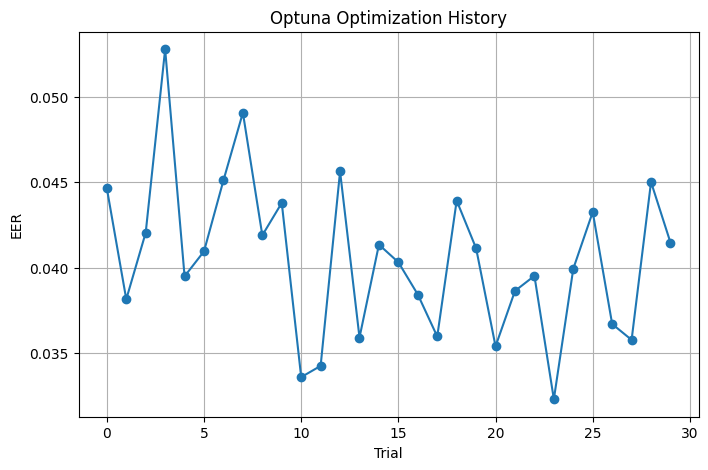

In [34]:
import matplotlib.pyplot as plt

df = study.trials_dataframe()

plt.figure(figsize=(8, 5))
plt.plot(df["number"], df["value"], marker="o")
plt.xlabel("Trial")
plt.ylabel("EER")
plt.title("Optuna Optimization History")
plt.grid(True)
plt.show()


In [35]:
from optuna.importance import get_param_importances

importances = get_param_importances(study)
print(importances)


{'lambda_hard': np.float64(0.35452969399006334), 'lambda_semi': np.float64(0.3355590531702029), 'lambda_cls': np.float64(0.20901458170627957), 'margin_limit': np.float64(0.1008966711334543)}


In [29]:
import pandas as pd

df = pd.read_csv("optuna_results1.csv")
print(df.columns)
# best_row = df.loc[df["value"].idxmin()]
best_row = df.loc[10]
print(best_row)


Index(['number', 'value', 'datetime_start', 'datetime_complete', 'duration',
       'params_lambda_cls', 'params_lambda_hard', 'params_lambda_semi',
       'params_margin_limit', 'state'],
      dtype='object')
number                                         10
value                                    0.033564
datetime_start         2025-12-23 23:13:59.394463
datetime_complete      2025-12-23 23:38:30.073147
duration                   0 days 00:24:30.678684
params_lambda_cls                        0.420218
params_lambda_hard                       0.065048
params_lambda_semi                       1.014063
params_margin_limit                      0.599165
state                                    COMPLETE
Name: 10, dtype: object


In [30]:
lambda_semi  = best_row["params_lambda_semi"]
lambda_hard  = best_row["params_lambda_hard"]
lambda_cls   = best_row["params_lambda_cls"]
margin_limit = best_row["params_margin_limit"]

print("Recovered best params:")
print(f"lambda_semi  = {lambda_semi}")
print(f"lambda_hard  = {lambda_hard}")
print(f"lambda_cls   = {lambda_cls}")
print(f"margin_limit = {margin_limit}")


Recovered best params:
lambda_semi  = 1.0140632711577868
lambda_hard  = 0.0650482075635456
lambda_cls   = 0.4202180671735022
margin_limit = 0.5991649714545019


In [31]:
lambda_hard=0


===== Training with seed 1 =====
[DW] Mined 11750 triplets for this epoch.


C:\Users\divya\AppData\Local\Temp\ipykernel_33444\477085210.py:83: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.tensor(dl1, dtype=torch.float32),
C:\Users\divya\AppData\Local\Temp\ipykernel_33444\477085210.py:85: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.tensor(dl2, dtype=torch.float32),
C:\Users\divya\AppData\Local\Temp\ipykernel_33444\1251142332.py:8: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  dl1_tensor = torch.stack([torch.tensor(x, dtype=torch.float32) for x in dl1_list])
C:\Users\divya\AppData\Local\Temp\ipykerne

[DW] Mined 11750 triplets for this epoch.
[DW] Mined 11750 triplets for this epoch.
[DW] Mined 11750 triplets for this epoch.
[DW] Mined 11750 triplets for this epoch.
[DW] Mined 11750 triplets for this epoch.
[DW] Mined 11750 triplets for this epoch.
[DW] Mined 11750 triplets for this epoch.
[DW] Mined 11750 triplets for this epoch.
[DW] Mined 11750 triplets for this epoch.
Computing scores (one-time extraction)...


Eval: 100%|██████████████████████████████████████████████████████████████████████| 20757/20757 [14:29<00:00, 23.87it/s]



=== RAW SCORE STATS ===
DL Scores   : min=-0.9510, max=0.9978
Min Scores  : min=0.0182, max=74.3008

Sample Raw DL Scores: [0.9742362  0.96837294 0.89530176 0.9906147  0.86342126 0.9496899
 0.89401597 0.98052967 0.8375627  0.9082306 ]
Sample Raw Min Scores: [67.6110708  60.78575513 61.99341913 61.64579039 21.94901646 69.26823177
 54.68776533 64.00021547 21.82214948 56.37847252]

=== NORMALIZED SCORES ===
Sample DL_norm: [0.9871181  0.9841865  0.9476509  0.9953073  0.9317106  0.97484493
 0.947008   0.99026483 0.91878134 0.9541153 ]
Sample Min_norm: [0.67611071 0.60785755 0.61993419 0.6164579  0.21949016 0.69268232
 0.54687765 0.64000215 0.21822149 0.56378473]

Alpha = 0.00
EER   = 0.1284
Threshold  = 0.1867

Alpha = 0.01
EER   = 0.1255
Threshold  = 0.1919

Alpha = 0.02
EER   = 0.1250
Threshold  = 0.1961

Alpha = 0.03
EER   = 0.1236
Threshold  = 0.2012

Alpha = 0.04
EER   = 0.1242
Threshold  = 0.2045

Alpha = 0.05
EER   = 0.1208
Threshold  = 0.2109

Alpha = 0.06
EER   = 0.1172
Threshold

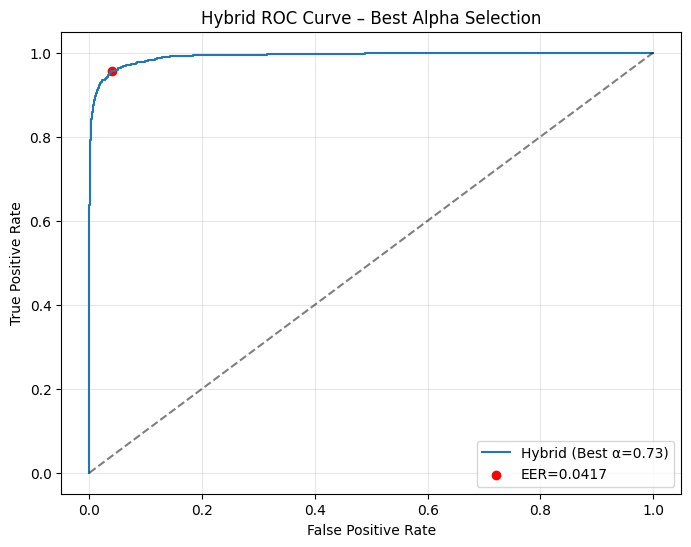

Seed 1 → Hybrid EER: 4.17% (α=0.73)
💾 Saved NEW GLOBAL BEST model (EER=4.17%)

===== Training with seed 2 =====
[DW] Mined 11750 triplets for this epoch.


C:\Users\divya\AppData\Local\Temp\ipykernel_33444\477085210.py:83: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.tensor(dl1, dtype=torch.float32),
C:\Users\divya\AppData\Local\Temp\ipykernel_33444\477085210.py:85: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.tensor(dl2, dtype=torch.float32),
C:\Users\divya\AppData\Local\Temp\ipykernel_33444\1251142332.py:8: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  dl1_tensor = torch.stack([torch.tensor(x, dtype=torch.float32) for x in dl1_list])
C:\Users\divya\AppData\Local\Temp\ipykerne

[DW] Mined 11750 triplets for this epoch.
[DW] Mined 11750 triplets for this epoch.
[DW] Mined 11750 triplets for this epoch.
[DW] Mined 11750 triplets for this epoch.
[DW] Mined 11750 triplets for this epoch.
[DW] Mined 11750 triplets for this epoch.
[DW] Mined 11750 triplets for this epoch.
[DW] Mined 11750 triplets for this epoch.
[DW] Mined 11750 triplets for this epoch.
[DW] Mined 11750 triplets for this epoch.
Computing scores (one-time extraction)...


Eval: 100%|██████████████████████████████████████████████████████████████████████| 20757/20757 [13:47<00:00, 25.08it/s]



=== RAW SCORE STATS ===
DL Scores   : min=-0.9144, max=0.9975
Min Scores  : min=0.0182, max=74.3008

Sample Raw DL Scores: [0.98565376 0.95900637 0.967813   0.97331965 0.9659442  0.94705474
 0.9538983  0.9508405  0.9591063  0.9591331 ]
Sample Raw Min Scores: [67.6110708  60.78575513 61.99341913 61.64579039 21.94901646 69.26823177
 54.68776533 64.00021547 21.82214948 56.37847252]

=== NORMALIZED SCORES ===
Sample DL_norm: [0.9928269  0.97950315 0.9839065  0.9866598  0.9829721  0.9735274
 0.97694916 0.97542024 0.97955316 0.9795666 ]
Sample Min_norm: [0.67611071 0.60785755 0.61993419 0.6164579  0.21949016 0.69268232
 0.54687765 0.64000215 0.21822149 0.56378473]

Alpha = 0.00
EER   = 0.1284
Threshold  = 0.1867

Alpha = 0.01
EER   = 0.1255
Threshold  = 0.1920

Alpha = 0.02
EER   = 0.1261
Threshold  = 0.1954

Alpha = 0.03
EER   = 0.1236
Threshold  = 0.2013

Alpha = 0.04
EER   = 0.1248
Threshold  = 0.2041

Alpha = 0.05
EER   = 0.1217
Threshold  = 0.2107

Alpha = 0.06
EER   = 0.1201
Threshold

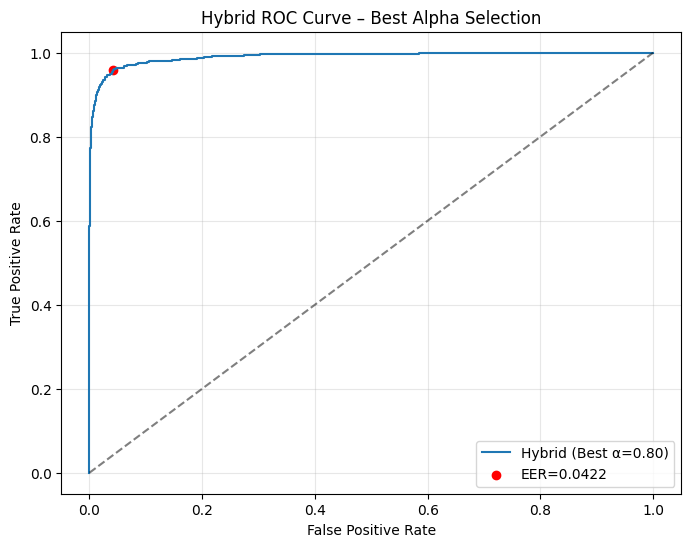

Seed 2 → Hybrid EER: 4.22% (α=0.80)
ℹ️ Model not saved (best=4.17%)

===== Training with seed 3 =====
[DW] Mined 11750 triplets for this epoch.


C:\Users\divya\AppData\Local\Temp\ipykernel_33444\477085210.py:83: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.tensor(dl1, dtype=torch.float32),
C:\Users\divya\AppData\Local\Temp\ipykernel_33444\477085210.py:85: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.tensor(dl2, dtype=torch.float32),
C:\Users\divya\AppData\Local\Temp\ipykernel_33444\1251142332.py:8: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  dl1_tensor = torch.stack([torch.tensor(x, dtype=torch.float32) for x in dl1_list])
C:\Users\divya\AppData\Local\Temp\ipykerne

[DW] Mined 11750 triplets for this epoch.
[DW] Mined 11750 triplets for this epoch.
[DW] Mined 11750 triplets for this epoch.
[DW] Mined 11750 triplets for this epoch.
[DW] Mined 11750 triplets for this epoch.
[DW] Mined 11750 triplets for this epoch.
[DW] Mined 11750 triplets for this epoch.
[DW] Mined 11750 triplets for this epoch.
[DW] Mined 11750 triplets for this epoch.
[DW] Mined 11750 triplets for this epoch.
[DW] Mined 11750 triplets for this epoch.
Computing scores (one-time extraction)...


Eval: 100%|██████████████████████████████████████████████████████████████████████| 20757/20757 [13:48<00:00, 25.07it/s]



=== RAW SCORE STATS ===
DL Scores   : min=-0.9298, max=0.9982
Min Scores  : min=0.0182, max=74.3008

Sample Raw DL Scores: [0.97115844 0.96724063 0.9563756  0.9876092  0.9483247  0.96230817
 0.9192997  0.9853974  0.943086   0.9282524 ]
Sample Raw Min Scores: [67.6110708  60.78575513 61.99341913 61.64579039 21.94901646 69.26823177
 54.68776533 64.00021547 21.82214948 56.37847252]

=== NORMALIZED SCORES ===
Sample DL_norm: [0.98557925 0.9836203  0.9781878  0.9938046  0.97416234 0.9811541
 0.95964986 0.99269867 0.971543   0.9641262 ]
Sample Min_norm: [0.67611071 0.60785755 0.61993419 0.6164579  0.21949016 0.69268232
 0.54687765 0.64000215 0.21822149 0.56378473]

Alpha = 0.00
EER   = 0.1284
Threshold  = 0.1867

Alpha = 0.01
EER   = 0.1254
Threshold  = 0.1919

Alpha = 0.02
EER   = 0.1251
Threshold  = 0.1957

Alpha = 0.03
EER   = 0.1223
Threshold  = 0.2015

Alpha = 0.04
EER   = 0.1259
Threshold  = 0.2024

Alpha = 0.05
EER   = 0.1216
Threshold  = 0.2100

Alpha = 0.06
EER   = 0.1187
Threshold

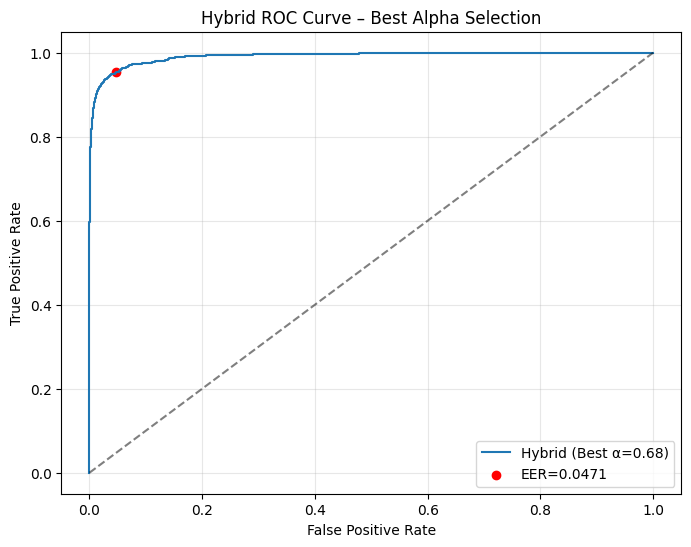

Seed 3 → Hybrid EER: 4.71% (α=0.68)
ℹ️ Model not saved (best=4.17%)

===== Training with seed 4 =====
[DW] Mined 11750 triplets for this epoch.


C:\Users\divya\AppData\Local\Temp\ipykernel_33444\477085210.py:83: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.tensor(dl1, dtype=torch.float32),
C:\Users\divya\AppData\Local\Temp\ipykernel_33444\477085210.py:85: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.tensor(dl2, dtype=torch.float32),
C:\Users\divya\AppData\Local\Temp\ipykernel_33444\1251142332.py:8: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  dl1_tensor = torch.stack([torch.tensor(x, dtype=torch.float32) for x in dl1_list])
C:\Users\divya\AppData\Local\Temp\ipykerne

[DW] Mined 11750 triplets for this epoch.
[DW] Mined 11750 triplets for this epoch.
[DW] Mined 11750 triplets for this epoch.
[DW] Mined 11750 triplets for this epoch.
[DW] Mined 11750 triplets for this epoch.
[DW] Mined 11750 triplets for this epoch.
[DW] Mined 11750 triplets for this epoch.
[DW] Mined 11750 triplets for this epoch.
[DW] Mined 11750 triplets for this epoch.
[DW] Mined 11750 triplets for this epoch.
[DW] Mined 11750 triplets for this epoch.
Computing scores (one-time extraction)...


Eval: 100%|██████████████████████████████████████████████████████████████████████| 20757/20757 [14:16<00:00, 24.25it/s]



=== RAW SCORE STATS ===
DL Scores   : min=-0.9424, max=0.9983
Min Scores  : min=0.0182, max=74.3008

Sample Raw DL Scores: [0.9806341  0.98124266 0.9169444  0.98355407 0.96243453 0.97010803
 0.93725514 0.9745563  0.9821092  0.9418028 ]
Sample Raw Min Scores: [67.6110708  60.78575513 61.99341913 61.64579039 21.94901646 69.26823177
 54.68776533 64.00021547 21.82214948 56.37847252]

=== NORMALIZED SCORES ===
Sample DL_norm: [0.99031705 0.9906213  0.9584722  0.99177706 0.98121727 0.985054
 0.9686276  0.98727816 0.9910546  0.97090137]
Sample Min_norm: [0.67611071 0.60785755 0.61993419 0.6164579  0.21949016 0.69268232
 0.54687765 0.64000215 0.21822149 0.56378473]

Alpha = 0.00
EER   = 0.1284
Threshold  = 0.1867

Alpha = 0.01
EER   = 0.1256
Threshold  = 0.1917

Alpha = 0.02
EER   = 0.1261
Threshold  = 0.1948

Alpha = 0.03
EER   = 0.1220
Threshold  = 0.2014

Alpha = 0.04
EER   = 0.1205
Threshold  = 0.2063

Alpha = 0.05
EER   = 0.1216
Threshold  = 0.2093

Alpha = 0.06
EER   = 0.1188
Threshold 

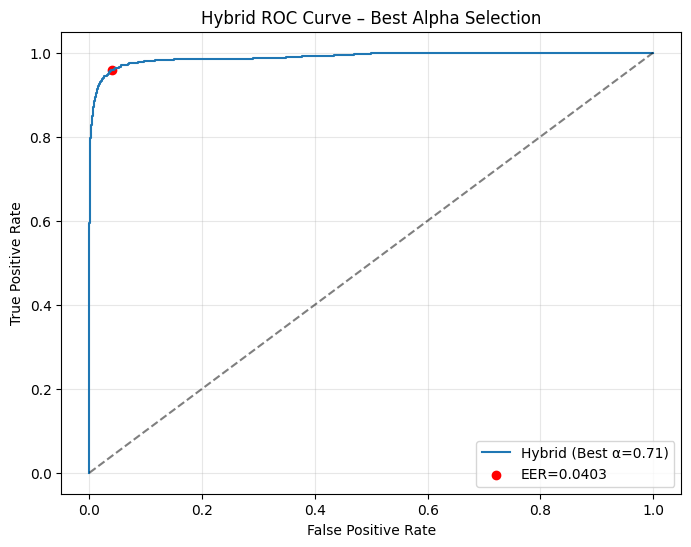

Seed 4 → Hybrid EER: 4.03% (α=0.71)
💾 Saved NEW GLOBAL BEST model (EER=4.03%)

Final Hybrid Result: 4.28% ± 0.26% (across 4 runs)


In [74]:
import copy
import os
import json

GLOBAL_BEST_EER = float("inf")
MODEL_PATH = "best_model_imp_adaptiveTuned.pth"    # where to save your best model
CONFIG_PATH = "model_config_imp_adaptiveTuned.json"

def run_training(seed):
    global GLOBAL_BEST_EER

    print(f"\n===== Training with seed {seed} =====")
    set_seed(seed)

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    num_classes = len(train_dataset_dw.indices_by_class)

    # -------------------------
    # Model
    # -------------------------
    model = FingerprintTripleNet(
        feature_dim=256,
        num_classes=num_classes
    ).to(device)

    # -------------------------
    # Pre-training distance stats
    # -------------------------
    try:
        stats = compute_distance_stats(
            model, train_dataset_dw,
            device=device, embed_batch_size=64, sample_limit=None
        )
    except Exception as e:
        print(f"[WARN] compute_distance_stats failed: {e}")
        stats = None

    gap = float(stats["gap"]) if stats and stats["gap"] > 0 else 1e-4

    hard_multiplier = 1
    semi_multiplier = 1
    max_multiplier = 16.0
    adapt_factor = 1.5

    margin_hard = hard_multiplier * gap
    margin_semi = semi_multiplier * gap

    optimizer = AdamW(model.parameters(), lr=1e-3, weight_decay=1e-5)
    scaler = GradScaler("cuda")

    hard_criterion = HardTripletLoss(margin=margin_hard, log_stats=True)
    semi_criterion = SemiHardTripletLoss(margin=margin_semi, fallback_to_hard=False, log_stats=True)
    ce_criterion = nn.CrossEntropyLoss()

    best_val_loss = float("inf")
    best_model_wts = copy.deepcopy(model.state_dict())
    patience = 5
    no_improve_count = 0
    no_triplet_signal_epochs = 0

    # -------------------------
    # Training loop
    # -------------------------
    for epoch in range(num_epochs):

        model.eval()
        try:
            stats_epoch = compute_distance_stats(
                model, train_dataset_dw,
                device=device, embed_batch_size=64, sample_limit=None
            )
        except Exception:
            stats_epoch = None

        if stats_epoch and stats_epoch["gap"] > 0:
            gap = float(stats_epoch["gap"])
            margin_hard = max(hard_multiplier * gap, 1e-12)
            margin_semi = max(semi_multiplier * gap, 1e-12)
            hard_criterion.margin = min(margin_hard, margin_limit)
            semi_criterion.margin = min(margin_semi, margin_limit)

        triplet_loader = build_global_dw_triplet_loader(
            model,
            train_dataset_dw,
            device=device,
            embed_batch_size=64,
            triplet_batch_size=16,
            max_triplets_per_class=50,
            candidates_per_anchor=200,
            negatives_per_pair=4
        )

        if triplet_loader is None:
            continue

        model.train()
        epoch_num_hard = epoch_num_semi = epoch_num_fallback = 0

        for xa, ya, xp, yp, xn, yn in triplet_loader:
            xa, xp, xn = xa.to(device), xp.to(device), xn.to(device)
            ya, yp, yn = ya.to(device), yp.to(device), yn.to(device)

            optimizer.zero_grad(set_to_none=True)

            with autocast("cuda"):
                a = model.embed(xa)
                p = model.embed(xp)
                n = model.embed(xn)

                h_res = hard_criterion(a, p, n)
                triplet_loss, num_hard = h_res if isinstance(h_res, tuple) else (h_res, 0)

                s_res = semi_criterion(a, p, n)
                if isinstance(s_res, tuple):
                    semi_loss, num_semi, num_fallback = s_res if len(s_res) == 3 else (*s_res, 0)
                else:
                    semi_loss, num_semi, num_fallback = s_res, 0, 0

                ce_loss = (
                    ce_criterion(model.classifier(a), ya) +
                    ce_criterion(model.classifier(p), yp) +
                    ce_criterion(model.classifier(n), yn)
                ) / 3.0

                loss = (
                    lambda_hard * triplet_loss +
                    lambda_semi * semi_loss +
                    lambda_cls * ce_loss
                )

            scaler.scale(loss).backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optimizer)
            scaler.update()

            epoch_num_hard += num_hard
            epoch_num_semi += num_semi
            epoch_num_fallback += num_fallback

        # -------------------------
        # Validation
        # -------------------------
        model.eval()
        all_pos, all_neg = [], []

        with torch.no_grad():
            for batch in val_loader:
                if batch is None:
                    continue
                min1, dl1, min2, dl2, labels = batch
                dl1, dl2, labels = dl1.to(device), dl2.to(device), labels.to(device)
                e1, e2 = model.embed(dl1), model.embed(dl2)
                dist = F.pairwise_distance(e1, e2)
                all_pos.append(dist[labels == 1])
                all_neg.append(dist[labels == 0])

        val_loss = torch.cat(all_pos).mean() - torch.cat(all_neg).mean()

        if val_loss < best_val_loss - 1e-4:
            best_val_loss = val_loss
            best_model_wts = copy.deepcopy(model.state_dict())
            no_improve_count = 0
        else:
            no_improve_count += 1

        if no_improve_count >= patience:
            break

    # -------------------------
    # Final evaluation
    # -------------------------
    model.load_state_dict(best_model_wts)
    eer, threshold, alpha = compute_hybrid_eer_normalized(model, test_loader, device=device)
    eer = eer * 100

    print(f"Seed {seed} → Hybrid EER: {eer:.2f}% (α={alpha:.2f})")

    # -------------------------
    # Save ONLY if globally best
    # -------------------------
    if eer < GLOBAL_BEST_EER:
        GLOBAL_BEST_EER = eer
        torch.save(best_model_wts, MODEL_PATH)
        print(f"💾 Saved NEW GLOBAL BEST model (EER={eer:.2f}%)")

        with open(CONFIG_PATH, "w") as f:
            json.dump({
                "seed": seed,
                "lambda_hard": lambda_hard,
                "lambda_semi": lambda_semi,
                "lambda_cls": lambda_cls,
                "margin_limit": margin_limit,
                "eer": eer
            }, f, indent=4)
    else:
        print(f"ℹ️ Model not saved (best={GLOBAL_BEST_EER:.2f}%)")

    return eer



# =========================
# Run across multiple seeds
# =========================

seeds = [42]
num_epochs = 50

all_eers = []
for s in seeds:
    eer = run_training(s)
    all_eers.append(eer)

mean_eer = np.mean(all_eers)
std_eer = np.std(all_eers)
print(f"\nFinal Hybrid Result: {mean_eer:.2f}% ± {std_eer:.2f}% (across {len(seeds)} runs)")



===== Training with seed 42 =====
🚀 No saved model found → Training from scratch!
[INFO] distance stats: {'median_d_ap': 1.9073486612342094e-07, 'median_d_an': 3.576278970740532e-07, 'gap': 1.6689303095063224e-07, 'p10_ap': 7.152557657263969e-08, 'p90_an': 4.7683712978141557e-07}
[INFO] initial margins -> hard: 1.668930e-07, semi: 1.668930e-07
{'median_d_ap': 1.9073486612342094e-07, 'median_d_an': 3.576278970740532e-07, 'gap': 1.6689303095063224e-07, 'p10_ap': 7.152557657263969e-08, 'p90_an': 4.7683712978141557e-07}
[EPOCH-1] recomputed gap: 1.668930e-07; margins -> hard: 1.668930e-07, semi: 1.668930e-07
[DW] Mined 11750 triplets for this epoch.


Epoch 1 [GLOBAL-DW / Hard+Semi+CE]: 100%|█████████████████████████| 735/735 [00:41<00:00, 17.57it/s, Batch Loss=1.3969]
C:\Users\divya\AppData\Local\Temp\ipykernel_16308\477085210.py:83: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.tensor(dl1, dtype=torch.float32),
C:\Users\divya\AppData\Local\Temp\ipykernel_16308\477085210.py:85: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.tensor(dl2, dtype=torch.float32),
C:\Users\divya\AppData\Local\Temp\ipykernel_16308\1251142332.py:8: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  dl1_t

Epoch 1 [GLOBAL-DW / Hard+Semi+CE]: Train Loss=1.5322, Val Loss=-0.5934
[LOG] semi-hard used: 0, fallback-hard: 0, hard-negatives: 359
✅ New best model at epoch 1
{'median_d_ap': 0.05088811554014683, 'median_d_an': 1.3272904753684998, 'gap': 1.276402359828353, 'p10_ap': 0.022285871766507627, 'p90_an': 1.7188081145286562}
[EPOCH-2] recomputed gap: 1.276402e+00; margins -> hard: 5.691526e-01, semi: 5.691526e-01
[DW] Mined 11750 triplets for this epoch.


Epoch 2 [GLOBAL-DW / Hard+Semi+CE]: 100%|█████████████████████████| 735/735 [00:44<00:00, 16.55it/s, Batch Loss=1.5517]


Epoch 2 [GLOBAL-DW / Hard+Semi+CE]: Train Loss=1.7230, Val Loss=-0.7377
[LOG] semi-hard used: 2951, fallback-hard: 0, hard-negatives: 759
✅ New best model at epoch 2
{'median_d_ap': 0.1265462562441826, 'median_d_an': 1.5455282330513, 'gap': 1.4189819768071175, 'p10_ap': 0.04549502953886986, 'p90_an': 1.9324096560478214}
[EPOCH-3] recomputed gap: 1.418982e+00; margins -> hard: 5.691526e-01, semi: 5.691526e-01
[DW] Mined 11750 triplets for this epoch.


Epoch 3 [GLOBAL-DW / Hard+Semi+CE]: 100%|█████████████████████████| 735/735 [00:45<00:00, 16.32it/s, Batch Loss=1.1050]


... (15 outputs left out)

Epoch 11 [GLOBAL-DW / Hard+Semi+CE]: 100%|████████████████████████| 735/735 [00:36<00:00, 20.37it/s, Batch Loss=0.1632]


Epoch 11 [GLOBAL-DW / Hard+Semi+CE]: Train Loss=0.1754, Val Loss=-0.8412
[LOG] semi-hard used: 344, fallback-hard: 0, hard-negatives: 0
⚠️ No improvement for 5 epoch(s)
⏹ Early stopping triggered at epoch 11
💾 Saved best model to best_model_imp_adaptiveTuned1.pth
📄 Saved config to model_config_imp_adaptiveTuned1.json
Computing scores (one-time extraction)...


Eval: 100%|██████████████████████████████████████████████████████████████████████| 20757/20757 [17:44<00:00, 19.50it/s]



=== RAW SCORE STATS ===
DL Scores   : min=-0.8458, max=0.9910
Min Scores  : min=0.0182, max=74.3008

Sample Raw DL Scores: [0.97515976 0.92476165 0.95134324 0.96975905 0.89415216 0.921853
 0.95470405 0.9428127  0.9149339  0.97739685]
Sample Raw Min Scores: [67.6110708  60.78575513 61.99341913 61.64579039 21.94901646 69.26823177
 54.68776533 64.00021547 21.82214948 56.37847252]

=== NORMALIZED SCORES ===
Sample DL_norm: [0.9875799  0.9623808  0.97567165 0.9848795  0.9470761  0.96092653
 0.977352   0.97140634 0.95746696 0.9886984 ]
Sample Min_norm: [0.67611071 0.60785755 0.61993419 0.6164579  0.21949016 0.69268232
 0.54687765 0.64000215 0.21822149 0.56378473]

Alpha = 0.00
EER   = 0.1284
Threshold  = 0.1867

Alpha = 0.01
EER   = 0.1256
Threshold  = 0.1918

Alpha = 0.02
EER   = 0.1266
Threshold  = 0.1947

Alpha = 0.03
EER   = 0.1243
Threshold  = 0.2004

Alpha = 0.04
EER   = 0.1250
Threshold  = 0.2035

Alpha = 0.05
EER   = 0.1201
Threshold  = 0.2109

Alpha = 0.06
EER   = 0.1207
Threshold 

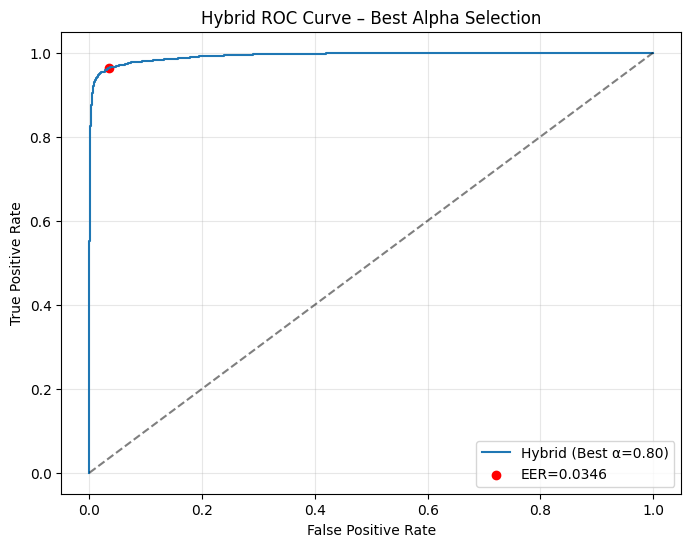

Seed 42 → Hybrid EER: 3.46% (Threshold: 0.6766, α=0.80)

Final Hybrid Result: 3.46% ± 0.00% (across 1 runs)


In [33]:
import copy
import os
import json

MODEL_PATH = "best_model_imp_adaptiveTuned1.pth"    # where to save your best model
CONFIG_PATH = "model_config_imp_adaptiveTuned1.json"

def run_training(seed):
    print(f"\n===== Training with seed {seed} =====")
    set_seed(seed)

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    # --------------------------------------------------
    # If model already exists → load it and skip training
    # --------------------------------------------------
    if os.path.exists(MODEL_PATH):
        print("📌 Found saved model → Loading model instead of training...")
        num_classes = len(train_dataset_dw.indices_by_class)
        model = FingerprintTripleNet(feature_dim=256, num_classes=num_classes).to(device)
        model.load_state_dict(torch.load(MODEL_PATH, map_location=device))
        model.eval()

        eer, threshold, alpha = compute_hybrid_eer_normalized(model, test_loader, device=device)
        print(f"[Loaded Model] Hybrid EER: {eer*100:.2f}% (thr={threshold:.4f}, α={alpha:.2f})")
        return eer * 100

    print("🚀 No saved model found → Training from scratch!")

    num_classes = len(train_dataset_dw.indices_by_class)
    model = FingerprintTripleNet(feature_dim=256, num_classes=num_classes).to(device)

    # --- compute pre-training distance stats (gap) using a fresh model ---
    try:
        stats = compute_distance_stats(model, train_dataset_dw, device=device, embed_batch_size=64, sample_limit=None)
    except Exception as e:
        print(f"[WARN] compute_distance_stats failed: {e}")
        stats = None

    if stats is None or "gap" not in stats or stats["gap"] <= 0.0:
        gap = 1e-4
        print("[WARN] Using fallback gap =", gap)
    else:
        gap = float(stats["gap"])
        print(f"[INFO] distance stats: {stats}")

    # Multipliers — sensible defaults (we keep these mutable for adaptation)
    hard_multiplier = 1
    semi_multiplier = 1

    # safety caps for multipliers to avoid runaway margins
    max_multiplier = 16.0
    adapt_factor = 1.5

    margin_hard = hard_multiplier * gap
    margin_semi = semi_multiplier * gap

    print(f"[INFO] initial margins -> hard: {margin_hard:.6e}, semi: {margin_semi:.6e}")

    optimizer = AdamW(model.parameters(), lr=1e-3, weight_decay=1e-5)

    # 🔥 Losses (enable logging in the loss objects if available)
    hard_criterion = HardTripletLoss(margin=margin_hard, log_stats=True)
    semi_criterion = SemiHardTripletLoss(margin=margin_semi, fallback_to_hard=False, log_stats=True)
    ce_criterion = nn.CrossEntropyLoss()

    # weights
    # lambda_hard=0.2
    # lambda_cls = 0.1    # classification weight (reduced to avoid CE domination)
    # lambda_semi = 1 # semi-hard weight
    # margin_limit = 0.5

    scaler = GradScaler("cuda")

    best_val_loss = float("inf")
    best_model_wts = copy.deepcopy(model.state_dict())
    patience = 5
    no_improve_count = 0

    # adaptive counter for consecutive epochs with no triplet signal
    no_triplet_signal_epochs = 0

    # -------------------------
    # Training loop (GLOBAL DW)
    # -------------------------
    for epoch in range(num_epochs):
        # --- recompute gap using current model before mining (costly but principled) ---
        model.eval()
        try:
            stats_epoch = compute_distance_stats(model, train_dataset_dw, device=device, embed_batch_size=64, sample_limit=None)
            print(stats_epoch)
        except Exception as e:
            print(f"[WARN] compute_distance_stats (epoch) failed: {e}")
            stats_epoch = None

        if stats_epoch is None or "gap" not in stats_epoch or stats_epoch["gap"] <= 0.0:
            # keep previous gap/margins if epoch stats invalid
            print(f"[EPOCH-{epoch+1}] could not recompute gap; keeping previous margins")
        else:
            gap = float(stats_epoch["gap"])
            # ensure minimal sensible multipliers to give semi-hard a chance
            hard_multiplier = max(hard_multiplier,1)
            semi_multiplier = max(semi_multiplier, 1)

            margin_hard = hard_multiplier * gap
            margin_semi = semi_multiplier * gap
            margin_hard = max(margin_hard, 1e-12)
            margin_semi = max(margin_semi, 1e-12)

            hard_criterion.margin = min(margin_hard,margin_limit)
            semi_criterion.margin = min(margin_semi,margin_limit)
            print(f"[EPOCH-{epoch+1}] recomputed gap: {gap:.6e}; margins -> hard: {hard_criterion.margin:.6e}, semi: {semi_criterion.margin:.6e}")

        # 1) Build global DW triplets for THIS epoch using current model (now using updated margins)
        triplet_loader = build_global_dw_triplet_loader(
            model,
            train_dataset_dw,
            device=device,
            embed_batch_size=64,
            triplet_batch_size=16,
            max_triplets_per_class=50,     # per class cap
            candidates_per_anchor=200,
            negatives_per_pair=4            # increase diversity
        )

        if triplet_loader is None:
            print("No triplets mined, skipping epoch.")
            continue

        # build_global_dw_triplet_loader already prints mined triplet count — no duplicate print here

        model.train()
        total_loss = 0.0
        valid_batches = 0

        # Accumulators for logging counts
        epoch_num_hard = 0
        epoch_num_semi = 0
        epoch_num_fallback = 0

        progress_bar = tqdm(
            triplet_loader,
            desc=f'Epoch {epoch+1} [GLOBAL-DW / Hard+Semi+CE]',
            leave=True
        )

        for batch in progress_bar:
            xa, ya, xp, yp, xn, yn = batch
            xa, xp, xn = xa.to(device), xp.to(device), xn.to(device)
            ya, yp, yn = ya.to(device), yp.to(device), yn.to(device)

            optimizer.zero_grad()
            with autocast("cuda"):
                # embeddings
                a_out = model.embed(xa)
                p_out = model.embed(xp)
                n_out = model.embed(xn)

                # triplet losses — robust to return types
                h_res = hard_criterion(a_out, p_out, n_out)
                if isinstance(h_res, tuple):
                    triplet_loss, num_hard = h_res
                else:
                    triplet_loss, num_hard = h_res, 0

                s_res = semi_criterion(a_out, p_out, n_out)
                if isinstance(s_res, tuple):
                    if len(s_res) == 3:
                        semi_loss, num_semi, num_fallback = s_res
                    else:
                        semi_loss, num_semi = s_res[0], s_res[1]
                        num_fallback = 0
                else:
                    semi_loss, num_semi, num_fallback = s_res, 0, 0

                # classification losses for all three
                logits_a = model.classifier(a_out)
                logits_p = model.classifier(p_out)
                logits_n = model.classifier(n_out)

                ce_loss = (
                    ce_criterion(logits_a, ya) +
                    ce_criterion(logits_p, yp) +
                    ce_criterion(logits_n, yn)
                ) / 3.0

                loss = lambda_hard*triplet_loss + lambda_semi * semi_loss + lambda_cls * ce_loss

            # backward / step with amp
            scaler.scale(loss).backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optimizer)
            scaler.update()

            # accumulate
            total_loss += loss.item()
            epoch_num_hard += int(num_hard)
            epoch_num_semi += int(num_semi)
            epoch_num_fallback += int(num_fallback)
            valid_batches += 1
            progress_bar.set_postfix({'Batch Loss': f'{loss.item():.4f}'})

        avg_train_loss = total_loss / max(valid_batches, 1)

        # -------------------------
        # Validation (unchanged)
        # -------------------------
        model.eval()
        val_loss = 0.0
        val_batches = 0

        all_pos = []
        all_neg = []

        with torch.no_grad():
            for batch in val_loader:
                if batch is None:
                    continue

                min1, dl1, min2, dl2, labels = batch
                dl1, dl2, labels = dl1.to(device), dl2.to(device), labels.to(device)

                emb1 = model.embed(dl1)
                emb2 = model.embed(dl2)

                dist = F.pairwise_distance(emb1, emb2)
                # batch_loss = (labels * dist + (1 - labels) * F.relu(1.0 - dist)).mean()
                all_pos.append(dist[labels == 1])
                all_neg.append(dist[labels == 0])

        # concatenate
        all_pos = torch.cat(all_pos)
        all_neg = torch.cat(all_neg)
        
        avg_val_loss = all_pos.mean() - all_neg.mean()


        # Epoch-level logging
        print(
            f"Epoch {epoch+1} [GLOBAL-DW / Hard+Semi+CE]: "
            f"Train Loss={avg_train_loss:.4f}, Val Loss={avg_val_loss:.4f}"
        )
        print(f"[LOG] semi-hard used: {epoch_num_semi}, fallback-hard: {epoch_num_fallback}, hard-negatives: {epoch_num_hard}")

        # -------------------------
        # ADAPTIVE multiplier if triplet signal vanished for a short run
        # -------------------------
        total_triplet_signal = epoch_num_semi + epoch_num_fallback + epoch_num_hard
        if total_triplet_signal == 0:
            no_triplet_signal_epochs += 1
        else:
            no_triplet_signal_epochs = 0

        # If no triplet signal for a couple of epochs, widen multipliers (but cap)
        if no_triplet_signal_epochs >= 1:
            old_hm, old_sm = hard_multiplier, semi_multiplier
            hard_multiplier = min(hard_multiplier * adapt_factor, max_multiplier)
            semi_multiplier = min(semi_multiplier * adapt_factor, max_multiplier)
            margin_hard = hard_multiplier * gap
            margin_semi = semi_multiplier * gap
            hard_criterion.margin = margin_hard
            semi_criterion.margin = margin_semi
            print(f"[ADAPT] triplet-signal empty for {no_triplet_signal_epochs} epoch(s) -> multipliers {old_hm:.2f}->{hard_multiplier:.2f}, {old_sm:.2f}->{semi_multiplier:.2f}")
            print(f"[ADAPT] new margins -> hard: {margin_hard:.6e}, semi: {margin_semi:.6e}")

        # -------------------------
        # Early Stopping Logic
        # -------------------------
        if avg_val_loss < best_val_loss - 1e-4:
            best_val_loss = avg_val_loss
            best_model_wts = copy.deepcopy(model.state_dict())
            no_improve_count = 0
            print(f"✅ New best model at epoch {epoch+1}")
        else:
            no_improve_count += 1
            print(f"⚠️ No improvement for {no_improve_count} epoch(s)")

        if no_improve_count >= patience:
            print(f"⏹ Early stopping triggered at epoch {epoch+1}")
            break

    # restore best
    model.load_state_dict(best_model_wts)

    # ============================
    #     SAVE THE MODEL
    # ============================
    torch.save(best_model_wts, MODEL_PATH)
    print(f"💾 Saved best model to {MODEL_PATH}")

    config = {
        "seed": seed,
        "epochs": num_epochs,
        "lambda_cls": lambda_cls,
        "lambda_semi": lambda_semi,
        "feature_dim": model.feature_dim
    }
    with open(CONFIG_PATH, "w") as f:
        json.dump(config, f, indent=4)
    print(f"📄 Saved config to {CONFIG_PATH}")

    # -------------------------
    # Final Evaluation
    # -------------------------
    eer, threshold, alpha = compute_hybrid_eer_normalized(model, test_loader, device=device)
    print(f"Seed {seed} → Hybrid EER: {eer*100:.2f}% (Threshold: {threshold:.4f}, α={alpha:.2f})")

    return eer * 100



# =========================
# Run across multiple seeds
# =========================
seeds = [42]
num_epochs = 50

all_eers = []
for s in seeds:
    eer = run_training(s)
    all_eers.append(eer)

mean_eer = np.mean(all_eers)
std_eer = np.std(all_eers)
print(f"\nFinal Hybrid Result: {mean_eer:.2f}% ± {std_eer:.2f}% (across {len(seeds)} runs)")



===== Training with seed 42 =====
🚀 No saved model found → Training from scratch!
[INFO] distance stats: {'median_d_ap': 1.9073486612342094e-07, 'median_d_an': 3.576278970740532e-07, 'gap': 1.6689303095063224e-07, 'p10_ap': 7.152557657263969e-08, 'p90_an': 4.7683712978141557e-07}
[INFO] initial margins -> hard: 1.668930e-07, semi: 1.668930e-07
{'median_d_ap': 1.9073486612342094e-07, 'median_d_an': 3.576278970740532e-07, 'gap': 1.6689303095063224e-07, 'p10_ap': 7.152557657263969e-08, 'p90_an': 4.7683712978141557e-07}
[EPOCH-1] recomputed gap: 1.668930e-07; margins -> hard: 1.668930e-07, semi: 1.668930e-07
[DW] Mined 11750 triplets for this epoch.


Epoch 1 [GLOBAL-DW / Hard+Semi+CE]: 100%|█████████████████████████| 735/735 [00:43<00:00, 16.71it/s, Batch Loss=1.8050]
C:\Users\divya\AppData\Local\Temp\ipykernel_19020\477085210.py:83: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.tensor(dl1, dtype=torch.float32),
C:\Users\divya\AppData\Local\Temp\ipykernel_19020\477085210.py:85: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.tensor(dl2, dtype=torch.float32),
C:\Users\divya\AppData\Local\Temp\ipykernel_19020\1251142332.py:8: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  dl1_t

Epoch 1 [GLOBAL-DW / Hard+Semi+CE]: Train Loss=1.9867, Val Loss=-0.6517
[LOG] semi-hard used: 0, fallback-hard: 0, hard-negatives: 356
✅ New best model at epoch 1
{'median_d_ap': 0.06254102289676666, 'median_d_an': 1.5606812834739685, 'gap': 1.4981402605772018, 'p10_ap': 0.02937205005437136, 'p90_an': 1.8790385365486146}
[EPOCH-2] recomputed gap: 1.498140e+00; margins -> hard: 5.991650e-01, semi: 5.991650e-01
[DW] Mined 11750 triplets for this epoch.


Epoch 2 [GLOBAL-DW / Hard+Semi+CE]: 100%|█████████████████████████| 735/735 [00:43<00:00, 16.71it/s, Batch Loss=2.0051]


Epoch 2 [GLOBAL-DW / Hard+Semi+CE]: Train Loss=2.0444, Val Loss=-0.7805
[LOG] semi-hard used: 3430, fallback-hard: 0, hard-negatives: 653
✅ New best model at epoch 2
{'median_d_ap': 0.11382454261183739, 'median_d_an': 1.4841829538345337, 'gap': 1.3703584112226963, 'p10_ap': 0.03973159268498421, 'p90_an': 1.9731632947921756}
[EPOCH-3] recomputed gap: 1.370358e+00; margins -> hard: 5.991650e-01, semi: 5.991650e-01
[DW] Mined 11750 triplets for this epoch.


Epoch 3 [GLOBAL-DW / Hard+Semi+CE]: 100%|█████████████████████████| 735/735 [00:42<00:00, 17.19it/s, Batch Loss=1.2325]


... (17 outputs left out)

Epoch 12 [GLOBAL-DW / Hard+Semi+CE]: 100%|████████████████████████| 735/735 [00:43<00:00, 16.91it/s, Batch Loss=0.1144]


Epoch 12 [GLOBAL-DW / Hard+Semi+CE]: Train Loss=0.0857, Val Loss=-0.8445
[LOG] semi-hard used: 200, fallback-hard: 0, hard-negatives: 0
⚠️ No improvement for 5 epoch(s)
⏹ Early stopping triggered at epoch 12
💾 Saved best model to best_model_imp_adaptiveTuned2.pth
📄 Saved config to model_config_imp_adaptiveTuned2.json
Computing scores (one-time extraction)...


Eval: 100%|██████████████████████████████████████████████████████████████████████| 20757/20757 [14:40<00:00, 23.58it/s]



=== RAW SCORE STATS ===
DL Scores   : min=-0.8510, max=0.9971
Min Scores  : min=0.0182, max=74.3008

Sample Raw DL Scores: [0.98932123 0.9432502  0.9813454  0.95547515 0.90524375 0.9410521
 0.98648167 0.9588661  0.9354249  0.9708589 ]
Sample Raw Min Scores: [67.6110708  60.78575513 61.99341913 61.64579039 21.94901646 69.26823177
 54.68776533 64.00021547 21.82214948 56.37847252]

=== NORMALIZED SCORES ===
Sample DL_norm: [0.9946606  0.9716251  0.9906727  0.97773755 0.9526219  0.97052604
 0.99324083 0.97943306 0.96771246 0.9854294 ]
Sample Min_norm: [0.67611071 0.60785755 0.61993419 0.6164579  0.21949016 0.69268232
 0.54687765 0.64000215 0.21822149 0.56378473]

Alpha = 0.00
EER   = 0.1284
Threshold  = 0.1867

Alpha = 0.01
EER   = 0.1261
Threshold  = 0.1916

Alpha = 0.02
EER   = 0.1228
Threshold  = 0.1976

Alpha = 0.03
EER   = 0.1223
Threshold  = 0.2015

Alpha = 0.04
EER   = 0.1224
Threshold  = 0.2049

Alpha = 0.05
EER   = 0.1218
Threshold  = 0.2090

Alpha = 0.06
EER   = 0.1186
Threshold

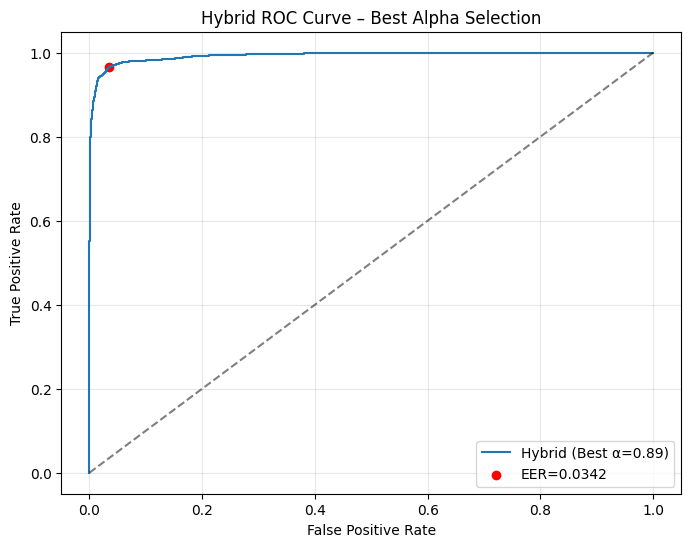

Seed 42 → Hybrid EER: 3.42% (Threshold: 0.7130, α=0.89)

Final Hybrid Result: 3.42% ± 0.00% (across 1 runs)


In [34]:
import copy
import os
import json

MODEL_PATH = "best_model_imp_adaptiveTuned2.pth"    # where to save your best model
CONFIG_PATH = "model_config_imp_adaptiveTuned2.json"

def run_training(seed):
    print(f"\n===== Training with seed {seed} =====")
    set_seed(seed)

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    # --------------------------------------------------
    # If model already exists → load it and skip training
    # --------------------------------------------------
    if os.path.exists(MODEL_PATH):
        print("📌 Found saved model → Loading model instead of training...")
        num_classes = len(train_dataset_dw.indices_by_class)
        model = FingerprintTripleNet(feature_dim=256, num_classes=num_classes).to(device)
        model.load_state_dict(torch.load(MODEL_PATH, map_location=device))
        model.eval()

        eer, threshold, alpha = compute_hybrid_eer_normalized(model, test_loader, device=device)
        print(f"[Loaded Model] Hybrid EER: {eer*100:.2f}% (thr={threshold:.4f}, α={alpha:.2f})")
        return eer * 100

    print("🚀 No saved model found → Training from scratch!")

    num_classes = len(train_dataset_dw.indices_by_class)
    model = FingerprintTripleNet(feature_dim=256, num_classes=num_classes).to(device)

    # --- compute pre-training distance stats (gap) using a fresh model ---
    try:
        stats = compute_distance_stats(model, train_dataset_dw, device=device, embed_batch_size=64, sample_limit=None)
    except Exception as e:
        print(f"[WARN] compute_distance_stats failed: {e}")
        stats = None

    if stats is None or "gap" not in stats or stats["gap"] <= 0.0:
        gap = 1e-4
        print("[WARN] Using fallback gap =", gap)
    else:
        gap = float(stats["gap"])
        print(f"[INFO] distance stats: {stats}")

    # Multipliers — sensible defaults (we keep these mutable for adaptation)
    hard_multiplier = 1
    semi_multiplier = 1

    # safety caps for multipliers to avoid runaway margins
    max_multiplier = 16.0
    adapt_factor = 1.5

    margin_hard = hard_multiplier * gap
    margin_semi = semi_multiplier * gap

    print(f"[INFO] initial margins -> hard: {margin_hard:.6e}, semi: {margin_semi:.6e}")

    optimizer = AdamW(model.parameters(), lr=1e-3, weight_decay=1e-5)

    # 🔥 Losses (enable logging in the loss objects if available)
    hard_criterion = HardTripletLoss(margin=margin_hard, log_stats=True)
    semi_criterion = SemiHardTripletLoss(margin=margin_semi, fallback_to_hard=False, log_stats=True)
    ce_criterion = nn.CrossEntropyLoss()

    # weights
    # lambda_hard=0.2
    # lambda_cls = 0.1    # classification weight (reduced to avoid CE domination)
    # lambda_semi = 1 # semi-hard weight
    # margin_limit = 0.5

    scaler = GradScaler("cuda")

    best_val_loss = float("inf")
    best_model_wts = copy.deepcopy(model.state_dict())
    patience = 5
    no_improve_count = 0

    # adaptive counter for consecutive epochs with no triplet signal
    no_triplet_signal_epochs = 0

    # -------------------------
    # Training loop (GLOBAL DW)
    # -------------------------
    for epoch in range(num_epochs):
        # --- recompute gap using current model before mining (costly but principled) ---
        model.eval()
        try:
            stats_epoch = compute_distance_stats(model, train_dataset_dw, device=device, embed_batch_size=64, sample_limit=None)
            print(stats_epoch)
        except Exception as e:
            print(f"[WARN] compute_distance_stats (epoch) failed: {e}")
            stats_epoch = None

        if stats_epoch is None or "gap" not in stats_epoch or stats_epoch["gap"] <= 0.0:
            # keep previous gap/margins if epoch stats invalid
            print(f"[EPOCH-{epoch+1}] could not recompute gap; keeping previous margins")
        else:
            gap = float(stats_epoch["gap"])
            # ensure minimal sensible multipliers to give semi-hard a chance
            hard_multiplier = max(hard_multiplier,1)
            semi_multiplier = max(semi_multiplier, 1)

            margin_hard = hard_multiplier * gap
            margin_semi = semi_multiplier * gap
            margin_hard = max(margin_hard, 1e-12)
            margin_semi = max(margin_semi, 1e-12)

            hard_criterion.margin = min(margin_hard,margin_limit)
            semi_criterion.margin = min(margin_semi,margin_limit)
            print(f"[EPOCH-{epoch+1}] recomputed gap: {gap:.6e}; margins -> hard: {hard_criterion.margin:.6e}, semi: {semi_criterion.margin:.6e}")

        # 1) Build global DW triplets for THIS epoch using current model (now using updated margins)
        triplet_loader = build_global_dw_triplet_loader(
            model,
            train_dataset_dw,
            device=device,
            embed_batch_size=64,
            triplet_batch_size=16,
            max_triplets_per_class=50,     # per class cap
            candidates_per_anchor=200,
            negatives_per_pair=4            # increase diversity
        )

        if triplet_loader is None:
            print("No triplets mined, skipping epoch.")
            continue

        # build_global_dw_triplet_loader already prints mined triplet count — no duplicate print here

        model.train()
        total_loss = 0.0
        valid_batches = 0

        # Accumulators for logging counts
        epoch_num_hard = 0
        epoch_num_semi = 0
        epoch_num_fallback = 0

        progress_bar = tqdm(
            triplet_loader,
            desc=f'Epoch {epoch+1} [GLOBAL-DW / Hard+Semi+CE]',
            leave=True
        )

        for batch in progress_bar:
            xa, ya, xp, yp, xn, yn = batch
            xa, xp, xn = xa.to(device), xp.to(device), xn.to(device)
            ya, yp, yn = ya.to(device), yp.to(device), yn.to(device)

            optimizer.zero_grad()
            with autocast("cuda"):
                # embeddings
                a_out = model.embed(xa)
                p_out = model.embed(xp)
                n_out = model.embed(xn)

                # triplet losses — robust to return types
                h_res = hard_criterion(a_out, p_out, n_out)
                if isinstance(h_res, tuple):
                    triplet_loss, num_hard = h_res
                else:
                    triplet_loss, num_hard = h_res, 0

                s_res = semi_criterion(a_out, p_out, n_out)
                if isinstance(s_res, tuple):
                    if len(s_res) == 3:
                        semi_loss, num_semi, num_fallback = s_res
                    else:
                        semi_loss, num_semi = s_res[0], s_res[1]
                        num_fallback = 0
                else:
                    semi_loss, num_semi, num_fallback = s_res, 0, 0

                # classification losses for all three
                logits_a = model.classifier(a_out)
                logits_p = model.classifier(p_out)
                logits_n = model.classifier(n_out)

                ce_loss = (
                    ce_criterion(logits_a, ya) +
                    ce_criterion(logits_p, yp) +
                    ce_criterion(logits_n, yn)
                ) / 3.0

                loss = lambda_hard*triplet_loss + lambda_semi * semi_loss + lambda_cls * ce_loss

            # backward / step with amp
            scaler.scale(loss).backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optimizer)
            scaler.update()

            # accumulate
            total_loss += loss.item()
            epoch_num_hard += int(num_hard)
            epoch_num_semi += int(num_semi)
            epoch_num_fallback += int(num_fallback)
            valid_batches += 1
            progress_bar.set_postfix({'Batch Loss': f'{loss.item():.4f}'})

        avg_train_loss = total_loss / max(valid_batches, 1)

        # -------------------------
        # Validation (unchanged)
        # -------------------------
        model.eval()
        val_loss = 0.0
        val_batches = 0

        all_pos = []
        all_neg = []

        with torch.no_grad():
            for batch in val_loader:
                if batch is None:
                    continue

                min1, dl1, min2, dl2, labels = batch
                dl1, dl2, labels = dl1.to(device), dl2.to(device), labels.to(device)

                emb1 = model.embed(dl1)
                emb2 = model.embed(dl2)

                dist = F.pairwise_distance(emb1, emb2)
                # batch_loss = (labels * dist + (1 - labels) * F.relu(1.0 - dist)).mean()
                all_pos.append(dist[labels == 1])
                all_neg.append(dist[labels == 0])

        # concatenate
        all_pos = torch.cat(all_pos)
        all_neg = torch.cat(all_neg)
        
        avg_val_loss = all_pos.mean() - all_neg.mean()


        # Epoch-level logging
        print(
            f"Epoch {epoch+1} [GLOBAL-DW / Hard+Semi+CE]: "
            f"Train Loss={avg_train_loss:.4f}, Val Loss={avg_val_loss:.4f}"
        )
        print(f"[LOG] semi-hard used: {epoch_num_semi}, fallback-hard: {epoch_num_fallback}, hard-negatives: {epoch_num_hard}")

        # -------------------------
        # ADAPTIVE multiplier if triplet signal vanished for a short run
        # -------------------------
        total_triplet_signal = epoch_num_semi + epoch_num_fallback + epoch_num_hard
        if total_triplet_signal == 0:
            no_triplet_signal_epochs += 1
        else:
            no_triplet_signal_epochs = 0

        # If no triplet signal for a couple of epochs, widen multipliers (but cap)
        if no_triplet_signal_epochs >= 1:
            old_hm, old_sm = hard_multiplier, semi_multiplier
            hard_multiplier = min(hard_multiplier * adapt_factor, max_multiplier)
            semi_multiplier = min(semi_multiplier * adapt_factor, max_multiplier)
            margin_hard = hard_multiplier * gap
            margin_semi = semi_multiplier * gap
            hard_criterion.margin = margin_hard
            semi_criterion.margin = margin_semi
            print(f"[ADAPT] triplet-signal empty for {no_triplet_signal_epochs} epoch(s) -> multipliers {old_hm:.2f}->{hard_multiplier:.2f}, {old_sm:.2f}->{semi_multiplier:.2f}")
            print(f"[ADAPT] new margins -> hard: {margin_hard:.6e}, semi: {margin_semi:.6e}")

        # -------------------------
        # Early Stopping Logic
        # -------------------------
        if avg_val_loss < best_val_loss - 1e-4:
            best_val_loss = avg_val_loss
            best_model_wts = copy.deepcopy(model.state_dict())
            no_improve_count = 0
            print(f"✅ New best model at epoch {epoch+1}")
        else:
            no_improve_count += 1
            print(f"⚠️ No improvement for {no_improve_count} epoch(s)")

        if no_improve_count >= patience:
            print(f"⏹ Early stopping triggered at epoch {epoch+1}")
            break

    # restore best
    model.load_state_dict(best_model_wts)

    # ============================
    #     SAVE THE MODEL
    # ============================
    torch.save(best_model_wts, MODEL_PATH)
    print(f"💾 Saved best model to {MODEL_PATH}")

    config = {
        "seed": seed,
        "epochs": num_epochs,
        "lambda_cls": lambda_cls,
        "lambda_semi": lambda_semi,
        "feature_dim": model.feature_dim
    }
    with open(CONFIG_PATH, "w") as f:
        json.dump(config, f, indent=4)
    print(f"📄 Saved config to {CONFIG_PATH}")

    # -------------------------
    # Final Evaluation
    # -------------------------
    eer, threshold, alpha = compute_hybrid_eer_normalized(model, test_loader, device=device)
    print(f"Seed {seed} → Hybrid EER: {eer*100:.2f}% (Threshold: {threshold:.4f}, α={alpha:.2f})")

    return eer * 100



# =========================
# Run across multiple seeds
# =========================
seeds = [42]
num_epochs = 50

all_eers = []
for s in seeds:
    eer = run_training(s)
    all_eers.append(eer)

mean_eer = np.mean(all_eers)
std_eer = np.std(all_eers)
print(f"\nFinal Hybrid Result: {mean_eer:.2f}% ± {std_eer:.2f}% (across {len(seeds)} runs)")



===== Training with seed 42 =====
🚀 No saved model found → Training from scratch!
[INFO] distance stats: {'median_d_ap': 1.9073486612342094e-07, 'median_d_an': 3.576278970740532e-07, 'gap': 1.6689303095063224e-07, 'p10_ap': 7.152557657263969e-08, 'p90_an': 4.7683712978141557e-07}
[INFO] initial margins -> hard: 1.668930e-07, semi: 1.668930e-07
{'median_d_ap': 1.9073486612342094e-07, 'median_d_an': 3.576278970740532e-07, 'gap': 1.6689303095063224e-07, 'p10_ap': 7.152557657263969e-08, 'p90_an': 4.7683712978141557e-07}
[EPOCH-1] recomputed gap: 1.668930e-07; margins -> hard: 1.668930e-07, semi: 1.668930e-07
[DW] Mined 11750 triplets for this epoch.


Epoch 1 [GLOBAL-DW / Hard+Semi+CE]: 100%|█████████████████████████| 735/735 [00:43<00:00, 16.76it/s, Batch Loss=0.5878]
C:\Users\divya\AppData\Local\Temp\ipykernel_19020\477085210.py:83: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.tensor(dl1, dtype=torch.float32),
C:\Users\divya\AppData\Local\Temp\ipykernel_19020\477085210.py:85: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.tensor(dl2, dtype=torch.float32),
C:\Users\divya\AppData\Local\Temp\ipykernel_19020\1251142332.py:8: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  dl1_t

Epoch 1 [GLOBAL-DW / Hard+Semi+CE]: Train Loss=0.6946, Val Loss=-0.8645
[LOG] semi-hard used: 0, fallback-hard: 0, hard-negatives: 615
✅ New best model at epoch 1
{'median_d_ap': 0.06070188991725445, 'median_d_an': 1.928862452507019, 'gap': 1.8681605625897646, 'p10_ap': 0.024892366863787173, 'p90_an': 2.220473289489746}
[EPOCH-2] recomputed gap: 1.868161e+00; margins -> hard: 5.258075e-01, semi: 5.258075e-01
[DW] Mined 11750 triplets for this epoch.


Epoch 2 [GLOBAL-DW / Hard+Semi+CE]: 100%|█████████████████████████| 735/735 [00:45<00:00, 16.01it/s, Batch Loss=0.6805]


Epoch 2 [GLOBAL-DW / Hard+Semi+CE]: Train Loss=0.9950, Val Loss=-0.6697
[LOG] semi-hard used: 3135, fallback-hard: 0, hard-negatives: 635
⚠️ No improvement for 1 epoch(s)
{'median_d_ap': 0.1177377887070179, 'median_d_an': 1.2464925646781921, 'gap': 1.1287547759711742, 'p10_ap': 0.045987246185541154, 'p90_an': 1.7423073768615724}
[EPOCH-3] recomputed gap: 1.128755e+00; margins -> hard: 5.258075e-01, semi: 5.258075e-01
[DW] Mined 11750 triplets for this epoch.


Epoch 3 [GLOBAL-DW / Hard+Semi+CE]: 100%|█████████████████████████| 735/735 [00:44<00:00, 16.34it/s, Batch Loss=0.5564]


... (19 outputs left out)

Epoch 13 [GLOBAL-DW / Hard+Semi+CE]: 100%|████████████████████████| 735/735 [00:41<00:00, 17.87it/s, Batch Loss=0.1622]


Epoch 13 [GLOBAL-DW / Hard+Semi+CE]: Train Loss=0.1038, Val Loss=-0.8124
[LOG] semi-hard used: 269, fallback-hard: 0, hard-negatives: 0
⚠️ No improvement for 5 epoch(s)
⏹ Early stopping triggered at epoch 13
💾 Saved best model to best_model_imp_adaptiveTuned3.pth
📄 Saved config to model_config_imp_adaptiveTuned3.json
Computing scores (one-time extraction)...


Eval: 100%|██████████████████████████████████████████████████████████████████████| 20757/20757 [19:13<00:00, 17.99it/s]



=== RAW SCORE STATS ===
DL Scores   : min=-0.8592, max=0.9963
Min Scores  : min=0.0182, max=74.3008

Sample Raw DL Scores: [0.96124536 0.96401834 0.97109485 0.9654349  0.947816   0.9609158
 0.9480573  0.98503315 0.94852334 0.97979116]
Sample Raw Min Scores: [67.6110708  60.78575513 61.99341913 61.64579039 21.94901646 69.26823177
 54.68776533 64.00021547 21.82214948 56.37847252]

=== NORMALIZED SCORES ===
Sample DL_norm: [0.98062265 0.9820092  0.9855474  0.98271745 0.973908   0.9804579
 0.97402865 0.9925166  0.97426164 0.9898956 ]
Sample Min_norm: [0.67611071 0.60785755 0.61993419 0.6164579  0.21949016 0.69268232
 0.54687765 0.64000215 0.21822149 0.56378473]

Alpha = 0.00
EER   = 0.1284
Threshold  = 0.1867

Alpha = 0.01
EER   = 0.1254
Threshold  = 0.1917

Alpha = 0.02
EER   = 0.1252
Threshold  = 0.1953

Alpha = 0.03
EER   = 0.1236
Threshold  = 0.2002

Alpha = 0.04
EER   = 0.1232
Threshold  = 0.2041

Alpha = 0.05
EER   = 0.1220
Threshold  = 0.2087

Alpha = 0.06
EER   = 0.1169
Threshold 

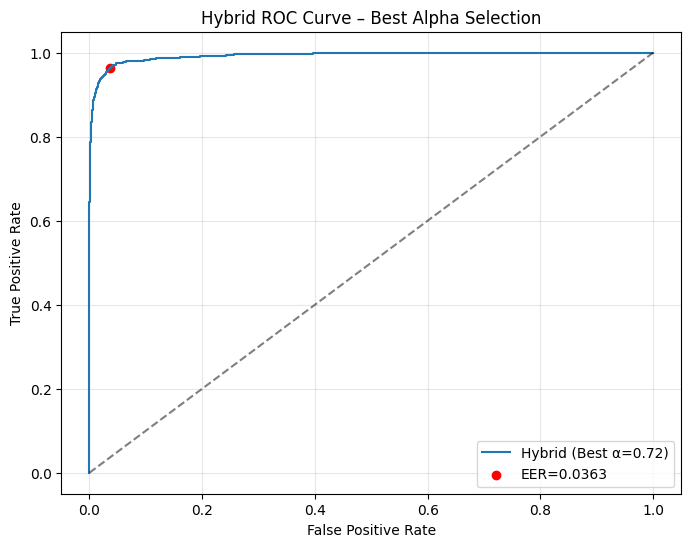

Seed 42 → Hybrid EER: 3.63% (Threshold: 0.6193, α=0.72)

Final Hybrid Result: 3.63% ± 0.00% (across 1 runs)


In [43]:
import copy
import os
import json

MODEL_PATH = "best_model_imp_adaptiveTuned3.pth"    # where to save your best model
CONFIG_PATH = "model_config_imp_adaptiveTuned3.json"

def run_training(seed):
    print(f"\n===== Training with seed {seed} =====")
    set_seed(seed)

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    # --------------------------------------------------
    # If model already exists → load it and skip training
    # --------------------------------------------------
    if os.path.exists(MODEL_PATH):
        print("📌 Found saved model → Loading model instead of training...")
        num_classes = len(train_dataset_dw.indices_by_class)
        model = FingerprintTripleNet(feature_dim=256, num_classes=num_classes).to(device)
        model.load_state_dict(torch.load(MODEL_PATH, map_location=device))
        model.eval()

        eer, threshold, alpha = compute_hybrid_eer_normalized(model, test_loader, device=device)
        print(f"[Loaded Model] Hybrid EER: {eer*100:.2f}% (thr={threshold:.4f}, α={alpha:.2f})")
        return eer * 100

    print("🚀 No saved model found → Training from scratch!")

    num_classes = len(train_dataset_dw.indices_by_class)
    model = FingerprintTripleNet(feature_dim=256, num_classes=num_classes).to(device)

    # --- compute pre-training distance stats (gap) using a fresh model ---
    try:
        stats = compute_distance_stats(model, train_dataset_dw, device=device, embed_batch_size=64, sample_limit=None)
    except Exception as e:
        print(f"[WARN] compute_distance_stats failed: {e}")
        stats = None

    if stats is None or "gap" not in stats or stats["gap"] <= 0.0:
        gap = 1e-4
        print("[WARN] Using fallback gap =", gap)
    else:
        gap = float(stats["gap"])
        print(f"[INFO] distance stats: {stats}")

    # Multipliers — sensible defaults (we keep these mutable for adaptation)
    hard_multiplier = 1
    semi_multiplier = 1

    # safety caps for multipliers to avoid runaway margins
    max_multiplier = 16.0
    adapt_factor = 1.5

    margin_hard = hard_multiplier * gap
    margin_semi = semi_multiplier * gap

    print(f"[INFO] initial margins -> hard: {margin_hard:.6e}, semi: {margin_semi:.6e}")

    optimizer = AdamW(model.parameters(), lr=1e-3, weight_decay=1e-5)

    # 🔥 Losses (enable logging in the loss objects if available)
    hard_criterion = HardTripletLoss(margin=margin_hard, log_stats=True)
    semi_criterion = SemiHardTripletLoss(margin=margin_semi, fallback_to_hard=False, log_stats=True)
    ce_criterion = nn.CrossEntropyLoss()

    # weights
    # lambda_hard=0.2
    # lambda_cls = 0.1    # classification weight (reduced to avoid CE domination)
    # lambda_semi = 1 # semi-hard weight
    # margin_limit = 0.5

    scaler = GradScaler("cuda")

    best_val_loss = float("inf")
    best_model_wts = copy.deepcopy(model.state_dict())
    patience = 5
    no_improve_count = 0

    # adaptive counter for consecutive epochs with no triplet signal
    no_triplet_signal_epochs = 0

    # -------------------------
    # Training loop (GLOBAL DW)
    # -------------------------
    for epoch in range(num_epochs):
        # --- recompute gap using current model before mining (costly but principled) ---
        model.eval()
        try:
            stats_epoch = compute_distance_stats(model, train_dataset_dw, device=device, embed_batch_size=64, sample_limit=None)
            print(stats_epoch)
        except Exception as e:
            print(f"[WARN] compute_distance_stats (epoch) failed: {e}")
            stats_epoch = None

        if stats_epoch is None or "gap" not in stats_epoch or stats_epoch["gap"] <= 0.0:
            # keep previous gap/margins if epoch stats invalid
            print(f"[EPOCH-{epoch+1}] could not recompute gap; keeping previous margins")
        else:
            gap = float(stats_epoch["gap"])
            # ensure minimal sensible multipliers to give semi-hard a chance
            hard_multiplier = max(hard_multiplier,1)
            semi_multiplier = max(semi_multiplier, 1)

            margin_hard = hard_multiplier * gap
            margin_semi = semi_multiplier * gap
            margin_hard = max(margin_hard, 1e-12)
            margin_semi = max(margin_semi, 1e-12)

            hard_criterion.margin = min(margin_hard,margin_limit)
            semi_criterion.margin = min(margin_semi,margin_limit)
            print(f"[EPOCH-{epoch+1}] recomputed gap: {gap:.6e}; margins -> hard: {hard_criterion.margin:.6e}, semi: {semi_criterion.margin:.6e}")

        # 1) Build global DW triplets for THIS epoch using current model (now using updated margins)
        triplet_loader = build_global_dw_triplet_loader(
            model,
            train_dataset_dw,
            device=device,
            embed_batch_size=64,
            triplet_batch_size=16,
            max_triplets_per_class=50,     # per class cap
            candidates_per_anchor=200,
            negatives_per_pair=4            # increase diversity
        )

        if triplet_loader is None:
            print("No triplets mined, skipping epoch.")
            continue

        # build_global_dw_triplet_loader already prints mined triplet count — no duplicate print here

        model.train()
        total_loss = 0.0
        valid_batches = 0

        # Accumulators for logging counts
        epoch_num_hard = 0
        epoch_num_semi = 0
        epoch_num_fallback = 0

        progress_bar = tqdm(
            triplet_loader,
            desc=f'Epoch {epoch+1} [GLOBAL-DW / Hard+Semi+CE]',
            leave=True
        )

        for batch in progress_bar:
            xa, ya, xp, yp, xn, yn = batch
            xa, xp, xn = xa.to(device), xp.to(device), xn.to(device)
            ya, yp, yn = ya.to(device), yp.to(device), yn.to(device)

            optimizer.zero_grad()
            with autocast("cuda"):
                # embeddings
                a_out = model.embed(xa)
                p_out = model.embed(xp)
                n_out = model.embed(xn)

                # triplet losses — robust to return types
                h_res = hard_criterion(a_out, p_out, n_out)
                if isinstance(h_res, tuple):
                    triplet_loss, num_hard = h_res
                else:
                    triplet_loss, num_hard = h_res, 0

                s_res = semi_criterion(a_out, p_out, n_out)
                if isinstance(s_res, tuple):
                    if len(s_res) == 3:
                        semi_loss, num_semi, num_fallback = s_res
                    else:
                        semi_loss, num_semi = s_res[0], s_res[1]
                        num_fallback = 0
                else:
                    semi_loss, num_semi, num_fallback = s_res, 0, 0

                # classification losses for all three
                logits_a = model.classifier(a_out)
                logits_p = model.classifier(p_out)
                logits_n = model.classifier(n_out)

                ce_loss = (
                    ce_criterion(logits_a, ya) +
                    ce_criterion(logits_p, yp) +
                    ce_criterion(logits_n, yn)
                ) / 3.0

                loss = lambda_hard*triplet_loss + lambda_semi * semi_loss + lambda_cls * ce_loss

            # backward / step with amp
            scaler.scale(loss).backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optimizer)
            scaler.update()

            # accumulate
            total_loss += loss.item()
            epoch_num_hard += int(num_hard)
            epoch_num_semi += int(num_semi)
            epoch_num_fallback += int(num_fallback)
            valid_batches += 1
            progress_bar.set_postfix({'Batch Loss': f'{loss.item():.4f}'})

        avg_train_loss = total_loss / max(valid_batches, 1)

        # -------------------------
        # Validation (unchanged)
        # -------------------------
        model.eval()
        val_loss = 0.0
        val_batches = 0

        all_pos = []
        all_neg = []

        with torch.no_grad():
            for batch in val_loader:
                if batch is None:
                    continue

                min1, dl1, min2, dl2, labels = batch
                dl1, dl2, labels = dl1.to(device), dl2.to(device), labels.to(device)

                emb1 = model.embed(dl1)
                emb2 = model.embed(dl2)

                dist = F.pairwise_distance(emb1, emb2)
                # batch_loss = (labels * dist + (1 - labels) * F.relu(1.0 - dist)).mean()
                all_pos.append(dist[labels == 1])
                all_neg.append(dist[labels == 0])

        # concatenate
        all_pos = torch.cat(all_pos)
        all_neg = torch.cat(all_neg)
        
        avg_val_loss = all_pos.mean() - all_neg.mean()


        # Epoch-level logging
        print(
            f"Epoch {epoch+1} [GLOBAL-DW / Hard+Semi+CE]: "
            f"Train Loss={avg_train_loss:.4f}, Val Loss={avg_val_loss:.4f}"
        )
        print(f"[LOG] semi-hard used: {epoch_num_semi}, fallback-hard: {epoch_num_fallback}, hard-negatives: {epoch_num_hard}")

        # -------------------------
        # ADAPTIVE multiplier if triplet signal vanished for a short run
        # -------------------------
        total_triplet_signal = epoch_num_semi + epoch_num_fallback + epoch_num_hard
        if total_triplet_signal == 0:
            no_triplet_signal_epochs += 1
        else:
            no_triplet_signal_epochs = 0

        # If no triplet signal for a couple of epochs, widen multipliers (but cap)
        if no_triplet_signal_epochs >= 1:
            old_hm, old_sm = hard_multiplier, semi_multiplier
            hard_multiplier = min(hard_multiplier * adapt_factor, max_multiplier)
            semi_multiplier = min(semi_multiplier * adapt_factor, max_multiplier)
            margin_hard = hard_multiplier * gap
            margin_semi = semi_multiplier * gap
            hard_criterion.margin = margin_hard
            semi_criterion.margin = margin_semi
            print(f"[ADAPT] triplet-signal empty for {no_triplet_signal_epochs} epoch(s) -> multipliers {old_hm:.2f}->{hard_multiplier:.2f}, {old_sm:.2f}->{semi_multiplier:.2f}")
            print(f"[ADAPT] new margins -> hard: {margin_hard:.6e}, semi: {margin_semi:.6e}")

        # -------------------------
        # Early Stopping Logic
        # -------------------------
        if avg_val_loss < best_val_loss - 1e-4:
            best_val_loss = avg_val_loss
            best_model_wts = copy.deepcopy(model.state_dict())
            no_improve_count = 0
            print(f"✅ New best model at epoch {epoch+1}")
        else:
            no_improve_count += 1
            print(f"⚠️ No improvement for {no_improve_count} epoch(s)")

        if no_improve_count >= patience:
            print(f"⏹ Early stopping triggered at epoch {epoch+1}")
            break

    # restore best
    model.load_state_dict(best_model_wts)

    # ============================
    #     SAVE THE MODEL
    # ============================
    torch.save(best_model_wts, MODEL_PATH)
    print(f"💾 Saved best model to {MODEL_PATH}")

    config = {
        "seed": seed,
        "epochs": num_epochs,
        "lambda_cls": lambda_cls,
        "lambda_semi": lambda_semi,
        "feature_dim": model.feature_dim
    }
    with open(CONFIG_PATH, "w") as f:
        json.dump(config, f, indent=4)
    print(f"📄 Saved config to {CONFIG_PATH}")

    # -------------------------
    # Final Evaluation
    # -------------------------
    eer, threshold, alpha = compute_hybrid_eer_normalized(model, test_loader, device=device)
    print(f"Seed {seed} → Hybrid EER: {eer*100:.2f}% (Threshold: {threshold:.4f}, α={alpha:.2f})")

    return eer * 100



# =========================
# Run across multiple seeds
# =========================
seeds = [42]
num_epochs = 50

all_eers = []
for s in seeds:
    eer = run_training(s)
    all_eers.append(eer)

mean_eer = np.mean(all_eers)
std_eer = np.std(all_eers)
print(f"\nFinal Hybrid Result: {mean_eer:.2f}% ± {std_eer:.2f}% (across {len(seeds)} runs)")



===== Training with seed 42 =====
🚀 No saved model found → Training from scratch!
[INFO] distance stats: {'median_d_ap': 1.9073486612342094e-07, 'median_d_an': 3.576278970740532e-07, 'gap': 1.6689303095063224e-07, 'p10_ap': 7.152557657263969e-08, 'p90_an': 4.7683712978141557e-07}
[INFO] initial margins -> hard: 1.668930e-07, semi: 1.668930e-07
{'median_d_ap': 1.9073486612342094e-07, 'median_d_an': 3.576278970740532e-07, 'gap': 1.6689303095063224e-07, 'p10_ap': 7.152557657263969e-08, 'p90_an': 4.7683712978141557e-07}
[EPOCH-1] recomputed gap: 1.668930e-07; margins -> hard: 1.668930e-07, semi: 1.668930e-07
[DW] Mined 11750 triplets for this epoch.


Epoch 1 [GLOBAL-DW / Hard+Semi+CE]: 100%|█████████████████████████| 735/735 [00:36<00:00, 20.28it/s, Batch Loss=1.7826]
C:\Users\divya\AppData\Local\Temp\ipykernel_11024\477085210.py:83: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.tensor(dl1, dtype=torch.float32),
C:\Users\divya\AppData\Local\Temp\ipykernel_11024\477085210.py:85: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.tensor(dl2, dtype=torch.float32),
C:\Users\divya\AppData\Local\Temp\ipykernel_11024\1251142332.py:8: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  dl1_t

Epoch 1 [GLOBAL-DW / Hard+Semi+CE]: Train Loss=1.9387, Val Loss=-0.3636
[LOG] semi-hard used: 0, fallback-hard: 0, hard-negatives: 309
✅ New best model at epoch 1
{'median_d_ap': 0.06772588193416595, 'median_d_an': 1.0337151288986206, 'gap': 0.9659892469644547, 'p10_ap': 0.034570514038205144, 'p90_an': 1.2729754209518434}
[EPOCH-2] recomputed gap: 9.659892e-01; margins -> hard: 5.991650e-01, semi: 5.991650e-01
[DW] Mined 11750 triplets for this epoch.


Epoch 2 [GLOBAL-DW / Hard+Semi+CE]: 100%|█████████████████████████| 735/735 [00:41<00:00, 17.56it/s, Batch Loss=1.7477]


Epoch 2 [GLOBAL-DW / Hard+Semi+CE]: Train Loss=2.0104, Val Loss=-0.7223
[LOG] semi-hard used: 3023, fallback-hard: 0, hard-negatives: 977
✅ New best model at epoch 2
{'median_d_ap': 0.10224123299121857, 'median_d_an': 1.2880229949951172, 'gap': 1.1857817620038986, 'p10_ap': 0.03286148682236671, 'p90_an': 1.8631652116775514}
[EPOCH-3] recomputed gap: 1.185782e+00; margins -> hard: 5.991650e-01, semi: 5.991650e-01
[DW] Mined 11750 triplets for this epoch.


Epoch 3 [GLOBAL-DW / Hard+Semi+CE]: 100%|█████████████████████████| 735/735 [00:52<00:00, 14.10it/s, Batch Loss=1.2581]


... (17 outputs left out)

Epoch 12 [GLOBAL-DW / Hard+Semi+CE]: 100%|████████████████████████| 735/735 [00:34<00:00, 21.44it/s, Batch Loss=0.3279]


Epoch 12 [GLOBAL-DW / Hard+Semi+CE]: Train Loss=0.2037, Val Loss=-0.8051
[LOG] semi-hard used: 565, fallback-hard: 0, hard-negatives: 0
⚠️ No improvement for 5 epoch(s)
⏹ Early stopping triggered at epoch 12
💾 Saved best model to best_model_imp_adaptiveTuned4.pth
📄 Saved config to model_config_imp_adaptiveTuned4.json
Computing scores (one-time extraction)...


Eval: 100%|██████████████████████████████████████████████████████████████████████| 20757/20757 [17:31<00:00, 19.74it/s]



=== RAW SCORE STATS ===
DL Scores   : min=-0.8361, max=0.9915
Min Scores  : min=0.0182, max=74.3008

Sample Raw DL Scores: [0.9459359  0.96717536 0.9565104  0.96855843 0.9296387  0.9375603
 0.96365035 0.9184138  0.92405736 0.9264847 ]
Sample Raw Min Scores: [67.6110708  60.78575513 61.99341913 61.64579039 21.94901646 69.26823177
 54.68776533 64.00021547 21.82214948 56.37847252]

=== NORMALIZED SCORES ===
Sample DL_norm: [0.972968   0.9835877  0.9782552  0.9842792  0.9648193  0.96878016
 0.9818252  0.95920694 0.9620287  0.96324235]
Sample Min_norm: [0.67611071 0.60785755 0.61993419 0.6164579  0.21949016 0.69268232
 0.54687765 0.64000215 0.21822149 0.56378473]

Alpha = 0.00
EER   = 0.1284
Threshold  = 0.1867

Alpha = 0.01
EER   = 0.1256
Threshold  = 0.1916

Alpha = 0.02
EER   = 0.1228
Threshold  = 0.1975

Alpha = 0.03
EER   = 0.1237
Threshold  = 0.2000

Alpha = 0.04
EER   = 0.1218
Threshold  = 0.2048

Alpha = 0.05
EER   = 0.1209
Threshold  = 0.2089

Alpha = 0.06
EER   = 0.1175
Threshold

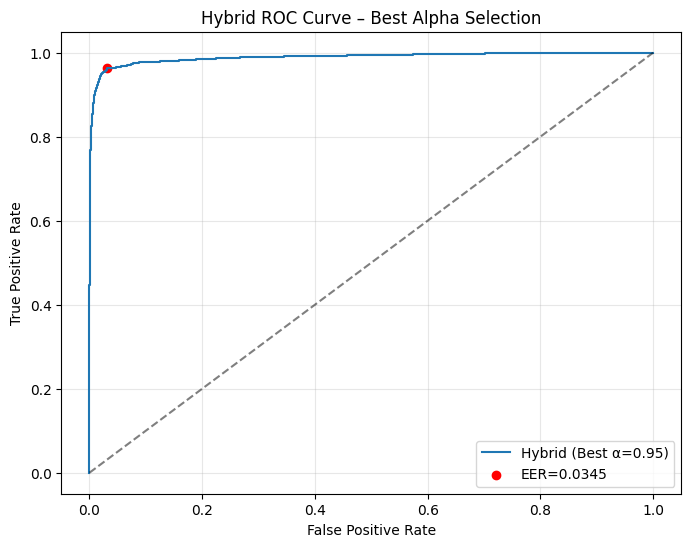

Seed 42 → Hybrid EER: 3.45% (Threshold: 0.7588, α=0.95)

Final Hybrid Result: 3.45% ± 0.00% (across 1 runs)


In [32]:
import copy
import os
import json

MODEL_PATH = "best_model_imp_adaptiveTuned4.pth"    # where to save your best model
CONFIG_PATH = "model_config_imp_adaptiveTuned4.json"

def run_training(seed):
    print(f"\n===== Training with seed {seed} =====")
    set_seed(seed)

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    # --------------------------------------------------
    # If model already exists → load it and skip training
    # --------------------------------------------------
    if os.path.exists(MODEL_PATH):
        print("📌 Found saved model → Loading model instead of training...")
        num_classes = len(train_dataset_dw.indices_by_class)
        model = FingerprintTripleNet(feature_dim=256, num_classes=num_classes).to(device)
        model.load_state_dict(torch.load(MODEL_PATH, map_location=device))
        model.eval()

        eer, threshold, alpha = compute_hybrid_eer_normalized(model, test_loader, device=device)
        print(f"[Loaded Model] Hybrid EER: {eer*100:.2f}% (thr={threshold:.4f}, α={alpha:.2f})")
        return eer * 100

    print("🚀 No saved model found → Training from scratch!")

    num_classes = len(train_dataset_dw.indices_by_class)
    model = FingerprintTripleNet(feature_dim=256, num_classes=num_classes).to(device)

    # --- compute pre-training distance stats (gap) using a fresh model ---
    try:
        stats = compute_distance_stats(model, train_dataset_dw, device=device, embed_batch_size=64, sample_limit=None)
    except Exception as e:
        print(f"[WARN] compute_distance_stats failed: {e}")
        stats = None

    if stats is None or "gap" not in stats or stats["gap"] <= 0.0:
        gap = 1e-4
        print("[WARN] Using fallback gap =", gap)
    else:
        gap = float(stats["gap"])
        print(f"[INFO] distance stats: {stats}")

    # Multipliers — sensible defaults (we keep these mutable for adaptation)
    hard_multiplier = 1
    semi_multiplier = 1

    # safety caps for multipliers to avoid runaway margins
    max_multiplier = 16.0
    adapt_factor = 1.5

    margin_hard = hard_multiplier * gap
    margin_semi = semi_multiplier * gap

    print(f"[INFO] initial margins -> hard: {margin_hard:.6e}, semi: {margin_semi:.6e}")

    optimizer = AdamW(model.parameters(), lr=1e-3, weight_decay=1e-5)

    # 🔥 Losses (enable logging in the loss objects if available)
    hard_criterion = HardTripletLoss(margin=margin_hard, log_stats=True)
    semi_criterion = SemiHardTripletLoss(margin=margin_semi, fallback_to_hard=False, log_stats=True)
    ce_criterion = nn.CrossEntropyLoss()

    # weights
    # lambda_hard=0.2
    # lambda_cls = 0.1    # classification weight (reduced to avoid CE domination)
    # lambda_semi = 1 # semi-hard weight
    # margin_limit = 0.5

    scaler = GradScaler("cuda")

    best_val_loss = float("inf")
    best_model_wts = copy.deepcopy(model.state_dict())
    patience = 5
    no_improve_count = 0

    # adaptive counter for consecutive epochs with no triplet signal
    no_triplet_signal_epochs = 0

    # -------------------------
    # Training loop (GLOBAL DW)
    # -------------------------
    for epoch in range(num_epochs):
        # --- recompute gap using current model before mining (costly but principled) ---
        model.eval()
        try:
            stats_epoch = compute_distance_stats(model, train_dataset_dw, device=device, embed_batch_size=64, sample_limit=None)
            print(stats_epoch)
        except Exception as e:
            print(f"[WARN] compute_distance_stats (epoch) failed: {e}")
            stats_epoch = None

        if stats_epoch is None or "gap" not in stats_epoch or stats_epoch["gap"] <= 0.0:
            # keep previous gap/margins if epoch stats invalid
            print(f"[EPOCH-{epoch+1}] could not recompute gap; keeping previous margins")
        else:
            gap = float(stats_epoch["gap"])
            # ensure minimal sensible multipliers to give semi-hard a chance
            hard_multiplier = max(hard_multiplier,1)
            semi_multiplier = max(semi_multiplier, 1)

            margin_hard = hard_multiplier * gap
            margin_semi = semi_multiplier * gap
            margin_hard = max(margin_hard, 1e-12)
            margin_semi = max(margin_semi, 1e-12)

            hard_criterion.margin = min(margin_hard,margin_limit)
            semi_criterion.margin = min(margin_semi,margin_limit)
            print(f"[EPOCH-{epoch+1}] recomputed gap: {gap:.6e}; margins -> hard: {hard_criterion.margin:.6e}, semi: {semi_criterion.margin:.6e}")

        # 1) Build global DW triplets for THIS epoch using current model (now using updated margins)
        triplet_loader = build_global_dw_triplet_loader(
            model,
            train_dataset_dw,
            device=device,
            embed_batch_size=64,
            triplet_batch_size=16,
            max_triplets_per_class=50,     # per class cap
            candidates_per_anchor=200,
            negatives_per_pair=4            # increase diversity
        )

        if triplet_loader is None:
            print("No triplets mined, skipping epoch.")
            continue

        # build_global_dw_triplet_loader already prints mined triplet count — no duplicate print here

        model.train()
        total_loss = 0.0
        valid_batches = 0

        # Accumulators for logging counts
        epoch_num_hard = 0
        epoch_num_semi = 0
        epoch_num_fallback = 0

        progress_bar = tqdm(
            triplet_loader,
            desc=f'Epoch {epoch+1} [GLOBAL-DW / Hard+Semi+CE]',
            leave=True
        )

        for batch in progress_bar:
            xa, ya, xp, yp, xn, yn = batch
            xa, xp, xn = xa.to(device), xp.to(device), xn.to(device)
            ya, yp, yn = ya.to(device), yp.to(device), yn.to(device)

            optimizer.zero_grad()
            with autocast("cuda"):
                # embeddings
                a_out = model.embed(xa)
                p_out = model.embed(xp)
                n_out = model.embed(xn)

                # triplet losses — robust to return types
                h_res = hard_criterion(a_out, p_out, n_out)
                if isinstance(h_res, tuple):
                    triplet_loss, num_hard = h_res
                else:
                    triplet_loss, num_hard = h_res, 0

                s_res = semi_criterion(a_out, p_out, n_out)
                if isinstance(s_res, tuple):
                    if len(s_res) == 3:
                        semi_loss, num_semi, num_fallback = s_res
                    else:
                        semi_loss, num_semi = s_res[0], s_res[1]
                        num_fallback = 0
                else:
                    semi_loss, num_semi, num_fallback = s_res, 0, 0

                # classification losses for all three
                logits_a = model.classifier(a_out)
                logits_p = model.classifier(p_out)
                logits_n = model.classifier(n_out)

                ce_loss = (
                    ce_criterion(logits_a, ya) +
                    ce_criterion(logits_p, yp) +
                    ce_criterion(logits_n, yn)
                ) / 3.0

                loss = 0*triplet_loss + lambda_semi * semi_loss + lambda_cls * ce_loss

            # backward / step with amp
            scaler.scale(loss).backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optimizer)
            scaler.update()

            # accumulate
            total_loss += loss.item()
            epoch_num_hard += int(num_hard)
            epoch_num_semi += int(num_semi)
            epoch_num_fallback += int(num_fallback)
            valid_batches += 1
            progress_bar.set_postfix({'Batch Loss': f'{loss.item():.4f}'})

        avg_train_loss = total_loss / max(valid_batches, 1)

        # -------------------------
        # Validation (unchanged)
        # -------------------------
        model.eval()
        val_loss = 0.0
        val_batches = 0

        all_pos = []
        all_neg = []

        with torch.no_grad():
            for batch in val_loader:
                if batch is None:
                    continue

                min1, dl1, min2, dl2, labels = batch
                dl1, dl2, labels = dl1.to(device), dl2.to(device), labels.to(device)

                emb1 = model.embed(dl1)
                emb2 = model.embed(dl2)

                dist = F.pairwise_distance(emb1, emb2)
                # batch_loss = (labels * dist + (1 - labels) * F.relu(1.0 - dist)).mean()
                all_pos.append(dist[labels == 1])
                all_neg.append(dist[labels == 0])

        # concatenate
        all_pos = torch.cat(all_pos)
        all_neg = torch.cat(all_neg)
        
        avg_val_loss = all_pos.mean() - all_neg.mean()


        # Epoch-level logging
        print(
            f"Epoch {epoch+1} [GLOBAL-DW / Hard+Semi+CE]: "
            f"Train Loss={avg_train_loss:.4f}, Val Loss={avg_val_loss:.4f}"
        )
        print(f"[LOG] semi-hard used: {epoch_num_semi}, fallback-hard: {epoch_num_fallback}, hard-negatives: {epoch_num_hard}")

        # -------------------------
        # ADAPTIVE multiplier if triplet signal vanished for a short run
        # -------------------------
        total_triplet_signal = epoch_num_semi + epoch_num_fallback + epoch_num_hard
        if total_triplet_signal == 0:
            no_triplet_signal_epochs += 1
        else:
            no_triplet_signal_epochs = 0

        # If no triplet signal for a couple of epochs, widen multipliers (but cap)
        if no_triplet_signal_epochs >= 1:
            old_hm, old_sm = hard_multiplier, semi_multiplier
            hard_multiplier = min(hard_multiplier * adapt_factor, max_multiplier)
            semi_multiplier = min(semi_multiplier * adapt_factor, max_multiplier)
            margin_hard = hard_multiplier * gap
            margin_semi = semi_multiplier * gap
            hard_criterion.margin = margin_hard
            semi_criterion.margin = margin_semi
            print(f"[ADAPT] triplet-signal empty for {no_triplet_signal_epochs} epoch(s) -> multipliers {old_hm:.2f}->{hard_multiplier:.2f}, {old_sm:.2f}->{semi_multiplier:.2f}")
            print(f"[ADAPT] new margins -> hard: {margin_hard:.6e}, semi: {margin_semi:.6e}")

        # -------------------------
        # Early Stopping Logic
        # -------------------------
        if avg_val_loss < best_val_loss - 1e-4:
            best_val_loss = avg_val_loss
            best_model_wts = copy.deepcopy(model.state_dict())
            no_improve_count = 0
            print(f"✅ New best model at epoch {epoch+1}")
        else:
            no_improve_count += 1
            print(f"⚠️ No improvement for {no_improve_count} epoch(s)")

        if no_improve_count >= patience:
            print(f"⏹ Early stopping triggered at epoch {epoch+1}")
            break

    # restore best
    model.load_state_dict(best_model_wts)

    # ============================
    #     SAVE THE MODEL
    # ============================
    torch.save(best_model_wts, MODEL_PATH)
    print(f"💾 Saved best model to {MODEL_PATH}")

    config = {
        "seed": seed,
        "epochs": num_epochs,
        "lambda_cls": lambda_cls,
        "lambda_semi": lambda_semi,
        "feature_dim": model.feature_dim
    }
    with open(CONFIG_PATH, "w") as f:
        json.dump(config, f, indent=4)
    print(f"📄 Saved config to {CONFIG_PATH}")

    # -------------------------
    # Final Evaluation
    # -------------------------
    eer, threshold, alpha = compute_hybrid_eer_normalized(model, test_loader, device=device)
    print(f"Seed {seed} → Hybrid EER: {eer*100:.2f}% (Threshold: {threshold:.4f}, α={alpha:.2f})")

    return eer * 100



# =========================
# Run across multiple seeds
# =========================
seeds = [42]
num_epochs = 50

all_eers = []
for s in seeds:
    eer = run_training(s)
    all_eers.append(eer)

mean_eer = np.mean(all_eers)
std_eer = np.std(all_eers)
print(f"\nFinal Hybrid Result: {mean_eer:.2f}% ± {std_eer:.2f}% (across {len(seeds)} runs)")


In [29]:
import os
import json
import numpy as np

RESULTS_PATH = os.path.join(os.getcwd(), "ablation_results.json")

def append_results(title, values, path=RESULTS_PATH):
    title = str(title)

    # Load existing results
    try:
        if os.path.exists(path):
            with open(path, "r") as f:
                data = json.load(f)
        else:
            data = {}
    except json.JSONDecodeError:
        print("Warning: Existing JSON file is corrupted. Overwriting.")
        data = {}
    except Exception as e:
        print(f"Error while reading results file: {e}")
        return

    # Append / overwrite experiment entry
    data[title] = values

    # Write results back
    try:
        with open(path, "w") as f:
            json.dump(data, f, indent=4)
        print(f"Results saved successfully at: {os.path.abspath(path)}")
    except Exception as e:
        print(f"Error while writing results file: {e}")


In [33]:
append_results("Hello",[1,2],RESULTS_PATH)

Working


In [39]:
import numpy as np

# Dummy experiment title
title = "Ablation_no_hard"

# Dummy scalar values
eer = 3.42
threshold = 0.58
alpha = 0.75
lambda_cls = 1.0
lambda_semi = 0.5
lambda_hard = 0.0
margin_limit = 0.2
MODEL_PATH = "models/triplenet_ablation_no_hard.pth"
# Dummy NumPy array (combined_score)
combined_score = np.random.rand(10)  # 10 similarity scores

try:
    combined_score_serializable = combined_score.tolist()
except Exception as e:
    print(f"Error converting combined_score: {e}")
    combined_score_serializable = None

results_entry = {
    "EER_percent": float(eer),
    "threshold": float(threshold),
    "alpha": float(alpha),
    "combined_score": combined_score_serializable,
    "lambda_cls": float(lambda_cls),
    "lambda_semi": float(lambda_semi),
    "lambda_hard": float(lambda_hard),
    "margin_limit": float(margin_limit),
    "model_path": str(MODEL_PATH)
}

append_results(title, results_entry)


Results saved successfully at: D:\sp2-20240124T210502Z-001\sp2\BTP\TripleNet\ablation_results.json



===== Training with seed 42 =====
📌 Found saved model → Loading model instead of training...
Computing scores (one-time extraction)...


Eval:   0%|                                                                                  | 0/20757 [00:00<?, ?it/s]C:\Users\divya\AppData\Local\Temp\ipykernel_3792\477085210.py:83: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.tensor(dl1, dtype=torch.float32),
C:\Users\divya\AppData\Local\Temp\ipykernel_3792\477085210.py:85: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.tensor(dl2, dtype=torch.float32),
C:\Users\divya\AppData\Local\Temp\ipykernel_3792\1251142332.py:8: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  dl1_tenso


=== RAW SCORE STATS ===
DL Scores   : min=-0.9273, max=0.9987
Min Scores  : min=0.0182, max=74.3008

Sample Raw DL Scores: [0.99772465 0.9431332  0.93969834 0.9912364  0.9649806  0.94892627
 0.9392064  0.98916817 0.97020125 0.9217912 ]
Sample Raw Min Scores: [67.6110708  60.78575513 61.99341913 61.64579039 21.94901646 69.26823177
 54.68776533 64.00021547 21.82214948 56.37847252]

=== NORMALIZED SCORES ===
Sample DL_norm: [0.9988623  0.97156656 0.96984917 0.9956182  0.9824903  0.9744631
 0.9696032  0.9945841  0.9851006  0.9608956 ]
Sample Min_norm: [0.67611071 0.60785755 0.61993419 0.6164579  0.21949016 0.69268232
 0.54687765 0.64000215 0.21822149 0.56378473]

Alpha = 0.00
EER   = 0.1284
Threshold  = 0.1867

Alpha = 0.01
EER   = 0.1257
Threshold  = 0.1916

Alpha = 0.02
EER   = 0.1242
Threshold  = 0.1965

Alpha = 0.03
EER   = 0.1237
Threshold  = 0.2005

Alpha = 0.04
EER   = 0.1208
Threshold  = 0.2062

Alpha = 0.05
EER   = 0.1224
Threshold  = 0.2089

Alpha = 0.06
EER   = 0.1172
Threshold

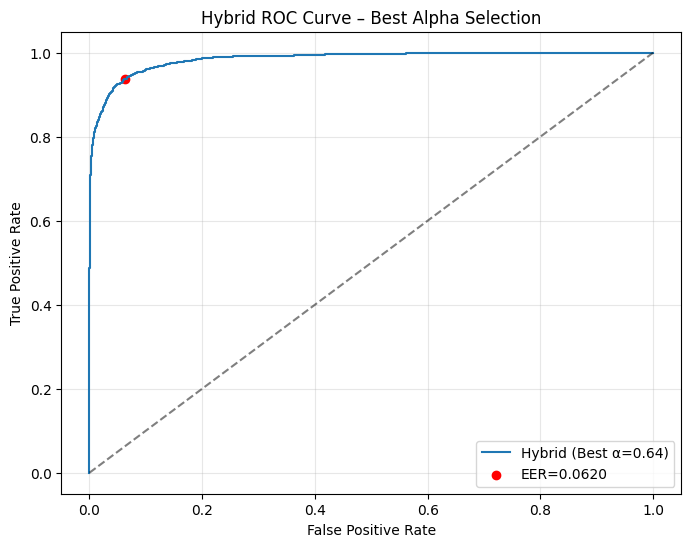

Results saved successfully at: D:\sp2-20240124T210502Z-001\sp2\BTP\TripleNet\ablation_results.json
[Loaded Model] Hybrid EER: 6.20% (thr=0.5728, α=0.64)

Final Hybrid Result: 6.20% ± 0.00% (across 1 runs)


In [58]:
import copy
import os
import json

MODEL_PATH = "best_model_imp_adaptiveTuned5.pth"    # where to save your best model
CONFIG_PATH = "model_config_imp_adaptiveTuned5.json"

def run_training(seed):
    print(f"\n===== Training with seed {seed} =====")
    set_seed(seed)

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    # --------------------------------------------------
    # If model already exists → load it and skip training
    # --------------------------------------------------
    if os.path.exists(MODEL_PATH):
        print("📌 Found saved model → Loading model instead of training...")
        num_classes = len(train_dataset_dw.indices_by_class)
        model = FingerprintTripleNet(feature_dim=256, num_classes=num_classes).to(device)
        model.load_state_dict(torch.load(MODEL_PATH, map_location=device))
        model.eval()

        eer, threshold, alpha, combined_score = compute_hybrid_eer_normalized(model, test_loader, device=device)

        title = f"lambda_cls=0"

        try:
            combined_score_serializable = combined_score.tolist()
        except Exception as e:
            print(f"Error converting combined_score to list: {e}")
            combined_score_serializable = None
        
        results_entry = {
            "EER_percent": float(eer),
            "threshold": float(threshold),
            "alpha": float(alpha),
            "combined_score": combined_score_serializable,
            "lambda_cls": float(lambda_cls),
            "lambda_semi": float(lambda_semi),
            "lambda_hard": float(lambda_hard),
            "margin_limit": float(margin_limit),
            "model_path": str(MODEL_PATH)
        }
        
        append_results(title, results_entry)
        print(f"[Loaded Model] Hybrid EER: {eer*100:.2f}% (thr={threshold:.4f}, α={alpha:.2f})")
        return eer * 100

    print("🚀 No saved model found → Training from scratch!")

    num_classes = len(train_dataset_dw.indices_by_class)
    model = FingerprintTripleNet(feature_dim=256, num_classes=num_classes).to(device)

    # --- compute pre-training distance stats (gap) using a fresh model ---
    try:
        stats = compute_distance_stats(model, train_dataset_dw, device=device, embed_batch_size=64, sample_limit=None)
    except Exception as e:
        print(f"[WARN] compute_distance_stats failed: {e}")
        stats = None

    if stats is None or "gap" not in stats or stats["gap"] <= 0.0:
        gap = 1e-4
        print("[WARN] Using fallback gap =", gap)
    else:
        gap = float(stats["gap"])
        print(f"[INFO] distance stats: {stats}")

    # Multipliers — sensible defaults (we keep these mutable for adaptation)
    hard_multiplier = 1
    semi_multiplier = 1

    # safety caps for multipliers to avoid runaway margins
    max_multiplier = 16.0
    adapt_factor = 1.5

    margin_hard = hard_multiplier * gap
    margin_semi = semi_multiplier * gap

    print(f"[INFO] initial margins -> hard: {margin_hard:.6e}, semi: {margin_semi:.6e}")

    optimizer = AdamW(model.parameters(), lr=1e-3, weight_decay=1e-5)

    # 🔥 Losses (enable logging in the loss objects if available)
    hard_criterion = HardTripletLoss(margin=margin_hard, log_stats=True)
    semi_criterion = SemiHardTripletLoss(margin=margin_semi, fallback_to_hard=False, log_stats=True)
    ce_criterion = nn.CrossEntropyLoss()

    # weights
    # lambda_hard=0.2
    # lambda_cls = 0.1    # classification weight (reduced to avoid CE domination)
    # lambda_semi = 1 # semi-hard weight
    # margin_limit = 0.5

    scaler = GradScaler("cuda")

    best_val_loss = float("inf")
    best_model_wts = copy.deepcopy(model.state_dict())
    patience = 5
    no_improve_count = 0

    # adaptive counter for consecutive epochs with no triplet signal
    no_triplet_signal_epochs = 0

    # -------------------------
    # Training loop (GLOBAL DW)
    # -------------------------
    for epoch in range(num_epochs):
        # --- recompute gap using current model before mining (costly but principled) ---
        model.eval()
        try:
            stats_epoch = compute_distance_stats(model, train_dataset_dw, device=device, embed_batch_size=64, sample_limit=None)
            print(stats_epoch)
        except Exception as e:
            print(f"[WARN] compute_distance_stats (epoch) failed: {e}")
            stats_epoch = None

        if stats_epoch is None or "gap" not in stats_epoch or stats_epoch["gap"] <= 0.0:
            # keep previous gap/margins if epoch stats invalid
            print(f"[EPOCH-{epoch+1}] could not recompute gap; keeping previous margins")
        else:
            gap = float(stats_epoch["gap"])
            # ensure minimal sensible multipliers to give semi-hard a chance
            hard_multiplier = max(hard_multiplier,1)
            semi_multiplier = max(semi_multiplier, 1)

            margin_hard = hard_multiplier * gap
            margin_semi = semi_multiplier * gap
            margin_hard = max(margin_hard, 1e-12)
            margin_semi = max(margin_semi, 1e-12)

            hard_criterion.margin = min(margin_hard,margin_limit)
            semi_criterion.margin = min(margin_semi,margin_limit)
            print(f"[EPOCH-{epoch+1}] recomputed gap: {gap:.6e}; margins -> hard: {hard_criterion.margin:.6e}, semi: {semi_criterion.margin:.6e}")

        # 1) Build global DW triplets for THIS epoch using current model (now using updated margins)
        triplet_loader = build_global_dw_triplet_loader(
            model,
            train_dataset_dw,
            device=device,
            embed_batch_size=64,
            triplet_batch_size=16,
            max_triplets_per_class=50,     # per class cap
            candidates_per_anchor=200,
            negatives_per_pair=4            # increase diversity
        )

        if triplet_loader is None:
            print("No triplets mined, skipping epoch.")
            continue

        # build_global_dw_triplet_loader already prints mined triplet count — no duplicate print here

        model.train()
        total_loss = 0.0
        valid_batches = 0

        # Accumulators for logging counts
        epoch_num_hard = 0
        epoch_num_semi = 0
        epoch_num_fallback = 0

        progress_bar = tqdm(
            triplet_loader,
            desc=f'Epoch {epoch+1} [GLOBAL-DW / Hard+Semi+CE]',
            leave=True
        )

        for batch in progress_bar:
            xa, ya, xp, yp, xn, yn = batch
            xa, xp, xn = xa.to(device), xp.to(device), xn.to(device)
            ya, yp, yn = ya.to(device), yp.to(device), yn.to(device)

            optimizer.zero_grad()
            with autocast("cuda"):
                # embeddings
                a_out = model.embed(xa)
                p_out = model.embed(xp)
                n_out = model.embed(xn)

                # triplet losses — robust to return types
                h_res = hard_criterion(a_out, p_out, n_out)
                if isinstance(h_res, tuple):
                    triplet_loss, num_hard = h_res
                else:
                    triplet_loss, num_hard = h_res, 0

                s_res = semi_criterion(a_out, p_out, n_out)
                if isinstance(s_res, tuple):
                    if len(s_res) == 3:
                        semi_loss, num_semi, num_fallback = s_res
                    else:
                        semi_loss, num_semi = s_res[0], s_res[1]
                        num_fallback = 0
                else:
                    semi_loss, num_semi, num_fallback = s_res, 0, 0

                # classification losses for all three
                logits_a = model.classifier(a_out)
                logits_p = model.classifier(p_out)
                logits_n = model.classifier(n_out)

                ce_loss = (
                    ce_criterion(logits_a, ya) +
                    ce_criterion(logits_p, yp) +
                    ce_criterion(logits_n, yn)
                ) / 3.0

                loss = lambda_hard*triplet_loss + lambda_semi * semi_loss + lambda_cls * ce_loss

            # backward / step with amp
            scaler.scale(loss).backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optimizer)
            scaler.update()

            # accumulate
            total_loss += loss.item()
            epoch_num_hard += int(num_hard)
            epoch_num_semi += int(num_semi)
            epoch_num_fallback += int(num_fallback)
            valid_batches += 1
            progress_bar.set_postfix({'Batch Loss': f'{loss.item():.4f}'})

        avg_train_loss = total_loss / max(valid_batches, 1)

        # -------------------------
        # Validation (unchanged)
        # -------------------------
        model.eval()
        val_loss = 0.0
        val_batches = 0

        all_pos = []
        all_neg = []

        with torch.no_grad():
            for batch in val_loader:
                if batch is None:
                    continue

                min1, dl1, min2, dl2, labels = batch
                dl1, dl2, labels = dl1.to(device), dl2.to(device), labels.to(device)

                emb1 = model.embed(dl1)
                emb2 = model.embed(dl2)

                dist = F.pairwise_distance(emb1, emb2)
                # batch_loss = (labels * dist + (1 - labels) * F.relu(1.0 - dist)).mean()
                all_pos.append(dist[labels == 1])
                all_neg.append(dist[labels == 0])

        # concatenate
        all_pos = torch.cat(all_pos)
        all_neg = torch.cat(all_neg)
        
        avg_val_loss = all_pos.mean() - all_neg.mean()


        # Epoch-level logging
        print(
            f"Epoch {epoch+1} [GLOBAL-DW / Hard+Semi+CE]: "
            f"Train Loss={avg_train_loss:.4f}, Val Loss={avg_val_loss:.4f}"
        )
        print(f"[LOG] semi-hard used: {epoch_num_semi}, fallback-hard: {epoch_num_fallback}, hard-negatives: {epoch_num_hard}")

        # -------------------------
        # ADAPTIVE multiplier if triplet signal vanished for a short run
        # -------------------------
        total_triplet_signal = epoch_num_semi + epoch_num_fallback + epoch_num_hard
        if total_triplet_signal == 0:
            no_triplet_signal_epochs += 1
        else:
            no_triplet_signal_epochs = 0

        # If no triplet signal for a couple of epochs, widen multipliers (but cap)
        if no_triplet_signal_epochs >= 1:
            old_hm, old_sm = hard_multiplier, semi_multiplier
            hard_multiplier = min(hard_multiplier * adapt_factor, max_multiplier)
            semi_multiplier = min(semi_multiplier * adapt_factor, max_multiplier)
            margin_hard = hard_multiplier * gap
            margin_semi = semi_multiplier * gap
            hard_criterion.margin = margin_hard
            semi_criterion.margin = margin_semi
            print(f"[ADAPT] triplet-signal empty for {no_triplet_signal_epochs} epoch(s) -> multipliers {old_hm:.2f}->{hard_multiplier:.2f}, {old_sm:.2f}->{semi_multiplier:.2f}")
            print(f"[ADAPT] new margins -> hard: {margin_hard:.6e}, semi: {margin_semi:.6e}")

        # -------------------------
        # Early Stopping Logic
        # -------------------------
        if avg_val_loss < best_val_loss - 1e-4:
            best_val_loss = avg_val_loss
            best_model_wts = copy.deepcopy(model.state_dict())
            no_improve_count = 0
            print(f"✅ New best model at epoch {epoch+1}")
        else:
            no_improve_count += 1
            print(f"⚠️ No improvement for {no_improve_count} epoch(s)")

        if no_improve_count >= patience:
            print(f"⏹ Early stopping triggered at epoch {epoch+1}")
            break

    # restore best
    model.load_state_dict(best_model_wts)

    # ============================
    #     SAVE THE MODEL
    # ============================
    torch.save(best_model_wts, MODEL_PATH)
    print(f"💾 Saved best model to {MODEL_PATH}")

    config = {
        "seed": seed,
        "epochs": num_epochs,
        "lambda_cls": lambda_cls,
        "lambda_semi": lambda_semi,
        "feature_dim": model.feature_dim
    }
    with open(CONFIG_PATH, "w") as f:
        json.dump(config, f, indent=4)
    print(f"📄 Saved config to {CONFIG_PATH}")

    # -------------------------
    # Final Evaluation
    # -------------------------
    
    eer, threshold, alpha, combined_score = compute_hybrid_eer_normalized(model, test_loader, device=device)
    print(f"Seed {seed} → Hybrid EER: {eer*100:.2f}% (Threshold: {threshold:.4f}, α={alpha:.2f})")

    title = f"lambda_cls=0"

    try:
        combined_score_serializable = combined_score.tolist()
    except Exception as e:
        print(f"Error converting combined_score to list: {e}")
        combined_score_serializable = None
    
    results_entry = {
        "EER_percent": float(eer),
        "threshold": float(threshold),
        "alpha": float(alpha),
        "combined_score": combined_score_serializable,
        "lambda_cls": float(lambda_cls),
        "lambda_semi": float(lambda_semi),
        "lambda_hard": float(lambda_hard),
        "margin_limit": float(margin_limit),
        "model_path": str(MODEL_PATH)
    }
    
    append_results(title, results_entry)

    return eer * 100



# =========================
# Run across multiple seeds
# =========================
seeds = [42]
num_epochs = 50

all_eers = []
for s in seeds:
    eer = run_training(s)
    all_eers.append(eer)

mean_eer = np.mean(all_eers)
std_eer = np.std(all_eers)
print(f"\nFinal Hybrid Result: {mean_eer:.2f}% ± {std_eer:.2f}% (across {len(seeds)} runs)")



===== Training with seed 42 =====
📌 Found saved model → Loading model instead of training...
Computing scores (one-time extraction)...


Eval:   0%|                                                                                  | 0/20757 [00:00<?, ?it/s]C:\Users\divya\AppData\Local\Temp\ipykernel_3792\477085210.py:83: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.tensor(dl1, dtype=torch.float32),
C:\Users\divya\AppData\Local\Temp\ipykernel_3792\477085210.py:85: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.tensor(dl2, dtype=torch.float32),
C:\Users\divya\AppData\Local\Temp\ipykernel_3792\1251142332.py:8: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  dl1_tenso


=== RAW SCORE STATS ===
DL Scores   : min=-0.8361, max=0.9915
Min Scores  : min=0.0182, max=74.3008

Sample Raw DL Scores: [0.9459359  0.96717536 0.9565104  0.96855843 0.9296387  0.9375603
 0.96365035 0.9184138  0.92405736 0.9264847 ]
Sample Raw Min Scores: [67.6110708  60.78575513 61.99341913 61.64579039 21.94901646 69.26823177
 54.68776533 64.00021547 21.82214948 56.37847252]

=== NORMALIZED SCORES ===
Sample DL_norm: [0.972968   0.9835877  0.9782552  0.9842792  0.9648193  0.96878016
 0.9818252  0.95920694 0.9620287  0.96324235]
Sample Min_norm: [0.67611071 0.60785755 0.61993419 0.6164579  0.21949016 0.69268232
 0.54687765 0.64000215 0.21822149 0.56378473]

Alpha = 0.00
EER   = 0.1284
Threshold  = 0.1867

Alpha = 0.01
EER   = 0.1256
Threshold  = 0.1916

Alpha = 0.02
EER   = 0.1228
Threshold  = 0.1975

Alpha = 0.03
EER   = 0.1237
Threshold  = 0.2000

Alpha = 0.04
EER   = 0.1218
Threshold  = 0.2048

Alpha = 0.05
EER   = 0.1209
Threshold  = 0.2089

Alpha = 0.06
EER   = 0.1175
Threshold

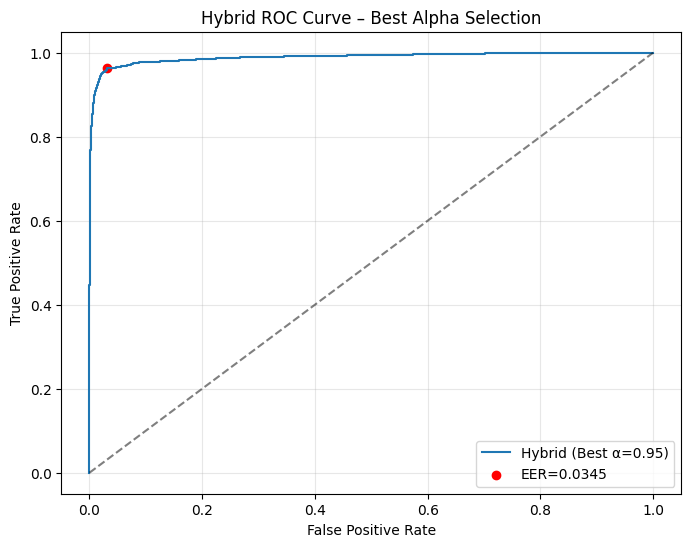

Results saved successfully at: D:\sp2-20240124T210502Z-001\sp2\BTP\TripleNet\ablation_results.json
[Loaded Model] Hybrid EER: 3.45% (thr=0.7588, α=0.95)

Final Hybrid Result: 3.45% ± 0.00% (across 1 runs)


In [51]:
import copy
import os
import json

MODEL_PATH = "best_model_imp_adaptiveTuned4.pth"    # where to save your best model
CONFIG_PATH = "model_config_imp_adaptiveTuned4.json"

def run_training(seed):
    print(f"\n===== Training with seed {seed} =====")
    set_seed(seed)

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    # --------------------------------------------------
    # If model already exists → load it and skip training
    # --------------------------------------------------
    if os.path.exists(MODEL_PATH):
        print("📌 Found saved model → Loading model instead of training...")
        num_classes = len(train_dataset_dw.indices_by_class)
        model = FingerprintTripleNet(feature_dim=256, num_classes=num_classes).to(device)
        model.load_state_dict(torch.load(MODEL_PATH, map_location=device))
        model.eval()

        eer, threshold, alpha, combined_score = compute_hybrid_eer_normalized(model, test_loader, device=device)

        title = f"lambda_hard=0"

        try:
            combined_score_serializable = combined_score.tolist()
        except Exception as e:
            print(f"Error converting combined_score to list: {e}")
            combined_score_serializable = None
        
        results_entry = {
            "EER_percent": float(eer),
            "threshold": float(threshold),
            "alpha": float(alpha),
            "combined_score": combined_score_serializable,
            "lambda_cls": float(lambda_cls),
            "lambda_semi": float(lambda_semi),
            "lambda_hard": float(lambda_hard),
            "margin_limit": float(margin_limit),
            "model_path": str(MODEL_PATH)
        }
        
        append_results(title, results_entry)
        print(f"[Loaded Model] Hybrid EER: {eer*100:.2f}% (thr={threshold:.4f}, α={alpha:.2f})")
        return eer * 100

    print("🚀 No saved model found → Training from scratch!")

    num_classes = len(train_dataset_dw.indices_by_class)
    model = FingerprintTripleNet(feature_dim=256, num_classes=num_classes).to(device)

    # --- compute pre-training distance stats (gap) using a fresh model ---
    try:
        stats = compute_distance_stats(model, train_dataset_dw, device=device, embed_batch_size=64, sample_limit=None)
    except Exception as e:
        print(f"[WARN] compute_distance_stats failed: {e}")
        stats = None

    if stats is None or "gap" not in stats or stats["gap"] <= 0.0:
        gap = 1e-4
        print("[WARN] Using fallback gap =", gap)
    else:
        gap = float(stats["gap"])
        print(f"[INFO] distance stats: {stats}")

    # Multipliers — sensible defaults (we keep these mutable for adaptation)
    hard_multiplier = 1
    semi_multiplier = 1

    # safety caps for multipliers to avoid runaway margins
    max_multiplier = 16.0
    adapt_factor = 1.5

    margin_hard = hard_multiplier * gap
    margin_semi = semi_multiplier * gap

    print(f"[INFO] initial margins -> hard: {margin_hard:.6e}, semi: {margin_semi:.6e}")

    optimizer = AdamW(model.parameters(), lr=1e-3, weight_decay=1e-5)

    # 🔥 Losses (enable logging in the loss objects if available)
    hard_criterion = HardTripletLoss(margin=margin_hard, log_stats=True)
    semi_criterion = SemiHardTripletLoss(margin=margin_semi, fallback_to_hard=False, log_stats=True)
    ce_criterion = nn.CrossEntropyLoss()

    # weights
    # lambda_hard=0.2
    # lambda_cls = 0.1    # classification weight (reduced to avoid CE domination)
    # lambda_semi = 1 # semi-hard weight
    # margin_limit = 0.5

    scaler = GradScaler("cuda")

    best_val_loss = float("inf")
    best_model_wts = copy.deepcopy(model.state_dict())
    patience = 5
    no_improve_count = 0

    # adaptive counter for consecutive epochs with no triplet signal
    no_triplet_signal_epochs = 0

    # -------------------------
    # Training loop (GLOBAL DW)
    # -------------------------
    for epoch in range(num_epochs):
        # --- recompute gap using current model before mining (costly but principled) ---
        model.eval()
        try:
            stats_epoch = compute_distance_stats(model, train_dataset_dw, device=device, embed_batch_size=64, sample_limit=None)
            print(stats_epoch)
        except Exception as e:
            print(f"[WARN] compute_distance_stats (epoch) failed: {e}")
            stats_epoch = None

        if stats_epoch is None or "gap" not in stats_epoch or stats_epoch["gap"] <= 0.0:
            # keep previous gap/margins if epoch stats invalid
            print(f"[EPOCH-{epoch+1}] could not recompute gap; keeping previous margins")
        else:
            gap = float(stats_epoch["gap"])
            # ensure minimal sensible multipliers to give semi-hard a chance
            hard_multiplier = max(hard_multiplier,1)
            semi_multiplier = max(semi_multiplier, 1)

            margin_hard = hard_multiplier * gap
            margin_semi = semi_multiplier * gap
            margin_hard = max(margin_hard, 1e-12)
            margin_semi = max(margin_semi, 1e-12)

            hard_criterion.margin = min(margin_hard,margin_limit)
            semi_criterion.margin = min(margin_semi,margin_limit)
            print(f"[EPOCH-{epoch+1}] recomputed gap: {gap:.6e}; margins -> hard: {hard_criterion.margin:.6e}, semi: {semi_criterion.margin:.6e}")

        # 1) Build global DW triplets for THIS epoch using current model (now using updated margins)
        triplet_loader = build_global_dw_triplet_loader(
            model,
            train_dataset_dw,
            device=device,
            embed_batch_size=64,
            triplet_batch_size=16,
            max_triplets_per_class=50,     # per class cap
            candidates_per_anchor=200,
            negatives_per_pair=4            # increase diversity
        )

        if triplet_loader is None:
            print("No triplets mined, skipping epoch.")
            continue

        # build_global_dw_triplet_loader already prints mined triplet count — no duplicate print here

        model.train()
        total_loss = 0.0
        valid_batches = 0

        # Accumulators for logging counts
        epoch_num_hard = 0
        epoch_num_semi = 0
        epoch_num_fallback = 0

        progress_bar = tqdm(
            triplet_loader,
            desc=f'Epoch {epoch+1} [GLOBAL-DW / Hard+Semi+CE]',
            leave=True
        )

        for batch in progress_bar:
            xa, ya, xp, yp, xn, yn = batch
            xa, xp, xn = xa.to(device), xp.to(device), xn.to(device)
            ya, yp, yn = ya.to(device), yp.to(device), yn.to(device)

            optimizer.zero_grad()
            with autocast("cuda"):
                # embeddings
                a_out = model.embed(xa)
                p_out = model.embed(xp)
                n_out = model.embed(xn)

                # triplet losses — robust to return types
                h_res = hard_criterion(a_out, p_out, n_out)
                if isinstance(h_res, tuple):
                    triplet_loss, num_hard = h_res
                else:
                    triplet_loss, num_hard = h_res, 0

                s_res = semi_criterion(a_out, p_out, n_out)
                if isinstance(s_res, tuple):
                    if len(s_res) == 3:
                        semi_loss, num_semi, num_fallback = s_res
                    else:
                        semi_loss, num_semi = s_res[0], s_res[1]
                        num_fallback = 0
                else:
                    semi_loss, num_semi, num_fallback = s_res, 0, 0

                # classification losses for all three
                logits_a = model.classifier(a_out)
                logits_p = model.classifier(p_out)
                logits_n = model.classifier(n_out)

                ce_loss = (
                    ce_criterion(logits_a, ya) +
                    ce_criterion(logits_p, yp) +
                    ce_criterion(logits_n, yn)
                ) / 3.0

                loss = lambda_hard*triplet_loss + lambda_semi * semi_loss + lambda_cls * ce_loss

            # backward / step with amp
            scaler.scale(loss).backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optimizer)
            scaler.update()

            # accumulate
            total_loss += loss.item()
            epoch_num_hard += int(num_hard)
            epoch_num_semi += int(num_semi)
            epoch_num_fallback += int(num_fallback)
            valid_batches += 1
            progress_bar.set_postfix({'Batch Loss': f'{loss.item():.4f}'})

        avg_train_loss = total_loss / max(valid_batches, 1)

        # -------------------------
        # Validation (unchanged)
        # -------------------------
        model.eval()
        val_loss = 0.0
        val_batches = 0

        all_pos = []
        all_neg = []

        with torch.no_grad():
            for batch in val_loader:
                if batch is None:
                    continue

                min1, dl1, min2, dl2, labels = batch
                dl1, dl2, labels = dl1.to(device), dl2.to(device), labels.to(device)

                emb1 = model.embed(dl1)
                emb2 = model.embed(dl2)

                dist = F.pairwise_distance(emb1, emb2)
                # batch_loss = (labels * dist + (1 - labels) * F.relu(1.0 - dist)).mean()
                all_pos.append(dist[labels == 1])
                all_neg.append(dist[labels == 0])

        # concatenate
        all_pos = torch.cat(all_pos)
        all_neg = torch.cat(all_neg)
        
        avg_val_loss = all_pos.mean() - all_neg.mean()


        # Epoch-level logging
        print(
            f"Epoch {epoch+1} [GLOBAL-DW / Hard+Semi+CE]: "
            f"Train Loss={avg_train_loss:.4f}, Val Loss={avg_val_loss:.4f}"
        )
        print(f"[LOG] semi-hard used: {epoch_num_semi}, fallback-hard: {epoch_num_fallback}, hard-negatives: {epoch_num_hard}")

        # -------------------------
        # ADAPTIVE multiplier if triplet signal vanished for a short run
        # -------------------------
        total_triplet_signal = epoch_num_semi + epoch_num_fallback + epoch_num_hard
        if total_triplet_signal == 0:
            no_triplet_signal_epochs += 1
        else:
            no_triplet_signal_epochs = 0

        # If no triplet signal for a couple of epochs, widen multipliers (but cap)
        if no_triplet_signal_epochs >= 1:
            old_hm, old_sm = hard_multiplier, semi_multiplier
            hard_multiplier = min(hard_multiplier * adapt_factor, max_multiplier)
            semi_multiplier = min(semi_multiplier * adapt_factor, max_multiplier)
            margin_hard = hard_multiplier * gap
            margin_semi = semi_multiplier * gap
            hard_criterion.margin = margin_hard
            semi_criterion.margin = margin_semi
            print(f"[ADAPT] triplet-signal empty for {no_triplet_signal_epochs} epoch(s) -> multipliers {old_hm:.2f}->{hard_multiplier:.2f}, {old_sm:.2f}->{semi_multiplier:.2f}")
            print(f"[ADAPT] new margins -> hard: {margin_hard:.6e}, semi: {margin_semi:.6e}")

        # -------------------------
        # Early Stopping Logic
        # -------------------------
        if avg_val_loss < best_val_loss - 1e-4:
            best_val_loss = avg_val_loss
            best_model_wts = copy.deepcopy(model.state_dict())
            no_improve_count = 0
            print(f"✅ New best model at epoch {epoch+1}")
        else:
            no_improve_count += 1
            print(f"⚠️ No improvement for {no_improve_count} epoch(s)")

        if no_improve_count >= patience:
            print(f"⏹ Early stopping triggered at epoch {epoch+1}")
            break

    # restore best
    model.load_state_dict(best_model_wts)

    # ============================
    #     SAVE THE MODEL
    # ============================
    torch.save(best_model_wts, MODEL_PATH)
    print(f"💾 Saved best model to {MODEL_PATH}")

    config = {
        "seed": seed,
        "epochs": num_epochs,
        "lambda_cls": lambda_cls,
        "lambda_semi": lambda_semi,
        "feature_dim": model.feature_dim
    }
    with open(CONFIG_PATH, "w") as f:
        json.dump(config, f, indent=4)
    print(f"📄 Saved config to {CONFIG_PATH}")

    # -------------------------
    # Final Evaluation
    # -------------------------
    
    eer, threshold, alpha, combined_score = compute_hybrid_eer_normalized(model, test_loader, device=device)
    print(f"Seed {seed} → Hybrid EER: {eer*100:.2f}% (Threshold: {threshold:.4f}, α={alpha:.2f})")

    title = f"lambda_cls=0"

    try:
        combined_score_serializable = combined_score.tolist()
    except Exception as e:
        print(f"Error converting combined_score to list: {e}")
        combined_score_serializable = None
    
    results_entry = {
        "EER_percent": float(eer),
        "threshold": float(threshold),
        "alpha": float(alpha),
        "combined_score": combined_score_serializable,
        "lambda_cls": float(lambda_cls),
        "lambda_semi": float(lambda_semi),
        "lambda_hard": float(lambda_hard),
        "margin_limit": float(margin_limit),
        "model_path": str(MODEL_PATH)
    }
    
    append_results(title, results_entry)

    return eer * 100



# =========================
# Run across multiple seeds
# =========================
seeds = [42]
num_epochs = 50

all_eers = []
for s in seeds:
    eer = run_training(s)
    all_eers.append(eer)

mean_eer = np.mean(all_eers)
std_eer = np.std(all_eers)
print(f"\nFinal Hybrid Result: {mean_eer:.2f}% ± {std_eer:.2f}% (across {len(seeds)} runs)")



===== Training with seed 42 =====
🚀 No saved model found → Training from scratch!
[INFO] distance stats: {'median_d_ap': 1.9073486612342094e-07, 'median_d_an': 3.576278970740532e-07, 'gap': 1.6689303095063224e-07, 'p10_ap': 7.152557657263969e-08, 'p90_an': 4.7683712978141557e-07}
[INFO] initial margins -> hard: 1.668930e-07, semi: 1.668930e-07
{'median_d_ap': 1.9073486612342094e-07, 'median_d_an': 3.576278970740532e-07, 'gap': 1.6689303095063224e-07, 'p10_ap': 7.152557657263969e-08, 'p90_an': 4.7683712978141557e-07}
[EPOCH-1] recomputed gap: 1.668930e-07; margins -> hard: 1.668930e-07, semi: 1.668930e-07
[DW] Mined 11750 triplets for this epoch.


Epoch 1 [GLOBAL-DW / Hard+Semi+CE]: 100%|█████████████████████████| 735/735 [00:42<00:00, 17.21it/s, Batch Loss=1.8050]
C:\Users\divya\AppData\Local\Temp\ipykernel_3792\477085210.py:83: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.tensor(dl1, dtype=torch.float32),
C:\Users\divya\AppData\Local\Temp\ipykernel_3792\477085210.py:85: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.tensor(dl2, dtype=torch.float32),
C:\Users\divya\AppData\Local\Temp\ipykernel_3792\1251142332.py:8: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  dl1_tens

Epoch 1 [GLOBAL-DW / Hard+Semi+CE]: Train Loss=1.9867, Val Loss=-0.6517
[LOG] semi-hard used: 0, fallback-hard: 0, hard-negatives: 356
✅ New best model at epoch 1
{'median_d_ap': 0.06254102289676666, 'median_d_an': 1.5606812834739685, 'gap': 1.4981402605772018, 'p10_ap': 0.02937205005437136, 'p90_an': 1.8790385365486146}
[EPOCH-2] recomputed gap: 1.498140e+00; margins -> hard: 5.991650e-01, semi: 5.991650e-01
[DW] Mined 11750 triplets for this epoch.


Epoch 2 [GLOBAL-DW / Hard+Semi+CE]: 100%|█████████████████████████| 735/735 [00:43<00:00, 17.02it/s, Batch Loss=1.4070]


Epoch 2 [GLOBAL-DW / Hard+Semi+CE]: Train Loss=1.5013, Val Loss=-0.6860
[LOG] semi-hard used: 3457, fallback-hard: 0, hard-negatives: 29
✅ New best model at epoch 2
{'median_d_ap': 0.04372750408947468, 'median_d_an': 1.7968554496765137, 'gap': 1.753127945587039, 'p10_ap': 0.02384481467306614, 'p90_an': 2.0217278003692627}
[EPOCH-3] recomputed gap: 1.753128e+00; margins -> hard: 5.991650e-01, semi: 5.991650e-01
[DW] Mined 11750 triplets for this epoch.


Epoch 3 [GLOBAL-DW / Hard+Semi+CE]: 100%|█████████████████████████| 735/735 [00:43<00:00, 16.90it/s, Batch Loss=1.1127]


... (9 outputs left out)

Epoch 8 [GLOBAL-DW / Hard+Semi+CE]: 100%|█████████████████████████| 735/735 [00:42<00:00, 17.24it/s, Batch Loss=0.4248]


Epoch 8 [GLOBAL-DW / Hard+Semi+CE]: Train Loss=0.3664, Val Loss=-0.6256
[LOG] semi-hard used: 194, fallback-hard: 0, hard-negatives: 0
⚠️ No improvement for 5 epoch(s)
⏹ Early stopping triggered at epoch 8
💾 Saved best model to best_model_imp_adaptiveTuned6.pth
📄 Saved config to model_config_imp_adaptiveTuned6.json
Computing scores (one-time extraction)...


Eval: 100%|██████████████████████████████████████████████████████████████████████| 20757/20757 [14:39<00:00, 23.61it/s]



=== RAW SCORE STATS ===
DL Scores   : min=-0.6309, max=0.9843
Min Scores  : min=0.0182, max=74.3008

Sample Raw DL Scores: [0.9589249  0.9843188  0.9481533  0.9490466  0.97055584 0.95534533
 0.89746666 0.9322669  0.95848453 0.9541302 ]
Sample Raw Min Scores: [67.6110708  60.78575513 61.99341913 61.64579039 21.94901646 69.26823177
 54.68776533 64.00021547 21.82214948 56.37847252]

=== NORMALIZED SCORES ===
Sample DL_norm: [0.97946244 0.99215937 0.9740766  0.9745233  0.9852779  0.9776727
 0.9487333  0.9661335  0.97924227 0.9770651 ]
Sample Min_norm: [0.67611071 0.60785755 0.61993419 0.6164579  0.21949016 0.69268232
 0.54687765 0.64000215 0.21822149 0.56378473]

Alpha = 0.00
EER   = 0.1284
Threshold  = 0.1867

Alpha = 0.01
EER   = 0.1264
Threshold  = 0.1919

Alpha = 0.02
EER   = 0.1263
Threshold  = 0.1961

Alpha = 0.03
EER   = 0.1254
Threshold  = 0.2013

Alpha = 0.04
EER   = 0.1239
Threshold  = 0.2062

Alpha = 0.05
EER   = 0.1225
Threshold  = 0.2114

Alpha = 0.06
EER   = 0.1216
Threshold

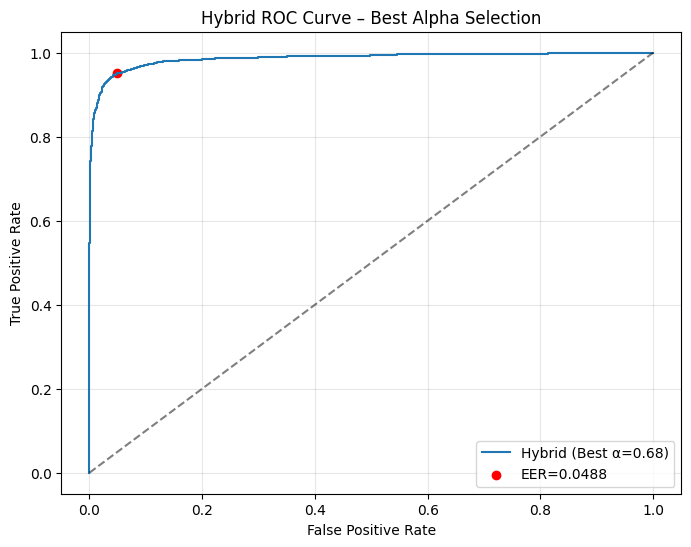

Seed 42 → Hybrid EER: 4.88% (Threshold: 0.5922, α=0.68)
Results saved successfully at: D:\sp2-20240124T210502Z-001\sp2\BTP\TripleNet\ablation_results.json

Final Hybrid Result: 4.88% ± 0.00% (across 1 runs)


In [55]:
import copy
import os
import json

MODEL_PATH = "best_model_imp_adaptiveTuned6.pth"    # where to save your best model
CONFIG_PATH = "model_config_imp_adaptiveTuned6.json"

def run_training(seed):
    print(f"\n===== Training with seed {seed} =====")
    set_seed(seed)

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    # --------------------------------------------------
    # If model already exists → load it and skip training
    # --------------------------------------------------
    if os.path.exists(MODEL_PATH):
        print("📌 Found saved model → Loading model instead of training...")
        num_classes = len(train_dataset_dw.indices_by_class)
        model = FingerprintTripleNet(feature_dim=256, num_classes=num_classes).to(device)
        model.load_state_dict(torch.load(MODEL_PATH, map_location=device))
        model.eval()

        eer, threshold, alpha, combined_score = compute_hybrid_eer_normalized(model, test_loader, device=device)

        title = f"lambda_semi=0"

        try:
            combined_score_serializable = combined_score.tolist()
        except Exception as e:
            print(f"Error converting combined_score to list: {e}")
            combined_score_serializable = None
        
        results_entry = {
            "EER_percent": float(eer),
            "threshold": float(threshold),
            "alpha": float(alpha),
            "combined_score": combined_score_serializable,
            "lambda_cls": float(lambda_cls),
            "lambda_semi": float(lambda_semi),
            "lambda_hard": float(lambda_hard),
            "margin_limit": float(margin_limit),
            "model_path": str(MODEL_PATH)
        }
        
        append_results(title, results_entry)
        print(f"[Loaded Model] Hybrid EER: {eer*100:.2f}% (thr={threshold:.4f}, α={alpha:.2f})")
        return eer * 100

    print("🚀 No saved model found → Training from scratch!")

    num_classes = len(train_dataset_dw.indices_by_class)
    model = FingerprintTripleNet(feature_dim=256, num_classes=num_classes).to(device)

    # --- compute pre-training distance stats (gap) using a fresh model ---
    try:
        stats = compute_distance_stats(model, train_dataset_dw, device=device, embed_batch_size=64, sample_limit=None)
    except Exception as e:
        print(f"[WARN] compute_distance_stats failed: {e}")
        stats = None

    if stats is None or "gap" not in stats or stats["gap"] <= 0.0:
        gap = 1e-4
        print("[WARN] Using fallback gap =", gap)
    else:
        gap = float(stats["gap"])
        print(f"[INFO] distance stats: {stats}")

    # Multipliers — sensible defaults (we keep these mutable for adaptation)
    hard_multiplier = 1
    semi_multiplier = 1

    # safety caps for multipliers to avoid runaway margins
    max_multiplier = 16.0
    adapt_factor = 1.5

    margin_hard = hard_multiplier * gap
    margin_semi = semi_multiplier * gap

    print(f"[INFO] initial margins -> hard: {margin_hard:.6e}, semi: {margin_semi:.6e}")

    optimizer = AdamW(model.parameters(), lr=1e-3, weight_decay=1e-5)

    # 🔥 Losses (enable logging in the loss objects if available)
    hard_criterion = HardTripletLoss(margin=margin_hard, log_stats=True)
    semi_criterion = SemiHardTripletLoss(margin=margin_semi, fallback_to_hard=False, log_stats=True)
    ce_criterion = nn.CrossEntropyLoss()

    # weights
    # lambda_hard=0.2
    # lambda_cls = 0.1    # classification weight (reduced to avoid CE domination)
    # lambda_semi = 1 # semi-hard weight
    # margin_limit = 0.5

    scaler = GradScaler("cuda")

    best_val_loss = float("inf")
    best_model_wts = copy.deepcopy(model.state_dict())
    patience = 5
    no_improve_count = 0

    # adaptive counter for consecutive epochs with no triplet signal
    no_triplet_signal_epochs = 0

    # -------------------------
    # Training loop (GLOBAL DW)
    # -------------------------
    for epoch in range(num_epochs):
        # --- recompute gap using current model before mining (costly but principled) ---
        model.eval()
        try:
            stats_epoch = compute_distance_stats(model, train_dataset_dw, device=device, embed_batch_size=64, sample_limit=None)
            print(stats_epoch)
        except Exception as e:
            print(f"[WARN] compute_distance_stats (epoch) failed: {e}")
            stats_epoch = None

        if stats_epoch is None or "gap" not in stats_epoch or stats_epoch["gap"] <= 0.0:
            # keep previous gap/margins if epoch stats invalid
            print(f"[EPOCH-{epoch+1}] could not recompute gap; keeping previous margins")
        else:
            gap = float(stats_epoch["gap"])
            # ensure minimal sensible multipliers to give semi-hard a chance
            hard_multiplier = max(hard_multiplier,1)
            semi_multiplier = max(semi_multiplier, 1)

            margin_hard = hard_multiplier * gap
            margin_semi = semi_multiplier * gap
            margin_hard = max(margin_hard, 1e-12)
            margin_semi = max(margin_semi, 1e-12)

            hard_criterion.margin = min(margin_hard,margin_limit)
            semi_criterion.margin = min(margin_semi,margin_limit)
            print(f"[EPOCH-{epoch+1}] recomputed gap: {gap:.6e}; margins -> hard: {hard_criterion.margin:.6e}, semi: {semi_criterion.margin:.6e}")

        # 1) Build global DW triplets for THIS epoch using current model (now using updated margins)
        triplet_loader = build_global_dw_triplet_loader(
            model,
            train_dataset_dw,
            device=device,
            embed_batch_size=64,
            triplet_batch_size=16,
            max_triplets_per_class=50,     # per class cap
            candidates_per_anchor=200,
            negatives_per_pair=4            # increase diversity
        )

        if triplet_loader is None:
            print("No triplets mined, skipping epoch.")
            continue

        # build_global_dw_triplet_loader already prints mined triplet count — no duplicate print here

        model.train()
        total_loss = 0.0
        valid_batches = 0

        # Accumulators for logging counts
        epoch_num_hard = 0
        epoch_num_semi = 0
        epoch_num_fallback = 0

        progress_bar = tqdm(
            triplet_loader,
            desc=f'Epoch {epoch+1} [GLOBAL-DW / Hard+Semi+CE]',
            leave=True
        )

        for batch in progress_bar:
            xa, ya, xp, yp, xn, yn = batch
            xa, xp, xn = xa.to(device), xp.to(device), xn.to(device)
            ya, yp, yn = ya.to(device), yp.to(device), yn.to(device)

            optimizer.zero_grad()
            with autocast("cuda"):
                # embeddings
                a_out = model.embed(xa)
                p_out = model.embed(xp)
                n_out = model.embed(xn)

                # triplet losses — robust to return types
                h_res = hard_criterion(a_out, p_out, n_out)
                if isinstance(h_res, tuple):
                    triplet_loss, num_hard = h_res
                else:
                    triplet_loss, num_hard = h_res, 0

                s_res = semi_criterion(a_out, p_out, n_out)
                if isinstance(s_res, tuple):
                    if len(s_res) == 3:
                        semi_loss, num_semi, num_fallback = s_res
                    else:
                        semi_loss, num_semi = s_res[0], s_res[1]
                        num_fallback = 0
                else:
                    semi_loss, num_semi, num_fallback = s_res, 0, 0

                # classification losses for all three
                logits_a = model.classifier(a_out)
                logits_p = model.classifier(p_out)
                logits_n = model.classifier(n_out)

                ce_loss = (
                    ce_criterion(logits_a, ya) +
                    ce_criterion(logits_p, yp) +
                    ce_criterion(logits_n, yn)
                ) / 3.0

                loss = lambda_hard*triplet_loss + lambda_semi * semi_loss + lambda_cls * ce_loss

            # backward / step with amp
            scaler.scale(loss).backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optimizer)
            scaler.update()

            # accumulate
            total_loss += loss.item()
            epoch_num_hard += int(num_hard)
            epoch_num_semi += int(num_semi)
            epoch_num_fallback += int(num_fallback)
            valid_batches += 1
            progress_bar.set_postfix({'Batch Loss': f'{loss.item():.4f}'})

        avg_train_loss = total_loss / max(valid_batches, 1)

        # -------------------------
        # Validation (unchanged)
        # -------------------------
        model.eval()
        val_loss = 0.0
        val_batches = 0

        all_pos = []
        all_neg = []

        with torch.no_grad():
            for batch in val_loader:
                if batch is None:
                    continue

                min1, dl1, min2, dl2, labels = batch
                dl1, dl2, labels = dl1.to(device), dl2.to(device), labels.to(device)

                emb1 = model.embed(dl1)
                emb2 = model.embed(dl2)

                dist = F.pairwise_distance(emb1, emb2)
                # batch_loss = (labels * dist + (1 - labels) * F.relu(1.0 - dist)).mean()
                all_pos.append(dist[labels == 1])
                all_neg.append(dist[labels == 0])

        # concatenate
        all_pos = torch.cat(all_pos)
        all_neg = torch.cat(all_neg)
        
        avg_val_loss = all_pos.mean() - all_neg.mean()


        # Epoch-level logging
        print(
            f"Epoch {epoch+1} [GLOBAL-DW / Hard+Semi+CE]: "
            f"Train Loss={avg_train_loss:.4f}, Val Loss={avg_val_loss:.4f}"
        )
        print(f"[LOG] semi-hard used: {epoch_num_semi}, fallback-hard: {epoch_num_fallback}, hard-negatives: {epoch_num_hard}")

        # -------------------------
        # ADAPTIVE multiplier if triplet signal vanished for a short run
        # -------------------------
        total_triplet_signal = epoch_num_semi + epoch_num_fallback + epoch_num_hard
        if total_triplet_signal == 0:
            no_triplet_signal_epochs += 1
        else:
            no_triplet_signal_epochs = 0

        # If no triplet signal for a couple of epochs, widen multipliers (but cap)
        if no_triplet_signal_epochs >= 1:
            old_hm, old_sm = hard_multiplier, semi_multiplier
            hard_multiplier = min(hard_multiplier * adapt_factor, max_multiplier)
            semi_multiplier = min(semi_multiplier * adapt_factor, max_multiplier)
            margin_hard = hard_multiplier * gap
            margin_semi = semi_multiplier * gap
            hard_criterion.margin = margin_hard
            semi_criterion.margin = margin_semi
            print(f"[ADAPT] triplet-signal empty for {no_triplet_signal_epochs} epoch(s) -> multipliers {old_hm:.2f}->{hard_multiplier:.2f}, {old_sm:.2f}->{semi_multiplier:.2f}")
            print(f"[ADAPT] new margins -> hard: {margin_hard:.6e}, semi: {margin_semi:.6e}")

        # -------------------------
        # Early Stopping Logic
        # -------------------------
        if avg_val_loss < best_val_loss - 1e-4:
            best_val_loss = avg_val_loss
            best_model_wts = copy.deepcopy(model.state_dict())
            no_improve_count = 0
            print(f"✅ New best model at epoch {epoch+1}")
        else:
            no_improve_count += 1
            print(f"⚠️ No improvement for {no_improve_count} epoch(s)")

        if no_improve_count >= patience:
            print(f"⏹ Early stopping triggered at epoch {epoch+1}")
            break

    # restore best
    model.load_state_dict(best_model_wts)

    # ============================
    #     SAVE THE MODEL
    # ============================
    torch.save(best_model_wts, MODEL_PATH)
    print(f"💾 Saved best model to {MODEL_PATH}")

    config = {
        "seed": seed,
        "epochs": num_epochs,
        "lambda_cls": lambda_cls,
        "lambda_semi": lambda_semi,
        "feature_dim": model.feature_dim
    }
    with open(CONFIG_PATH, "w") as f:
        json.dump(config, f, indent=4)
    print(f"📄 Saved config to {CONFIG_PATH}")

    # -------------------------
    # Final Evaluation
    # -------------------------
    
    eer, threshold, alpha, combined_score = compute_hybrid_eer_normalized(model, test_loader, device=device)
    print(f"Seed {seed} → Hybrid EER: {eer*100:.2f}% (Threshold: {threshold:.4f}, α={alpha:.2f})")

    title = f"lambda_cls=0"

    try:
        combined_score_serializable = combined_score.tolist()
    except Exception as e:
        print(f"Error converting combined_score to list: {e}")
        combined_score_serializable = None
    
    results_entry = {
        "EER_percent": float(eer),
        "threshold": float(threshold),
        "alpha": float(alpha),
        "combined_score": combined_score_serializable,
        "lambda_cls": float(lambda_cls),
        "lambda_semi": float(lambda_semi),
        "lambda_hard": float(lambda_hard),
        "margin_limit": float(margin_limit),
        "model_path": str(MODEL_PATH)
    }
    
    append_results(title, results_entry)

    return eer * 100



# =========================
# Run across multiple seeds
# =========================
seeds = [42]
num_epochs = 50

all_eers = []
for s in seeds:
    eer = run_training(s)
    all_eers.append(eer)

mean_eer = np.mean(all_eers)
std_eer = np.std(all_eers)
print(f"\nFinal Hybrid Result: {mean_eer:.2f}% ± {std_eer:.2f}% (across {len(seeds)} runs)")


In [32]:
import copy
import os
import json

MODEL_PATH = "best_model_imp_adaptiveTuned7.pth"    # where to save your best model
CONFIG_PATH = "model_config_imp_adaptiveTuned7.json"

def run_training(seed):
    print(f"\n===== Training with seed {seed} =====")
    set_seed(seed)

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    # --------------------------------------------------
    # If model already exists → load it and skip training
    # --------------------------------------------------
    if os.path.exists(MODEL_PATH):
        print("📌 Found saved model → Loading model instead of training...")
        num_classes = len(train_dataset_dw.indices_by_class)
        model = FingerprintTripleNet(feature_dim=256, num_classes=num_classes).to(device)
        model.load_state_dict(torch.load(MODEL_PATH, map_location=device))
        model.eval()

        eer, threshold, alpha, combined_score = compute_hybrid_eer_normalized(model, test_loader, device=device)

        title = f"lambda_hard=0"

        try:
            combined_score_serializable = combined_score.tolist()
        except Exception as e:
            print(f"Error converting combined_score to list: {e}")
            combined_score_serializable = None
        
        results_entry = {
            "EER_percent": float(eer),
            "threshold": float(threshold),
            "alpha": float(alpha),
            "combined_score": combined_score_serializable,
            "lambda_cls": float(lambda_cls),
            "lambda_semi": float(lambda_semi),
            "lambda_hard": float(lambda_hard),
            "margin_limit": float(margin_limit),
            "model_path": str(MODEL_PATH)
        }
        
        append_results(title, results_entry)
        print(f"[Loaded Model] Hybrid EER: {eer*100:.2f}% (thr={threshold:.4f}, α={alpha:.2f})")
        return eer * 100

    print("🚀 No saved model found → Training from scratch!")

    num_classes = len(train_dataset_dw.indices_by_class)
    model = FingerprintTripleNet(feature_dim=256, num_classes=num_classes).to(device)

    # --- compute pre-training distance stats (gap) using a fresh model ---
    try:
        stats = compute_distance_stats(model, train_dataset_dw, device=device, embed_batch_size=64, sample_limit=None)
    except Exception as e:
        print(f"[WARN] compute_distance_stats failed: {e}")
        stats = None

    if stats is None or "gap" not in stats or stats["gap"] <= 0.0:
        gap = 1e-4
        print("[WARN] Using fallback gap =", gap)
    else:
        gap = float(stats["gap"])
        print(f"[INFO] distance stats: {stats}")

    # Multipliers — sensible defaults (we keep these mutable for adaptation)
    hard_multiplier = 1
    semi_multiplier = 1

    # safety caps for multipliers to avoid runaway margins
    max_multiplier = 16.0
    adapt_factor = 1.5

    margin_hard = hard_multiplier * gap
    margin_semi = semi_multiplier * gap

    print(f"[INFO] initial margins -> hard: {margin_hard:.6e}, semi: {margin_semi:.6e}")

    optimizer = AdamW(model.parameters(), lr=1e-3, weight_decay=1e-5)

    # 🔥 Losses (enable logging in the loss objects if available)
    hard_criterion = HardTripletLoss(margin=margin_hard, log_stats=True)
    semi_criterion = SemiHardTripletLoss(margin=margin_semi, fallback_to_hard=False, log_stats=True)
    ce_criterion = nn.CrossEntropyLoss()

    # weights
    # lambda_hard=0.2
    # lambda_cls = 0.1    # classification weight (reduced to avoid CE domination)
    # lambda_semi = 1 # semi-hard weight
    # margin_limit = 0.5

    scaler = GradScaler("cuda")

    best_val_loss = float("inf")
    best_model_wts = copy.deepcopy(model.state_dict())
    patience = 5
    no_improve_count = 0

    # adaptive counter for consecutive epochs with no triplet signal
    no_triplet_signal_epochs = 0

    # -------------------------
    # Training loop (GLOBAL DW)
    # -------------------------
    for epoch in range(num_epochs):
        # --- recompute gap using current model before mining (costly but principled) ---
        model.eval()
        try:
            stats_epoch = compute_distance_stats(model, train_dataset_dw, device=device, embed_batch_size=64, sample_limit=None)
            print(stats_epoch)
        except Exception as e:
            print(f"[WARN] compute_distance_stats (epoch) failed: {e}")
            stats_epoch = None

        if stats_epoch is None or "gap" not in stats_epoch or stats_epoch["gap"] <= 0.0:
            # keep previous gap/margins if epoch stats invalid
            print(f"[EPOCH-{epoch+1}] could not recompute gap; keeping previous margins")
        else:
            gap = float(stats_epoch["gap"])
            # ensure minimal sensible multipliers to give semi-hard a chance
            hard_multiplier = max(hard_multiplier,1)
            semi_multiplier = max(semi_multiplier, 1)

            margin_hard = hard_multiplier * gap
            margin_semi = semi_multiplier * gap
            margin_hard = max(margin_hard, 1e-12)
            margin_semi = max(margin_semi, 1e-12)

            hard_criterion.margin = min(margin_hard,margin_limit)
            semi_criterion.margin = min(margin_semi,margin_limit)
            print(f"[EPOCH-{epoch+1}] recomputed gap: {gap:.6e}; margins -> hard: {hard_criterion.margin:.6e}, semi: {semi_criterion.margin:.6e}")

        # 1) Build global DW triplets for THIS epoch using current model (now using updated margins)
        triplet_loader = build_global_dw_triplet_loader(
            model,
            train_dataset_dw,
            device=device,
            embed_batch_size=64,
            triplet_batch_size=16,
            max_triplets_per_class=50,     # per class cap
            candidates_per_anchor=200,
            negatives_per_pair=4            # increase diversity
        )

        if triplet_loader is None:
            print("No triplets mined, skipping epoch.")
            continue

        # build_global_dw_triplet_loader already prints mined triplet count — no duplicate print here

        model.train()
        total_loss = 0.0
        valid_batches = 0

        # Accumulators for logging counts
        epoch_num_hard = 0
        epoch_num_semi = 0
        epoch_num_fallback = 0

        progress_bar = tqdm(
            triplet_loader,
            desc=f'Epoch {epoch+1} [GLOBAL-DW / Hard+Semi+CE]',
            leave=True
        )

        for batch in progress_bar:
            xa, ya, xp, yp, xn, yn = batch
            xa, xp, xn = xa.to(device), xp.to(device), xn.to(device)
            ya, yp, yn = ya.to(device), yp.to(device), yn.to(device)

            optimizer.zero_grad()
            with autocast("cuda"):
                # embeddings
                a_out = model.embed(xa)
                p_out = model.embed(xp)
                n_out = model.embed(xn)

                # triplet losses — robust to return types
                h_res = hard_criterion(a_out, p_out, n_out)
                if isinstance(h_res, tuple):
                    triplet_loss, num_hard = h_res
                else:
                    triplet_loss, num_hard = h_res, 0

                s_res = semi_criterion(a_out, p_out, n_out)
                if isinstance(s_res, tuple):
                    if len(s_res) == 3:
                        semi_loss, num_semi, num_fallback = s_res
                    else:
                        semi_loss, num_semi = s_res[0], s_res[1]
                        num_fallback = 0
                else:
                    semi_loss, num_semi, num_fallback = s_res, 0, 0

                # classification losses for all three
                logits_a = model.classifier(a_out)
                logits_p = model.classifier(p_out)
                logits_n = model.classifier(n_out)

                ce_loss = (
                    ce_criterion(logits_a, ya) +
                    ce_criterion(logits_p, yp) +
                    ce_criterion(logits_n, yn)
                ) / 3.0

                loss = lambda_hard*triplet_loss + lambda_semi * semi_loss + lambda_cls * ce_loss

            # backward / step with amp
            scaler.scale(loss).backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optimizer)
            scaler.update()

            # accumulate
            total_loss += loss.item()
            epoch_num_hard += int(num_hard)
            epoch_num_semi += int(num_semi)
            epoch_num_fallback += int(num_fallback)
            valid_batches += 1
            progress_bar.set_postfix({'Batch Loss': f'{loss.item():.4f}'})

        avg_train_loss = total_loss / max(valid_batches, 1)

        # -------------------------
        # Validation (unchanged)
        # -------------------------
        model.eval()
        val_loss = 0.0
        val_batches = 0

        all_pos = []
        all_neg = []

        with torch.no_grad():
            for batch in val_loader:
                if batch is None:
                    continue

                min1, dl1, min2, dl2, labels = batch
                dl1, dl2, labels = dl1.to(device), dl2.to(device), labels.to(device)

                emb1 = model.embed(dl1)
                emb2 = model.embed(dl2)

                dist = F.pairwise_distance(emb1, emb2)
                # batch_loss = (labels * dist + (1 - labels) * F.relu(1.0 - dist)).mean()
                all_pos.append(dist[labels == 1])
                all_neg.append(dist[labels == 0])

        # concatenate
        all_pos = torch.cat(all_pos)
        all_neg = torch.cat(all_neg)
        
        avg_val_loss = all_pos.mean() - all_neg.mean()


        # Epoch-level logging
        print(
            f"Epoch {epoch+1} [GLOBAL-DW / Hard+Semi+CE]: "
            f"Train Loss={avg_train_loss:.4f}, Val Loss={avg_val_loss:.4f}"
        )
        print(f"[LOG] semi-hard used: {epoch_num_semi}, fallback-hard: {epoch_num_fallback}, hard-negatives: {epoch_num_hard}")

        # -------------------------
        # ADAPTIVE multiplier if triplet signal vanished for a short run
        # -------------------------
        total_triplet_signal = epoch_num_semi + epoch_num_fallback + epoch_num_hard
        if total_triplet_signal == 0:
            no_triplet_signal_epochs += 1
        else:
            no_triplet_signal_epochs = 0

        # If no triplet signal for a couple of epochs, widen multipliers (but cap)
        if no_triplet_signal_epochs >= 1:
            old_hm, old_sm = hard_multiplier, semi_multiplier
            hard_multiplier = min(hard_multiplier * adapt_factor, max_multiplier)
            semi_multiplier = min(semi_multiplier * adapt_factor, max_multiplier)
            margin_hard = hard_multiplier * gap
            margin_semi = semi_multiplier * gap
            hard_criterion.margin = margin_hard
            semi_criterion.margin = margin_semi
            print(f"[ADAPT] triplet-signal empty for {no_triplet_signal_epochs} epoch(s) -> multipliers {old_hm:.2f}->{hard_multiplier:.2f}, {old_sm:.2f}->{semi_multiplier:.2f}")
            print(f"[ADAPT] new margins -> hard: {margin_hard:.6e}, semi: {margin_semi:.6e}")

        # -------------------------
        # Early Stopping Logic
        # -------------------------
        if avg_val_loss < best_val_loss - 1e-4:
            best_val_loss = avg_val_loss
            best_model_wts = copy.deepcopy(model.state_dict())
            no_improve_count = 0
            print(f"✅ New best model at epoch {epoch+1}")
        else:
            no_improve_count += 1
            print(f"⚠️ No improvement for {no_improve_count} epoch(s)")

        if no_improve_count >= patience:
            print(f"⏹ Early stopping triggered at epoch {epoch+1}")
            break

    # restore best
    model.load_state_dict(best_model_wts)

    # ============================
    #     SAVE THE MODEL
    # ============================
    torch.save(best_model_wts, MODEL_PATH)
    print(f"💾 Saved best model to {MODEL_PATH}")

    config = {
        "seed": seed,
        "epochs": num_epochs,
        "lambda_cls": lambda_cls,
        "lambda_semi": lambda_semi,
        "feature_dim": model.feature_dim
    }
    with open(CONFIG_PATH, "w") as f:
        json.dump(config, f, indent=4)
    print(f"📄 Saved config to {CONFIG_PATH}")

    # -------------------------
    # Final Evaluation
    # -------------------------
    
    eer, threshold, alpha, combined_score = compute_hybrid_eer_normalized(model, test_loader, device=device)
    print(f"Seed {seed} → Hybrid EER: {eer*100:.2f}% (Threshold: {threshold:.4f}, α={alpha:.2f})")

    title = f"lambda_hard=0"

    try:
        combined_score_serializable = combined_score.tolist()
    except Exception as e:
        print(f"Error converting combined_score to list: {e}")
        combined_score_serializable = None
    
    results_entry = {
        "EER_percent": float(eer),
        "threshold": float(threshold),
        "alpha": float(alpha),
        "combined_score": combined_score_serializable,
        "lambda_cls": float(lambda_cls),
        "lambda_semi": float(lambda_semi),
        "lambda_hard": float(lambda_hard),
        "margin_limit": float(margin_limit),
        "model_path": str(MODEL_PATH)
    }
    
    append_results(title, results_entry)

    return eer * 100



# =========================
# Run across multiple seeds
# =========================
seeds = [42]
num_epochs = 50

all_eers = []
for s in seeds:
    eer = run_training(s)
    all_eers.append(eer)

mean_eer = np.mean(all_eers)
std_eer = np.std(all_eers)
print(f"\nFinal Hybrid Result: {mean_eer:.2f}% ± {std_eer:.2f}% (across {len(seeds)} runs)")



===== Training with seed 42 =====
📌 Found saved model → Loading model instead of training...
Computing scores (one-time extraction)...


Eval:   0%|                                                                                  | 0/20757 [00:00<?, ?it/s]C:\Users\divya\AppData\Local\Temp\ipykernel_7352\477085210.py:83: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.tensor(dl1, dtype=torch.float32),
C:\Users\divya\AppData\Local\Temp\ipykernel_7352\477085210.py:85: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.tensor(dl2, dtype=torch.float32),
C:\Users\divya\AppData\Local\Temp\ipykernel_7352\1251142332.py:8: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  dl1_tenso

KeyboardInterrupt: 


===== Training with seed 42 =====
📌 Found saved model → Loading model instead of training...
Computing scores (one-time extraction)...


Eval:   0%|                                                                                  | 0/20757 [00:00<?, ?it/s]C:\Users\divya\AppData\Local\Temp\ipykernel_16072\477085210.py:83: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.tensor(dl1, dtype=torch.float32),
C:\Users\divya\AppData\Local\Temp\ipykernel_16072\477085210.py:85: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.tensor(dl2, dtype=torch.float32),
C:\Users\divya\AppData\Local\Temp\ipykernel_16072\1251142332.py:8: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  dl1_te


=== RAW SCORE STATS ===
DL Scores   : min=-0.9093, max=0.9984
Min Scores  : min=0.0182, max=74.3008

Sample Raw DL Scores: [0.80526626 0.9530833  0.80443305 0.8164334  0.68286157 0.87140954
 0.9647776  0.88849515 0.88448894 0.84562755]
Sample Raw Min Scores: [67.6110708  60.78575513 61.99341913 61.64579039 21.94901646 69.26823177
 54.68776533 64.00021547 21.82214948 56.37847252]

=== NORMALIZED SCORES ===
Sample DL_norm: [0.90263313 0.97654164 0.90221655 0.9082167  0.8414308  0.93570477
 0.9823888  0.9442476  0.94224447 0.9228138 ]
Sample Min_norm: [0.67611071 0.60785755 0.61993419 0.6164579  0.21949016 0.69268232
 0.54687765 0.64000215 0.21822149 0.56378473]

Alpha = 0.00
EER   = 0.1284
Threshold  = 0.1867

Alpha = 0.01
EER   = 0.1245
Threshold  = 0.1920

Alpha = 0.02
EER   = 0.1263
Threshold  = 0.1942

Alpha = 0.03
EER   = 0.1218
Threshold  = 0.2012

Alpha = 0.04
EER   = 0.1238
Threshold  = 0.2034

Alpha = 0.05
EER   = 0.1197
Threshold  = 0.2097

Alpha = 0.06
EER   = 0.1164
Threshol

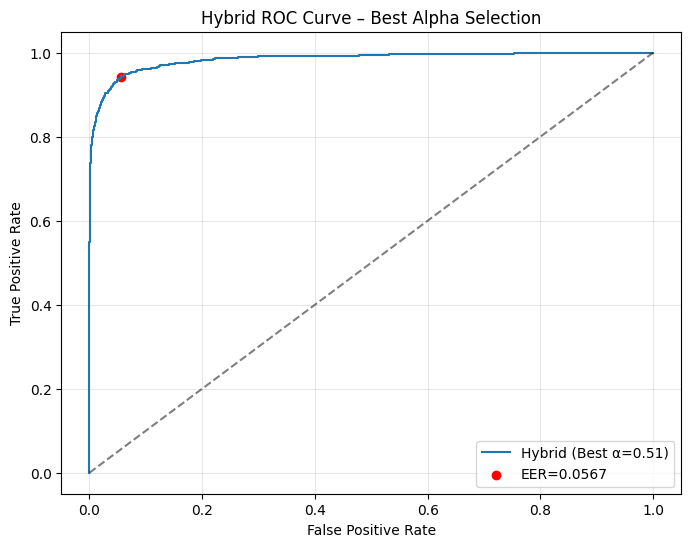

Results saved successfully at: D:\sp2-20240124T210502Z-001\sp2\BTP\TripleNet\ablation_results.json
[Loaded Model] Hybrid EER: 5.67% (thr=0.4984, α=0.51)

Final Hybrid Result: 5.67% ± 0.00% (across 1 runs)


In [45]:
import copy
import os
import json

MODEL_PATH = "best_model_imp_polyuFixed.pth"    # where to save your best model
CONFIG_PATH = "model_config_imp_polyuFixed.json"

def run_training(seed):
    print(f"\n===== Training with seed {seed} =====")
    set_seed(seed)

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    # --------------------------------------------------
    # If model already exists → load it and skip training
    # --------------------------------------------------
    if os.path.exists(MODEL_PATH):
        print("📌 Found saved model → Loading model instead of training...")
        num_classes = len(train_dataset_dw.indices_by_class)
        model = FingerprintTripleNet(feature_dim=256, num_classes=num_classes).to(device)
        model.load_state_dict(torch.load(MODEL_PATH, map_location=device))
        model.eval()

        eer, threshold, alpha, combined_score = compute_hybrid_eer_normalized(model, test_loader, device=device)

        title = f"fixed_margin"

        try:
            combined_score_serializable = combined_score.tolist()
        except Exception as e:
            print(f"Error converting combined_score to list: {e}")
            combined_score_serializable = None
        
        results_entry = {
            "EER_percent": float(eer),
            "threshold": float(threshold),
            "alpha": float(alpha),
            "combined_score": combined_score_serializable,
            "lambda_cls": float(lambda_cls),
            "lambda_semi": float(lambda_semi),
            "lambda_hard": float(lambda_hard),
            "margin_limit": float(margin_limit),
            "model_path": str(MODEL_PATH)
        }
        
        append_results(title, results_entry)
        print(f"[Loaded Model] Hybrid EER: {eer*100:.2f}% (thr={threshold:.4f}, α={alpha:.2f})")
        return eer * 100

    print("🚀 No saved model found → Training from scratch!")

    num_classes = len(train_dataset_dw.indices_by_class)
    model = FingerprintTripleNet(feature_dim=256, num_classes=num_classes).to(device)

    optimizer = AdamW(model.parameters(), lr=1e-3, weight_decay=1e-5)

    # 🔥 Losses
    hard_criterion = HardTripletLoss(margin=margin_limit)
    semi_criterion = SemiHardTripletLoss(margin=margin_limit, fallback_to_hard=False)
    ce_criterion = nn.CrossEntropyLoss()

    # margin_limit=0.3
    # lambda_cls = 0.1    # weight for classification loss
    # lambda_semi = 1   # weight for semi-hard loss
    # lambda_hard = 0.2

    scaler = GradScaler("cuda")

    best_val_loss = float("inf")
    best_model_wts = copy.deepcopy(model.state_dict())
    patience = 5
    no_improve_count = 0
    warmup_epochs=3

    # -------------------------
    # Training loop (GLOBAL DW)
    # -------------------------
    for epoch in range(num_epochs):

        # 1) Build global DW triplets for THIS epoch using current model
        triplet_loader = build_global_dw_triplet_loader(
            model,
            train_dataset_dw,
            device=device,
            embed_batch_size=64,
            triplet_batch_size=16,
            max_triplets_per_class=50,     # 🔹 per class, not per anchor
            candidates_per_anchor=200,
            negatives_per_pair=4           # tweakable
        )

        if triplet_loader is None:
            print("No triplets mined, skipping epoch.")
            continue

        model.train()
        total_loss = 0.0
        valid_batches = 0

        progress_bar = tqdm(
            triplet_loader,
            desc=f'Epoch {epoch+1} [GLOBAL-DW / Hard+Semi+CE]',
            leave=True
        )

        for batch in progress_bar:
            xa, ya, xp, yp, xn, yn = batch
            xa, xp, xn = xa.to(device), xp.to(device), xn.to(device)
            ya, yp, yn = ya.to(device), yp.to(device), yn.to(device)

            optimizer.zero_grad()
            with autocast("cuda"):
                # embeddings
                a_out = model.embed(xa)
                p_out = model.embed(xp)
                n_out = model.embed(xn)

                # triplet losses
                if epoch < warmup_epochs:
                    triplet_loss = hard_criterion(a_out, p_out, n_out)
                else:
                    triplet_loss = 0.0
                semi_loss = semi_criterion(a_out, p_out, n_out)

                # classification losses for all three
                logits_a = model.classifier(a_out)
                logits_p = model.classifier(p_out)
                logits_n = model.classifier(n_out)

                ce_loss = (
                    ce_criterion(logits_a, ya) +
                    ce_criterion(logits_p, yp) +
                    ce_criterion(logits_n, yn)
                ) / 3.0

                
                loss = (
                    lambda_hard*triplet_loss
                    + lambda_semi * semi_loss
                    + lambda_cls * ce_loss
                )

            scaler.scale(loss).backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optimizer)
            scaler.update()

            total_loss += loss.item()
            valid_batches += 1
            progress_bar.set_postfix({'Batch Loss': f'{loss.item():.4f}'})

        avg_train_loss = total_loss / max(valid_batches, 1)

        # -------------------------
        # Validation (unchanged)
        # -------------------------
        model.eval()
        val_loss = 0.0
        val_batches = 0

        all_pos = []
        all_neg = []

        with torch.no_grad():
            for batch in val_loader:
                if batch is None:
                    continue

                min1, dl1, min2, dl2, labels = batch
                dl1, dl2, labels = dl1.to(device), dl2.to(device), labels.to(device)

                emb1 = model.embed(dl1)
                emb2 = model.embed(dl2)

                dist = F.pairwise_distance(emb1, emb2)
                # batch_loss = (labels * dist + (1 - labels) * F.relu(1.0 - dist)).mean()
                all_pos.append(dist[labels == 1])
                all_neg.append(dist[labels == 0])

        # concatenate
        all_pos = torch.cat(all_pos)
        all_neg = torch.cat(all_neg)
        
        avg_val_loss = all_pos.mean() - all_neg.mean()

        print(
            f"Epoch {epoch+1} [GLOBAL-DW / Hard+Semi+CE]: "
            f"Train Loss={avg_train_loss:.4f}, Val Loss={avg_val_loss:.4f}"
        )

        # -------------------------
        # Early Stopping Logic
        # -------------------------
        if avg_val_loss < best_val_loss - 1e-4:
            best_val_loss = avg_val_loss
            best_model_wts = copy.deepcopy(model.state_dict())
            no_improve_count = 0
            print(f"✅ New best model at epoch {epoch+1}")
        else:
            no_improve_count += 1
            print(f"⚠️ No improvement for {no_improve_count} epoch(s)")

        if no_improve_count >= patience:
            print(f"⏹ Early stopping triggered at epoch {epoch+1}")
            break

    model.load_state_dict(best_model_wts)

    # ============================
    #     SAVE THE MODEL
    # ============================
    torch.save(best_model_wts, MODEL_PATH)
    print(f"💾 Saved best model to {MODEL_PATH}")

    config = {
        "seed": seed,
        "epochs": num_epochs,
        "lambda_cls": lambda_cls,
        "lambda_semi": lambda_semi,
        "feature_dim": model.feature_dim
    }
    with open(CONFIG_PATH, "w") as f:
        json.dump(config, f, indent=4)
    print(f"📄 Saved config to {CONFIG_PATH}")

    # -------------------------
    # Final Evaluation
    # -------------------------
    eer, threshold, alpha, combined_score = compute_hybrid_eer_normalized(model, test_loader, device=device)
    title = f"fixed_margin"

    try:
        combined_score_serializable = combined_score.tolist()
    except Exception as e:
        print(f"Error converting combined_score to list: {e}")
        combined_score_serializable = None
    
    results_entry = {
        "EER_percent": float(eer),
        "threshold": float(threshold),
        "alpha": float(alpha),
        "combined_score": combined_score_serializable,
        "lambda_cls": float(lambda_cls),
        "lambda_semi": float(lambda_semi),
        "lambda_hard": float(lambda_hard),
        "margin_limit": float(margin_limit),
        "model_path": str(MODEL_PATH)
    }
    
    append_results(title, results_entry)
    print(f"Seed {seed} → Hybrid EER: {eer*100:.2f}% (Threshold: {threshold:.4f}, α={alpha:.2f})")

    return eer * 100


# =========================
# Run across multiple seeds
# =========================
seeds = [42]
num_epochs = 50

all_eers = []
for s in seeds:
    eer = run_training(s)
    all_eers.append(eer)

mean_eer = np.mean(all_eers)
std_eer = np.std(all_eers)
print(f"\nFinal Hybrid Result: {mean_eer:.2f}% ± {std_eer:.2f}% (across {len(seeds)} runs)")


In [41]:
def extract_labels_from_loader(dataloader):
    all_labels = []
    for batch in dataloader:
        if batch is None:
            continue
        *_, label = batch
        all_labels.extend(label.numpy().tolist())
    return np.array(all_labels)

labels = extract_labels_from_loader(test_loader)
print("Total labels:", len(labels))
print("Label distribution:", np.unique(labels, return_counts=True))


C:\Users\divya\AppData\Local\Temp\ipykernel_8660\477085210.py:83: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.tensor(dl1, dtype=torch.float32),
C:\Users\divya\AppData\Local\Temp\ipykernel_8660\477085210.py:85: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.tensor(dl2, dtype=torch.float32),
C:\Users\divya\AppData\Local\Temp\ipykernel_8660\1251142332.py:8: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  dl1_tensor = torch.stack([torch.tensor(x, dtype=torch.float32) for x in dl1_list])
C:\Users\divya\AppData\Local\Temp\ipykernel_8

Total labels: 83028
Label distribution: (array([0., 1.]), array([82008,  1020]))


In [50]:
import json
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve

RESULTS_PATH = "ablation_results.json"

def plot_combined_roc_and_print_eer(labels, results_path=RESULTS_PATH):
    with open(results_path, "r") as f:
        results = json.load(f)

    plt.figure(figsize=(9, 7))
    colors = plt.cm.tab10(np.linspace(0, 1, len(results)))

    print("\n=== EER VERIFICATION FROM ROC ===")

    for color, (title, res) in zip(colors, results.items()):
        scores = np.array(res["combined_score"])

        assert len(scores) == len(labels), \
            f"Length mismatch in {title}"

        fpr, tpr, thresholds = roc_curve(labels, scores)
        fnr = 1 - tpr
        eer_idx = np.nanargmin(np.abs(fpr - fnr))

        eer_from_roc = (fpr[eer_idx] + fnr[eer_idx]) / 2
        threshold = thresholds[eer_idx]

        # ---- PRINT VERIFICATION ----
        print(f"\n[{title}]")
        print(f" Stored EER     : {res['EER_percent']:.6f}")
        print(f" ROC-based EER  : {eer_from_roc:.6f}")
        print(f" EER Threshold  : {threshold:.6f}")
        print(f" Alpha          : {res['alpha']:.2f}")

        # ---- PLOT ----
        label_str = (
            f"{title} | α={res['alpha']:.2f}, "
            f"EER={eer_from_roc*100:.2f}%"
        )

        plt.plot(
            fpr,
            tpr,
            linewidth=2,
            color=color,
            label=label_str
        )

        plt.scatter(
            fpr[eer_idx],
            tpr[eer_idx],
            color=color,
            s=50,
            edgecolors="black",
            zorder=3
        )

    # Chance line
    plt.plot([0, 1], [0, 1], "k--", alpha=0.4)

    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title("Combined ROC Curves – Hybrid Score Fusion")
    plt.legend(loc="lower right", fontsize=9)
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig("Ablation.pdf", format="pdf", bbox_inches="tight")
    plt.close()


In [51]:
plot_combined_roc_and_print_eer(labels)



=== EER VERIFICATION FROM ROC ===

[No Semi-Hard Triplet Mining]
 Stored EER     : 0.048818
 ROC-based EER  : 0.048818
 EER Threshold  : 0.592154
 Alpha          : 0.68

[No Auxiliary Classification Head]
 Stored EER     : 0.061989
 ROC-based EER  : 0.061989
 EER Threshold  : 0.572773
 Alpha          : 0.64

[No Hard Triplet Mining]
 Stored EER     : 0.034516
 ROC-based EER  : 0.034516
 EER Threshold  : 0.758766
 Alpha          : 0.95

[Fixed Margin Loss]
 Stored EER     : 0.056654
 ROC-based EER  : 0.056654
 EER Threshold  : 0.498450
 Alpha          : 0.51

[Random Triplet Sampling]
 Stored EER     : 0.044099
 ROC-based EER  : 0.044099
 EER Threshold  : 0.632904
 Alpha          : 0.72

[Single-Channel Thinned Input]
 Stored EER     : 0.045108
 ROC-based EER  : 0.045108
 EER Threshold  : 0.726728
 Alpha          : 0.87

[Full Model (Proposed)]
 Stored EER     : 0.034210
 ROC-based EER  : 0.034210
 EER Threshold  : 0.712996
 Alpha          : 0.89


In [35]:
plot_combined_roc_and_print_eer(labels)



=== EER VERIFICATION FROM ROC ===

[lambda_semi=0]
 Stored EER     : 0.048818
 ROC-based EER  : 0.048818
 EER Threshold  : 0.592154
 Alpha          : 0.68

[lambda_cls=0]
 Stored EER     : 0.061989
 ROC-based EER  : 0.061989
 EER Threshold  : 0.572773
 Alpha          : 0.64

[lambda_hard=0]
 Stored EER     : 0.034516
 ROC-based EER  : 0.034516
 EER Threshold  : 0.758766
 Alpha          : 0.95

[fixed_margin]
 Stored EER     : 0.056654
 ROC-based EER  : 0.056654
 EER Threshold  : 0.498450
 Alpha          : 0.51



===== Training with seed 42 =====
📌 Found saved model → Loading model instead of training...
Computing scores (one-time extraction)...


Eval:   0%|                                                                                  | 0/20757 [00:00<?, ?it/s]C:\Users\divya\AppData\Local\Temp\ipykernel_11844\477085210.py:83: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.tensor(dl1, dtype=torch.float32),
C:\Users\divya\AppData\Local\Temp\ipykernel_11844\477085210.py:85: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.tensor(dl2, dtype=torch.float32),
C:\Users\divya\AppData\Local\Temp\ipykernel_11844\1251142332.py:8: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  dl1_te


=== RAW SCORE STATS ===
DL Scores   : min=-0.8510, max=0.9971
Min Scores  : min=0.0182, max=74.3008

Sample Raw DL Scores: [0.98932123 0.9432502  0.9813454  0.95547515 0.90524375 0.9410521
 0.98648167 0.9588661  0.9354249  0.9708589 ]
Sample Raw Min Scores: [67.6110708  60.78575513 61.99341913 61.64579039 21.94901646 69.26823177
 54.68776533 64.00021547 21.82214948 56.37847252]

=== NORMALIZED SCORES ===
Sample DL_norm: [0.9946606  0.9716251  0.9906727  0.97773755 0.9526219  0.97052604
 0.99324083 0.97943306 0.96771246 0.9854294 ]
Sample Min_norm: [0.67611071 0.60785755 0.61993419 0.6164579  0.21949016 0.69268232
 0.54687765 0.64000215 0.21822149 0.56378473]

Alpha = 0.00
EER   = 0.1284
Threshold  = 0.1867

Alpha = 0.01
EER   = 0.1261
Threshold  = 0.1916

Alpha = 0.02
EER   = 0.1228
Threshold  = 0.1976

Alpha = 0.03
EER   = 0.1223
Threshold  = 0.2015

Alpha = 0.04
EER   = 0.1224
Threshold  = 0.2049

Alpha = 0.05
EER   = 0.1218
Threshold  = 0.2090

Alpha = 0.06
EER   = 0.1186
Threshold

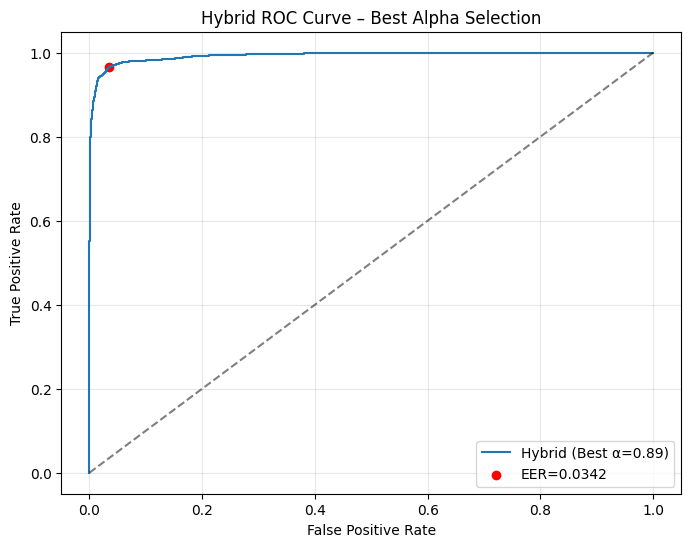

Results saved successfully at: D:\sp2-20240124T210502Z-001\sp2\BTP\TripleNet\ablation_results.json
[Loaded Model] Hybrid EER: 3.42% (thr=0.7130, α=0.89)

Final Hybrid Result: 3.42% ± 0.00% (across 1 runs)


In [33]:
import copy
import os
import json

MODEL_PATH = "best_model_imp_adaptiveTuned2.pth"    # where to save your best model
CONFIG_PATH = "model_config_imp_adaptiveTuned2.json"

def run_training(seed):
    print(f"\n===== Training with seed {seed} =====")
    set_seed(seed)

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    # --------------------------------------------------
    # If model already exists → load it and skip training
    # --------------------------------------------------
    if os.path.exists(MODEL_PATH):
        print("📌 Found saved model → Loading model instead of training...")
        num_classes = len(train_dataset_dw.indices_by_class)
        model = FingerprintTripleNet(feature_dim=256, num_classes=num_classes).to(device)
        model.load_state_dict(torch.load(MODEL_PATH, map_location=device))
        model.eval()

        eer, threshold, alpha, combined_score = compute_hybrid_eer_normalized(model, test_loader, device=device)

        title = f"Proposed"

        try:
            combined_score_serializable = combined_score.tolist()
        except Exception as e:
            print(f"Error converting combined_score to list: {e}")
            combined_score_serializable = None
        
        results_entry = {
            "EER_percent": float(eer),
            "threshold": float(threshold),
            "alpha": float(alpha),
            "combined_score": combined_score_serializable,
            "lambda_cls": float(lambda_cls),
            "lambda_semi": float(lambda_semi),
            "lambda_hard": float(lambda_hard),
            "margin_limit": float(margin_limit),
            "model_path": str(MODEL_PATH)
        }
        
        append_results(title, results_entry)
        print(f"[Loaded Model] Hybrid EER: {eer*100:.2f}% (thr={threshold:.4f}, α={alpha:.2f})")
        return eer * 100

    print("🚀 No saved model found → Training from scratch!")

    num_classes = len(train_dataset_dw.indices_by_class)
    model = FingerprintTripleNet(feature_dim=256, num_classes=num_classes).to(device)

    # --- compute pre-training distance stats (gap) using a fresh model ---
    try:
        stats = compute_distance_stats(model, train_dataset_dw, device=device, embed_batch_size=64, sample_limit=None)
    except Exception as e:
        print(f"[WARN] compute_distance_stats failed: {e}")
        stats = None

    if stats is None or "gap" not in stats or stats["gap"] <= 0.0:
        gap = 1e-4
        print("[WARN] Using fallback gap =", gap)
    else:
        gap = float(stats["gap"])
        print(f"[INFO] distance stats: {stats}")

    # Multipliers — sensible defaults (we keep these mutable for adaptation)
    hard_multiplier = 1
    semi_multiplier = 1

    # safety caps for multipliers to avoid runaway margins
    max_multiplier = 16.0
    adapt_factor = 1.5

    margin_hard = hard_multiplier * gap
    margin_semi = semi_multiplier * gap

    print(f"[INFO] initial margins -> hard: {margin_hard:.6e}, semi: {margin_semi:.6e}")

    optimizer = AdamW(model.parameters(), lr=1e-3, weight_decay=1e-5)

    # 🔥 Losses (enable logging in the loss objects if available)
    hard_criterion = HardTripletLoss(margin=margin_hard, log_stats=True)
    semi_criterion = SemiHardTripletLoss(margin=margin_semi, fallback_to_hard=False, log_stats=True)
    ce_criterion = nn.CrossEntropyLoss()

    # weights
    # lambda_hard=0.2
    # lambda_cls = 0.1    # classification weight (reduced to avoid CE domination)
    # lambda_semi = 1 # semi-hard weight
    # margin_limit = 0.5

    scaler = GradScaler("cuda")

    best_val_loss = float("inf")
    best_model_wts = copy.deepcopy(model.state_dict())
    patience = 5
    no_improve_count = 0

    # adaptive counter for consecutive epochs with no triplet signal
    no_triplet_signal_epochs = 0

    # -------------------------
    # Training loop (GLOBAL DW)
    # -------------------------
    for epoch in range(num_epochs):
        # --- recompute gap using current model before mining (costly but principled) ---
        model.eval()
        try:
            stats_epoch = compute_distance_stats(model, train_dataset_dw, device=device, embed_batch_size=64, sample_limit=None)
            print(stats_epoch)
        except Exception as e:
            print(f"[WARN] compute_distance_stats (epoch) failed: {e}")
            stats_epoch = None

        if stats_epoch is None or "gap" not in stats_epoch or stats_epoch["gap"] <= 0.0:
            # keep previous gap/margins if epoch stats invalid
            print(f"[EPOCH-{epoch+1}] could not recompute gap; keeping previous margins")
        else:
            gap = float(stats_epoch["gap"])
            # ensure minimal sensible multipliers to give semi-hard a chance
            hard_multiplier = max(hard_multiplier,1)
            semi_multiplier = max(semi_multiplier, 1)

            margin_hard = hard_multiplier * gap
            margin_semi = semi_multiplier * gap
            margin_hard = max(margin_hard, 1e-12)
            margin_semi = max(margin_semi, 1e-12)

            hard_criterion.margin = min(margin_hard,margin_limit)
            semi_criterion.margin = min(margin_semi,margin_limit)
            print(f"[EPOCH-{epoch+1}] recomputed gap: {gap:.6e}; margins -> hard: {hard_criterion.margin:.6e}, semi: {semi_criterion.margin:.6e}")

        # 1) Build global DW triplets for THIS epoch using current model (now using updated margins)
        triplet_loader = build_global_dw_triplet_loader(
            model,
            train_dataset_dw,
            device=device,
            embed_batch_size=64,
            triplet_batch_size=16,
            max_triplets_per_class=50,     # per class cap
            candidates_per_anchor=200,
            negatives_per_pair=4            # increase diversity
        )

        if triplet_loader is None:
            print("No triplets mined, skipping epoch.")
            continue

        # build_global_dw_triplet_loader already prints mined triplet count — no duplicate print here

        model.train()
        total_loss = 0.0
        valid_batches = 0

        # Accumulators for logging counts
        epoch_num_hard = 0
        epoch_num_semi = 0
        epoch_num_fallback = 0

        progress_bar = tqdm(
            triplet_loader,
            desc=f'Epoch {epoch+1} [GLOBAL-DW / Hard+Semi+CE]',
            leave=True
        )

        for batch in progress_bar:
            xa, ya, xp, yp, xn, yn = batch
            xa, xp, xn = xa.to(device), xp.to(device), xn.to(device)
            ya, yp, yn = ya.to(device), yp.to(device), yn.to(device)

            optimizer.zero_grad()
            with autocast("cuda"):
                # embeddings
                a_out = model.embed(xa)
                p_out = model.embed(xp)
                n_out = model.embed(xn)

                # triplet losses — robust to return types
                h_res = hard_criterion(a_out, p_out, n_out)
                if isinstance(h_res, tuple):
                    triplet_loss, num_hard = h_res
                else:
                    triplet_loss, num_hard = h_res, 0

                s_res = semi_criterion(a_out, p_out, n_out)
                if isinstance(s_res, tuple):
                    if len(s_res) == 3:
                        semi_loss, num_semi, num_fallback = s_res
                    else:
                        semi_loss, num_semi = s_res[0], s_res[1]
                        num_fallback = 0
                else:
                    semi_loss, num_semi, num_fallback = s_res, 0, 0

                # classification losses for all three
                logits_a = model.classifier(a_out)
                logits_p = model.classifier(p_out)
                logits_n = model.classifier(n_out)

                ce_loss = (
                    ce_criterion(logits_a, ya) +
                    ce_criterion(logits_p, yp) +
                    ce_criterion(logits_n, yn)
                ) / 3.0

                loss = lambda_hard*triplet_loss + lambda_semi * semi_loss + lambda_cls * ce_loss

            # backward / step with amp
            scaler.scale(loss).backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optimizer)
            scaler.update()

            # accumulate
            total_loss += loss.item()
            epoch_num_hard += int(num_hard)
            epoch_num_semi += int(num_semi)
            epoch_num_fallback += int(num_fallback)
            valid_batches += 1
            progress_bar.set_postfix({'Batch Loss': f'{loss.item():.4f}'})

        avg_train_loss = total_loss / max(valid_batches, 1)

        # -------------------------
        # Validation (unchanged)
        # -------------------------
        model.eval()
        val_loss = 0.0
        val_batches = 0

        all_pos = []
        all_neg = []

        with torch.no_grad():
            for batch in val_loader:
                if batch is None:
                    continue

                min1, dl1, min2, dl2, labels = batch
                dl1, dl2, labels = dl1.to(device), dl2.to(device), labels.to(device)

                emb1 = model.embed(dl1)
                emb2 = model.embed(dl2)

                dist = F.pairwise_distance(emb1, emb2)
                # batch_loss = (labels * dist + (1 - labels) * F.relu(1.0 - dist)).mean()
                all_pos.append(dist[labels == 1])
                all_neg.append(dist[labels == 0])

        # concatenate
        all_pos = torch.cat(all_pos)
        all_neg = torch.cat(all_neg)
        
        avg_val_loss = all_pos.mean() - all_neg.mean()


        # Epoch-level logging
        print(
            f"Epoch {epoch+1} [GLOBAL-DW / Hard+Semi+CE]: "
            f"Train Loss={avg_train_loss:.4f}, Val Loss={avg_val_loss:.4f}"
        )
        print(f"[LOG] semi-hard used: {epoch_num_semi}, fallback-hard: {epoch_num_fallback}, hard-negatives: {epoch_num_hard}")

        # -------------------------
        # ADAPTIVE multiplier if triplet signal vanished for a short run
        # -------------------------
        total_triplet_signal = epoch_num_semi + epoch_num_fallback + epoch_num_hard
        if total_triplet_signal == 0:
            no_triplet_signal_epochs += 1
        else:
            no_triplet_signal_epochs = 0

        # If no triplet signal for a couple of epochs, widen multipliers (but cap)
        if no_triplet_signal_epochs >= 1:
            old_hm, old_sm = hard_multiplier, semi_multiplier
            hard_multiplier = min(hard_multiplier * adapt_factor, max_multiplier)
            semi_multiplier = min(semi_multiplier * adapt_factor, max_multiplier)
            margin_hard = hard_multiplier * gap
            margin_semi = semi_multiplier * gap
            hard_criterion.margin = margin_hard
            semi_criterion.margin = margin_semi
            print(f"[ADAPT] triplet-signal empty for {no_triplet_signal_epochs} epoch(s) -> multipliers {old_hm:.2f}->{hard_multiplier:.2f}, {old_sm:.2f}->{semi_multiplier:.2f}")
            print(f"[ADAPT] new margins -> hard: {margin_hard:.6e}, semi: {margin_semi:.6e}")

        # -------------------------
        # Early Stopping Logic
        # -------------------------
        if avg_val_loss < best_val_loss - 1e-4:
            best_val_loss = avg_val_loss
            best_model_wts = copy.deepcopy(model.state_dict())
            no_improve_count = 0
            print(f"✅ New best model at epoch {epoch+1}")
        else:
            no_improve_count += 1
            print(f"⚠️ No improvement for {no_improve_count} epoch(s)")

        if no_improve_count >= patience:
            print(f"⏹ Early stopping triggered at epoch {epoch+1}")
            break

    # restore best
    model.load_state_dict(best_model_wts)

    # ============================
    #     SAVE THE MODEL
    # ============================
    torch.save(best_model_wts, MODEL_PATH)
    print(f"💾 Saved best model to {MODEL_PATH}")

    config = {
        "seed": seed,
        "epochs": num_epochs,
        "lambda_cls": lambda_cls,
        "lambda_semi": lambda_semi,
        "feature_dim": model.feature_dim
    }
    with open(CONFIG_PATH, "w") as f:
        json.dump(config, f, indent=4)
    print(f"📄 Saved config to {CONFIG_PATH}")

    # -------------------------
    # Final Evaluation
    # -------------------------
    
    eer, threshold, alpha, combined_score = compute_hybrid_eer_normalized(model, test_loader, device=device)
    print(f"Seed {seed} → Hybrid EER: {eer*100:.2f}% (Threshold: {threshold:.4f}, α={alpha:.2f})")

    title = f"Proposed"

    try:
        combined_score_serializable = combined_score.tolist()
    except Exception as e:
        print(f"Error converting combined_score to list: {e}")
        combined_score_serializable = None
    
    results_entry = {
        "EER_percent": float(eer),
        "threshold": float(threshold),
        "alpha": float(alpha),
        "combined_score": combined_score_serializable,
        "lambda_cls": float(lambda_cls),
        "lambda_semi": float(lambda_semi),
        "lambda_hard": float(lambda_hard),
        "margin_limit": float(margin_limit),
        "model_path": str(MODEL_PATH)
    }
    
    append_results(title, results_entry)

    return eer * 100



# =========================
# Run across multiple seeds
# =========================
seeds = [42]
num_epochs = 50

all_eers = []
for s in seeds:
    eer = run_training(s)
    all_eers.append(eer)

mean_eer = np.mean(all_eers)
std_eer = np.std(all_eers)
print(f"\nFinal Hybrid Result: {mean_eer:.2f}% ± {std_eer:.2f}% (across {len(seeds)} runs)")


In [3]:
labels = np.load("test_labels.npy")

In [25]:
import json
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve

# ---- Font settings (GLOBAL) ----
plt.rcParams.update({
    "font.size": 16,
    "axes.titlesize": 18,
    "axes.labelsize": 20,
    "legend.fontsize": 14,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12
})

RESULTS_PATH = "ablation_results.json"

def plot_proposed_roc_and_print_eer(labels, results_path=RESULTS_PATH):
    with open(results_path, "r") as f:
        results = json.load(f)
        # print(results)

    # ---- Extract ONLY Proposed ----
    assert "Full Model (Proposed)" in results, "Proposed entry not found in JSON"
    res = results["Full Model (Proposed)"]

    scores = np.array(res["combined_score"])
    assert len(scores) == len(labels), "Length mismatch in Proposed"

    # ---- ROC & EER ----
    fpr, tpr, thresholds = roc_curve(labels, scores)
    fnr = 1 - tpr
    eer_idx = np.nanargmin(np.abs(fpr - fnr))

    eer_from_roc = (fpr[eer_idx] + fnr[eer_idx]) / 2
    threshold = thresholds[eer_idx]

    # ---- PRINT ----
    print("\n=== PROPOSED EER VERIFICATION ===")
    print("Title           : Proposed")
    print(f"Stored EER      : {res['EER_percent']:.6f}")
    print(f"ROC-based EER   : {eer_from_roc:.6f}")
    print(f"EER Threshold   : {threshold:.6f}")
    print(f"Alpha           : {res['alpha']:.2f}")

    # ---- PLOT ----
    plt.figure(figsize=(8, 6))

    plt.plot(
        fpr,
        tpr,
        linewidth=2.5,
        label=f"α={res['alpha']:.2f}, EER={eer_from_roc*100:.2f}%"
    )

    plt.scatter(
        fpr[eer_idx],
        tpr[eer_idx],
        color="red",
        s=80,
        edgecolors="black",
        zorder=3,
        label="EER point"
    )

    plt.plot([0, 1], [0, 1], "k--", alpha=0.4)

    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")

    plt.legend(loc="lower right")
    plt.grid(True, alpha=0.3)
    plt.tight_layout()

    plt.savefig("EER_Proposed.pdf", format="pdf", bbox_inches="tight")
    plt.close()


# ---- LOAD LABELS ----
labels = np.load("test_labels.npy")

# ---- CALL FUNCTION ----
plot_proposed_roc_and_print_eer(labels)


=== PROPOSED EER VERIFICATION ===
Title           : Proposed
Stored EER      : 0.034210
ROC-based EER   : 0.034210
EER Threshold   : 0.712996
Alpha           : 0.89


In [26]:
plot_proposed_roc_and_print_eer(labels)


=== PROPOSED EER VERIFICATION ===
Title           : Proposed
Stored EER      : 0.034210
ROC-based EER   : 0.034210
EER Threshold   : 0.712996
Alpha           : 0.89


In [51]:
import numpy as np

labels = extract_labels_from_loader(test_loader)

np.save("test_labels.npy", labels)

print("Saved labels to test_labels.npy")

C:\Users\divya\AppData\Local\Temp\ipykernel_22340\477085210.py:83: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.tensor(dl1, dtype=torch.float32),
C:\Users\divya\AppData\Local\Temp\ipykernel_22340\477085210.py:85: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.tensor(dl2, dtype=torch.float32),
C:\Users\divya\AppData\Local\Temp\ipykernel_22340\1251142332.py:8: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  dl1_tensor = torch.stack([torch.tensor(x, dtype=torch.float32) for x in dl1_list])
C:\Users\divya\AppData\Local\Temp\ipykerne

Saved labels to test_labels.npy


In [52]:
labels = np.load("test_labels.npy")

In [53]:
len(labels)

83028

In [7]:
import json
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve

# ---- Font settings (GLOBAL) ----
plt.rcParams.update({
    "font.size": 16,
    "axes.titlesize": 18,
    "axes.labelsize": 16,
    "legend.fontsize": 10,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12
})

RESULTS_PATH = "ablation_results.json"

def plot_all_rocs_and_eer(labels, results_path=RESULTS_PATH):
    with open(results_path, "r") as f:
        results = json.load(f)

    plt.figure(figsize=(8, 6))

    print("\n=== EER VERIFICATION FOR ALL MODELS ===")

    for name, res in results.items():
        # Skip if required keys are missing
        if "combined_score" not in res:
            print(f"Skipping {name} (no combined_score)")
            continue

        scores = np.array(res["combined_score"])

        if len(scores) != len(labels):
            print(f"Skipping {name} (length mismatch)")
            continue

        # ---- ROC ----
        fpr, tpr, thresholds = roc_curve(labels, scores)
        fnr = 1 - tpr

        eer_idx = np.nanargmin(np.abs(fpr - fnr))
        eer = (fpr[eer_idx] + fnr[eer_idx]) / 2
        threshold = thresholds[eer_idx]

        # ---- PRINT ----
        print(f"\nTitle           : {name}")
        print(f"Stored EER      : {res.get('EER_percent', 'N/A')}")
        print(f"ROC-based EER   : {eer:.6f}")
        print(f"EER Threshold   : {threshold:.6f}")
        if "alpha" in res:
            print(f"Alpha           : {res['alpha']:.2f}")

        # ---- LABEL TEXT ----
        label_text = f"{name} (EER={eer*100:.2f}%)"
        if "alpha" in res:
            label_text = f"{name} | α={res['alpha']:.2f} (EER={eer*100:.2f}%)"

        # ---- PLOT ----
        plt.plot(fpr, tpr, linewidth=2, label=label_text)

        # Mark EER point
        plt.scatter(
            fpr[eer_idx],
            tpr[eer_idx],
            s=50,
            edgecolors="black",
            zorder=3
        )

    # ---- FINAL TOUCHES ----
    plt.plot([0, 1], [0, 1], "k--", alpha=0.4)

    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.legend(loc="lower right")
    plt.grid(True, alpha=0.3)
    plt.tight_layout()

    plt.savefig("ROC_All_Models.pdf", format="pdf", bbox_inches="tight")
    plt.close()


# ---- LOAD LABELS ----
labels = np.load("test_labels.npy")

# ---- CALL FUNCTION ----
plot_all_rocs_and_eer(labels)


=== EER VERIFICATION FOR ALL MODELS ===

Title           : No Semi-Hard Triplet Mining
Stored EER      : 0.048818407960199026
ROC-based EER   : 0.048818
EER Threshold   : 0.592154
Alpha           : 0.68

Title           : No Auxiliary Classification Head
Stored EER      : 0.061989074236659836
ROC-based EER   : 0.061989
EER Threshold   : 0.572773
Alpha           : 0.64

Title           : No Hard Triplet Mining
Stored EER      : 0.03451614476636425
ROC-based EER   : 0.034516
EER Threshold   : 0.758766
Alpha           : 0.95

Title           : Fixed Margin Loss
Stored EER      : 0.056654228855721404
ROC-based EER   : 0.056654
EER Threshold   : 0.498450
Alpha           : 0.51

Title           : Random Triplet Sampling
Stored EER      : 0.044099356160374574
ROC-based EER   : 0.044099
EER Threshold   : 0.632904
Alpha           : 0.72

Title           : Single-Channel Thinned Input
Stored EER      : 0.04510779436152568
ROC-based EER   : 0.045108
EER Threshold   : 0.726728
Alpha           : 0